# Developmental Project - Main
- Computation of S-A axis and features of S-A axis development
-  Plotting (Figures 1 & 2)
-  FC strength computation

## Load Packages

In [1]:
# General
import os
import sys
import numpy as np
import pandas as pd
import csv
import math
from math import isnan
import statistics
import pickle
from collections import Counter

# Computing / Analyses
import scipy.io  # loadmat
import hdf5storage  # hdf5storage to write in HDF5 format (instead of .mat file, when matrix is too large) -> hdf5storage.write() hdf5storage.read()
import fnmatch # for comparing patterns of syntax
from scipy import stats
import sklearn 
from brainstat.stats.terms import FixedEffect
from brainstat.stats.SLM import SLM
from statsmodels.stats.multitest import fdrcorrection # does not yield exactly the same FDR correction as R but the same up to 14th decimal place so good enough
import statsmodels.regression.mixed_linear_model as sm
from sklearn.preprocessing import scale

# Visualisation
import matplotlib.pyplot as plt 
import seaborn as sns
import vtk
from IPython.display import display
import matplotlib.collections as clt
import matplotlib.colors as mcolors
#import ptitprince as pt  # commented out because clashing dependencies with seaborn

# Neuroimaging
import nibabel as nib
import nilearn
from brainstat.datasets import fetch_parcellation
from enigmatoolbox.permutation_testing import spin_test, shuf_test

# Gradients
import brainspace
from brainspace.datasets import load_parcellation, load_conte69
from brainspace.plotting import plot_hemispheres
from brainspace.gradient import GradientMaps
from brainspace.utils.parcellation import map_to_labels

## Define directories

In [49]:
codedir = os.path.abspath('')  # obtain current direction from which script is runnning

datadir_local = '/data/p_02667/development/data/'
datadir_local_pds_cleaned = '/data/p_02667/development/data/pds_cleaned/'
datadir = '/data/pt_02667/data/ABCD/'

resdir = '/data/p_02667/development/results/'
resdir_fig = '/data/p_02667/development/results/figures/'

## Import functions

In [3]:
%run p3_myfunctions.ipynb

# Data 

## Import the Yeo 7 network coding for the Schaefer 400 parcellation scheme

In [4]:
# labels: 1=visual, 2=sensory motor, 3=dorsal attention, 4=ventral attention, 5=limbic, 6=fronto parietal, 7= DMN

yeo7_networks_array = np.genfromtxt('/data/pt_02667/data/yeo_7.csv', delimiter=',', skip_header=0)

### Define custom yeo 7 colormap

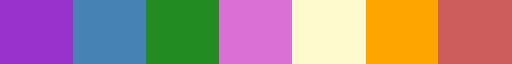

In [5]:
from matplotlib.colors import ListedColormap

# define custom colormap using color names (in order of corresponding networks: 1 visual, 2 sensorimotor, 3 dorsal attention, 4 ventral attention, 5 limbic, 6 fronto parietal, 7 DMN)
colors_yeo7 = ['darkorchid', 'steelblue', 'forestgreen', 'orchid', 'lemonchiffon', 'orange',  'indianred']

yeo7_colormap = ListedColormap(colors_yeo7, 'custom_colormap')

yeo7_colormap

In [6]:
# original Yeo network colors
palette_labeled_networks = {'DMN': 'indianred',  
                            'dorsal attention' : 'forestgreen',  
                            'fronto parietal' : 'orange',  
                            'limbic' : 'lemonchiffon',  
                            'sensory motor' : 'steelblue',
                            'ventral attention' : 'orchid', 
                            'visual' : 'darkorchid'} 

# making an array with yeo network labels (names instead of numbers)
yeo7_networks_array_labels = []

for i in yeo7_networks_array:
    if i == 1:
        yeo7_networks_array_labels.append('visual')
    elif i == 2:
        yeo7_networks_array_labels.append('sensory motor')
    elif i == 3:
        yeo7_networks_array_labels.append('dorsal attention')
    elif i == 4:
        yeo7_networks_array_labels.append('ventral attention')
    elif i == 5:
        yeo7_networks_array_labels.append('limbic')
    elif i == 6:
        yeo7_networks_array_labels.append('fronto parietal')
    elif i == 7:
        yeo7_networks_array_labels.append('DMN')

yeo7_networks_array_labels = np.asarray(yeo7_networks_array_labels)

network_names = ["visual", "sensory motor", "dorsal attention", "ventral attention", "limbic", "fronto parietal", "DMN"]

print("Number of parcels in each Yeo network:")
for i in range(len(network_names)):
    print(f"- {network_names[i]}: {yeo7_networks_array_labels.tolist().count(network_names[i])}")

Number of parcels in each Yeo network:
- visual: 61
- sensory motor: 77
- dorsal attention: 46
- ventral attention: 47
- limbic: 26
- fronto parietal: 53
- DMN: 90


## Fetch fsaverage parcellation (20484 vertices) coded for Schaefer 400 parcels 
**NOTE: schaefer_400_fs5 == 0 corresponds to midline (labels go from 0-400) -> disregard 0 in calculations and plotting**

In [7]:
# fetch the fsaverage parcellation labeling each of fsaverage5's 20484 vertices with its corresponding Schaefer parcel
schaefer_400_fs5 = fetch_parcellation("fsaverage5", "schaefer", 400)

In [8]:
schaefer_400_fs5.shape

(20484,)

## Fetch subject lists

## HCP adult gradients (G1 / S-A axis) + sex effects

### Margulies gradient G1

In [9]:
Margulies_gradients_fsa5 = []
Margulies_gradients_schaefer400 = []

# Margulies published first 5 gradients
for i in range(1,6):

    # load left and right hemispheres (.agg_data() makes the Gifti format accessible) -> shape per hemi is 10242
    Margulies_fsa5_grad_L = nib.load('/data/p_02667/development/data/Gradients_Margulies2016/Gradients_Margulies2016/fsaverage/hcp.embed.grad_'+str(i)+'.L.fsa5.func.gii').agg_data()
    Margulies_fsa5_grad_R = nib.load('/data/p_02667/development/data/Gradients_Margulies2016/Gradients_Margulies2016/fsaverage/hcp.embed.grad_'+str(i)+'.R.fsa5.func.gii').agg_data()


    # concatenate left and right hemispheres - this data is shaped (20484), corresponding to vertices (including medial wall)
    Margulies_fsa5_grad_wholebrain = np.concatenate((Margulies_fsa5_grad_L, Margulies_fsa5_grad_R), axis=0)

    # append to list
    Margulies_gradients_fsa5.append(Margulies_fsa5_grad_wholebrain)

    # transform to Schaefer parcellation and append to list
    Margulies_gradients_schaefer400.append(fs5_to_schaefer400(Margulies_fsa5_grad_wholebrain, seven_networks=True))


Margulies_gradients_fsa5 = np.array(Margulies_gradients_fsa5)
Margulies_gradients_schaefer400 = np.array(Margulies_gradients_schaefer400)

In [10]:
Margulies_gradients_fsa5.shape

(5, 20484)

In [11]:
Margulies_gradients_schaefer400.T.shape

(400, 5)

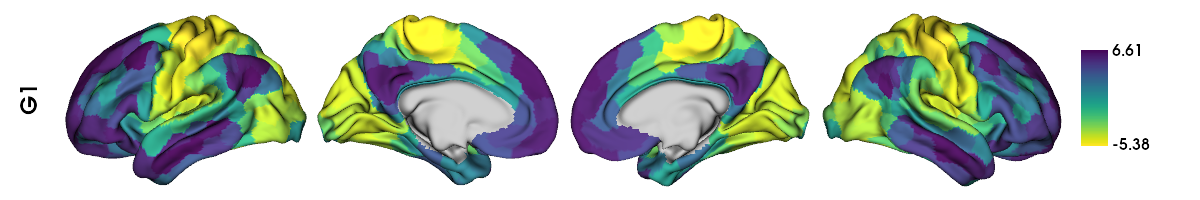

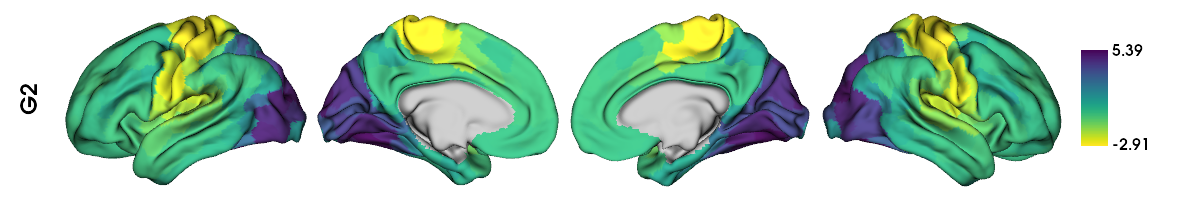

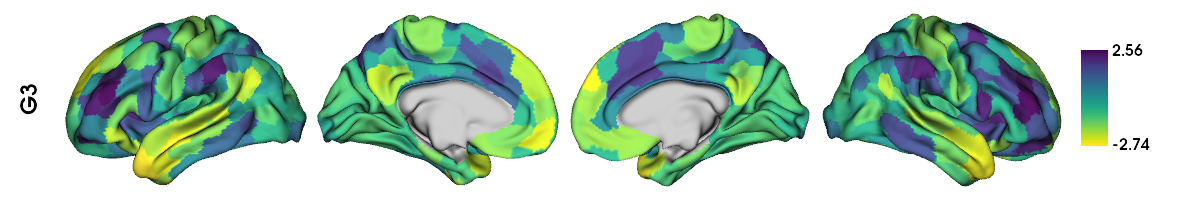

In [12]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

for i in range(3):
    # map the gradient to the parcels
    grad = map_to_labels(Margulies_gradients_schaefer400[i], labeling, mask=mask, fill=np.nan)

    plot = plot_hemispheres(surf_lh, 
                            surf_rh, 
                            array_name=grad, 
                            embed_nb = True, 
                            size=(1200, 200),
                            cmap='viridis_r', 
                            nan_color = (0.7, 0.7, 0.7, 1),
                            color_bar=True, 
                            label_text=[f'G{i+1}'], 
                            zoom=1.55,
                            screenshot = False,
                            filename = resdir_fig+'_plotted_hemispheres_TO_DEFINE.png')

    display(plot)

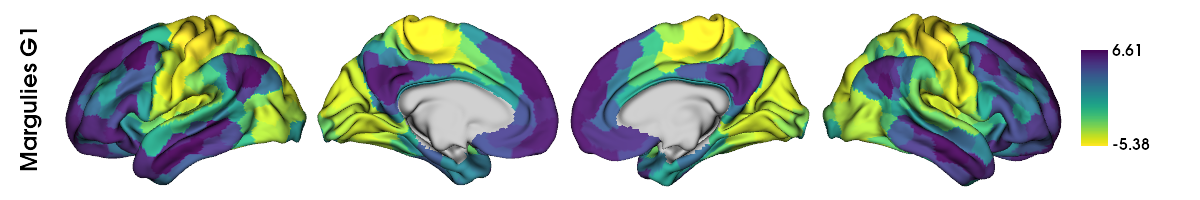

In [13]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = map_to_labels(Margulies_gradients_schaefer400[0], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        #color_range = (min_loading_across_all_G1, max_loading_across_all_G1),
                        label_text=['Margulies G1'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_ref_Margulies_SAaxis.svg')

display(plot)

## Cleaned FC matrices

From p3_cleaning_final_sample.py

### Baseline

In [14]:
## This is current largest sample

# Loading HDF file (file was too large for matfile), with HDF reader e.g., hdf5storage
hdf_file_fc_matrices_baseline_clean = hdf5storage.read(filename=datadir_local+'abcd_fc_matrices_baseline_clean.h5')
hdf_file_fc_matrices_baseline_clean.keys()

dict_keys(['fc_matrices_baseline', 'fc_matrices_baseline_z', 'sub_ID_baseline'])

In [15]:
fc_matrices_baseline = hdf_file_fc_matrices_baseline_clean['fc_matrices_baseline_z']   # take r-to-z transformed matrices
sub_ID_baseline = hdf_file_fc_matrices_baseline_clean['sub_ID_baseline']

fc_matrices_baseline.shape

(4064, 400, 400)

### 2y follow-up

In [16]:
## This is current largest sample

# Loading HDF file (file was too large for matfile), with HDF reader e.g., hdf5storage
hdf_file_fc_matrices_fu2y_clean = hdf5storage.read(filename=datadir_local+'abcd_fc_matrices_fu2y_clean.h5')
hdf_file_fc_matrices_fu2y_clean.keys()

dict_keys(['fc_matrices_fu2y', 'fc_matrices_fu2y_z', 'sub_ID_fu2y'])

In [17]:
fc_matrices_fu2y = hdf_file_fc_matrices_fu2y_clean['fc_matrices_fu2y_z']  # take r-to-z transformed matrices
sub_ID_fu2y = hdf_file_fc_matrices_fu2y_clean['sub_ID_fu2y']

fc_matrices_fu2y.shape

(1296, 400, 400)

### 4y follow-up

In [18]:
## This is current largest sample

# Loading HDF file (file was too large for matfile), with HDF reader e.g., hdf5storage
hdf_file_fc_matrices_fu4y_clean = hdf5storage.read(filename=datadir_local+'abcd_fc_matrices_fu4y_clean.h5')
hdf_file_fc_matrices_fu4y_clean.keys()

dict_keys(['fc_matrices_fu4y', 'fc_matrices_fu4y_z', 'sub_ID_fu4y'])

In [19]:
fc_matrices_fu4y = hdf_file_fc_matrices_fu4y_clean['fc_matrices_fu4y_z']  # take r-to-z transformed matrices
sub_ID_fu4y = hdf_file_fc_matrices_fu4y_clean['sub_ID_fu4y']

fc_matrices_fu4y.shape

(963, 400, 400)

### full -> too large - crashes

### full (all) -> make it by hand by concatenating the above

In [20]:
fc_matrices_all = np.concatenate((fc_matrices_baseline, fc_matrices_fu2y, fc_matrices_fu4y), axis=0) 
fc_matrices_all.shape

(6323, 400, 400)

In [21]:
sub_ID_all = np.concatenate((sub_ID_baseline, sub_ID_fu2y, sub_ID_fu4y))
sub_ID_all.shape

(6323,)

## Sample

### Baseline

In [22]:
# Load puberty and demographics data
abcd_demo_baseline_clean = pd.read_csv(datadir_local+'abcd_demo_baseline_clean.csv')

In [23]:
# Safety check that sub ID list and demographics subjects are identical (order and elements) - this was done in the cleaning step normally
np.array_equal(np.array(sub_ID_baseline), np.array(abcd_demo_baseline_clean.src_subject_id_fmt))

True

In [24]:
abcd_demo_baseline_clean

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMIz,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y
0,sub-NDARINV003RTV85,10.0,F,13.0,baseline_year_1_arm_1,site06,8781.0,131.0,3.0,3.0,1.60,2.4,0.961662,188827.953554,4.0,1.0,1.0,3.0
1,sub-NDARINV007W6H7B,10.0,M,19.0,baseline_year_1_arm_1,site22,4722.0,126.0,2.0,1.0,1.50,1.0,0.550824,233329.288961,23.0,8.0,2.0,0.0
2,sub-NDARINV00J52GPG,9.0,M,21.0,baseline_year_1_arm_1,site17,4151.0,110.0,2.0,2.0,1.40,1.6,1.129072,201853.751338,11.0,0.0,1.0,0.0
3,sub-NDARINV00LH735Y,9.0,M,13.0,baseline_year_1_arm_1,site03,6069.0,109.0,1.0,1.0,1.00,1.4,1.570677,204865.644678,8.0,4.0,2.0,0.0
4,sub-NDARINV00NPMHND,9.0,F,18.0,baseline_year_1_arm_1,site17,4152.0,118.0,2.0,3.0,1.50,1.8,0.363954,212433.396427,42.0,23.0,3.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4059,sub-NDARINVZZ6ZJ2KY,10.0,F,18.0,baseline_year_1_arm_1,site06,9345.0,124.0,3.0,3.0,2.00,2.2,1.702236,177613.660710,20.0,0.0,9.0,1.0
4060,sub-NDARINVZZ81LEEV,9.0,M,15.0,baseline_year_1_arm_1,site11,8433.0,108.0,2.0,2.0,1.40,1.6,-1.418958,207555.526432,13.0,2.0,1.0,6.0
4061,sub-NDARINVZZFG6J5U,10.0,F,19.0,baseline_year_1_arm_1,site04,2568.0,129.0,3.0,2.0,2.25,1.6,2.629741,202282.483752,79.0,39.0,12.0,3.0
4062,sub-NDARINVZZNX6W2P,10.0,M,18.0,baseline_year_1_arm_1,site14,3797.0,131.0,1.0,1.0,1.20,1.0,-0.395219,179263.352104,15.0,4.0,7.0,0.0


In [25]:
print(f"{np.sum(abcd_demo_baseline_clean.sex == 'F')} females, {np.sum(abcd_demo_baseline_clean.sex == 'M')} males")

2105 females, 1959 males


### 2y follow-up

In [26]:
# Load puberty and demographics data
abcd_demo_fu2y_clean = pd.read_csv(datadir_local+'abcd_demo_fu2y_clean.csv')

In [27]:
# Safety check that sub ID list and demographics subjects are identical (order and elements) - this was done in the cleaning step normally
np.array_equal(np.array(sub_ID_fu2y), np.array(abcd_demo_fu2y_clean.src_subject_id_fmt))

True

In [28]:
abcd_demo_fu2y_clean

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMIz,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y
0,sub-NDARINV00CY2MDM,10.0,M,15.0,2_year_follow_up_y_arm_1,site20,5355.0,152.0,2.0,3.0,1.6,2.2,0.735892,189608.041081,46.0,9.0,25.0,1.0
1,sub-NDARINV00HEV6HB,10.0,M,13.0,2_year_follow_up_y_arm_1,site12,2257.0,149.0,3.0,2.0,2.4,1.8,-0.617092,178850.368164,29.0,5.0,14.0,0.0
2,sub-NDARINV01NAYMZH,10.0,M,18.0,2_year_follow_up_y_arm_1,site16,862.0,153.0,3.0,2.0,2.6,1.8,0.043811,200736.857515,3.0,0.0,1.0,3.0
3,sub-NDARINV01RGTWD2,9.0,F,19.0,2_year_follow_up_y_arm_1,site02,11327.0,135.0,3.0,3.0,1.8,1.6,-0.517889,176978.759778,37.0,13.0,11.0,0.0
4,sub-NDARINV021403LF,9.0,M,19.0,2_year_follow_up_y_arm_1,site05,470.0,131.0,1.0,1.0,1.4,1.6,1.270155,201284.441896,11.0,1.0,3.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1291,sub-NDARINVZUXFF006,9.0,F,21.0,2_year_follow_up_y_arm_1,site12,1851.0,134.0,2.0,2.0,1.6,1.6,0.541296,183254.429205,2.0,0.0,2.0,1.0
1292,sub-NDARINVZWE6CD6Y,10.0,M,16.0,2_year_follow_up_y_arm_1,site13,8301.0,144.0,3.0,2.0,2.2,1.8,-0.045959,190035.640485,31.0,3.0,10.0,6.0
1293,sub-NDARINVZXF5C635,10.0,F,19.0,2_year_follow_up_y_arm_1,site06,9344.0,146.0,3.0,3.0,2.4,2.6,0.253033,195177.892501,33.0,10.0,8.0,1.0
1294,sub-NDARINVZZNX6W2P,10.0,M,18.0,2_year_follow_up_y_arm_1,site14,3797.0,156.0,2.0,1.0,1.4,1.2,-0.304549,177415.148463,13.0,1.0,6.0,2.0


In [29]:
print(f"{np.sum(abcd_demo_fu2y_clean.sex == 'F')} females, {np.sum(abcd_demo_fu2y_clean.sex == 'M')} males")

654 females, 642 males


### 4y follow-up

In [30]:
# Load puberty and demographics data
abcd_demo_fu4y_clean = pd.read_csv(datadir_local+'abcd_demo_fu4y_clean.csv')

In [31]:
# Safety check that sub ID list and demographics subjects are identical (order and elements) - this was done in the cleaning step normally
np.array_equal(np.array(sub_ID_fu4y), np.array(abcd_demo_fu4y_clean.src_subject_id_fmt))

True

In [32]:
abcd_demo_fu4y_clean

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMIz,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y
0,sub-NDARINV02EBX0JJ,9.0,M,17.0,4_year_follow_up_y_arm_1,site02,11873.0,168.0,3.0,3.0,2.8,2.80,-0.037103,179791.049460,20.0,5.0,5.0,2.0
1,sub-NDARINV0387TP8R,9.0,M,21.0,4_year_follow_up_y_arm_1,site20,5358.0,160.0,3.0,3.0,2.8,2.80,0.508041,199571.441115,8.0,4.0,2.0,0.0
2,sub-NDARINV07XXFHDK,10.0,M,18.0,4_year_follow_up_y_arm_1,site06,8788.0,171.0,4.0,4.0,3.2,3.60,1.355655,231790.922914,0.0,0.0,0.0,0.0
3,sub-NDARINV08R2PTT1,10.0,M,18.0,4_year_follow_up_y_arm_1,site21,4723.0,181.0,3.0,NaN,2.8,3.25,0.503497,211828.877153,26.0,8.0,7.0,4.0
4,sub-NDARINV09T2EBX4,9.0,F,16.0,4_year_follow_up_y_arm_1,site13,7614.0,159.0,4.0,4.0,3.0,3.00,1.159164,188029.592484,3.0,2.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
958,sub-NDARINVZYC44GB8,10.0,M,21.0,4_year_follow_up_y_arm_1,site16,1840.0,179.0,4.0,4.0,3.0,3.00,-0.503814,206655.702684,0.0,0.0,0.0,0.0
959,sub-NDARINVZYRTFYRP,9.0,M,13.0,4_year_follow_up_y_arm_1,site10,10925.0,164.0,1.0,3.0,1.6,2.60,-0.428811,173346.170313,20.0,4.0,5.0,1.0
960,sub-NDARINVZZ1MNPK5,10.0,F,20.0,4_year_follow_up_y_arm_1,site08,7031.0,175.0,5.0,4.0,3.6,3.60,-0.500384,171459.001848,20.0,13.0,2.0,0.0
961,sub-NDARINVZZ81LEEV,9.0,M,15.0,4_year_follow_up_y_arm_1,site11,8433.0,157.0,2.0,2.0,1.2,1.80,-1.408592,202083.016847,6.0,3.0,0.0,0.0


In [33]:
print(f"{np.sum(abcd_demo_fu4y_clean.sex == 'F')} females, {np.sum(abcd_demo_fu4y_clean.sex == 'M')} males")

461 females, 502 males


### Full sample

In [34]:
# Concatenate dataframes
abcd_demo_all_clean = pd.concat([abcd_demo_baseline_clean, abcd_demo_fu2y_clean, abcd_demo_fu4y_clean], axis=0)
abcd_demo_all_clean

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMIz,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y
0,sub-NDARINV003RTV85,10.0,F,13.0,baseline_year_1_arm_1,site06,8781.0,131.0,3.0,3.0,1.6,2.4,0.961662,188827.953554,4.0,1.0,1.0,3.0
1,sub-NDARINV007W6H7B,10.0,M,19.0,baseline_year_1_arm_1,site22,4722.0,126.0,2.0,1.0,1.5,1.0,0.550824,233329.288961,23.0,8.0,2.0,0.0
2,sub-NDARINV00J52GPG,9.0,M,21.0,baseline_year_1_arm_1,site17,4151.0,110.0,2.0,2.0,1.4,1.6,1.129072,201853.751338,11.0,0.0,1.0,0.0
3,sub-NDARINV00LH735Y,9.0,M,13.0,baseline_year_1_arm_1,site03,6069.0,109.0,1.0,1.0,1.0,1.4,1.570677,204865.644678,8.0,4.0,2.0,0.0
4,sub-NDARINV00NPMHND,9.0,F,18.0,baseline_year_1_arm_1,site17,4152.0,118.0,2.0,3.0,1.5,1.8,0.363954,212433.396427,42.0,23.0,3.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
958,sub-NDARINVZYC44GB8,10.0,M,21.0,4_year_follow_up_y_arm_1,site16,1840.0,179.0,4.0,4.0,3.0,3.0,-0.503814,206655.702684,0.0,0.0,0.0,0.0
959,sub-NDARINVZYRTFYRP,9.0,M,13.0,4_year_follow_up_y_arm_1,site10,10925.0,164.0,1.0,3.0,1.6,2.6,-0.428811,173346.170313,20.0,4.0,5.0,1.0
960,sub-NDARINVZZ1MNPK5,10.0,F,20.0,4_year_follow_up_y_arm_1,site08,7031.0,175.0,5.0,4.0,3.6,3.6,-0.500384,171459.001848,20.0,13.0,2.0,0.0
961,sub-NDARINVZZ81LEEV,9.0,M,15.0,4_year_follow_up_y_arm_1,site11,8433.0,157.0,2.0,2.0,1.2,1.8,-1.408592,202083.016847,6.0,3.0,0.0,0.0


In [35]:
print(f"{np.sum(abcd_demo_all_clean.sex == 'F')} females, {np.sum(abcd_demo_all_clean.sex == 'M')} males")

3220 females, 3103 males


#### Identifying subjects with impossible PDS (decreasing with age)

In [38]:
def pds_direction_check(g):
    #g = g.dropna()
    age = g['age_months'].to_numpy()
    pds = g['pds_p_score'].to_numpy()
    
    # Sign of change for every pair of visits (+1 up, -1 down, 0 no change)
    d_age = np.sign(age[:, None] - age[None, :])
    d_pds = np.sign(pds[:, None] - pds[None, :])
    agree = d_age * d_pds        # +1 same direction, -1 opposite, 0 one didn't change
    
    return pd.Series({
        'non_decreasing': (agree >= 0).all(),                   # PDS never goes down as age goes up
        'strictly_increasing': (agree[d_age != 0] > 0).all(),   # PDS always goes up as age goes up
    })

check = (abcd_demo_all_clean
         .groupby('src_subject_id_fmt', sort=False)[['age_months', 'pds_p_score']]
         .apply(pds_direction_check))


impossible_pds_subjects = check.index[~check['non_decreasing']]
print(f"Number of subjects with PDS going the opposite way to age: {len(impossible_pds_subjects)}")
print(f"Number of rows/datapoints to exclude (all belonging to subjects with impossible PDS): {len(abcd_demo_all_clean[abcd_demo_all_clean['src_subject_id_fmt'].isin(impossible_pds_subjects)])}")


Number of subjects with PDS going the opposite way to age: 63
Number of rows/datapoints to exclude (all belonging to subjects with impossible PDS): 152


In [39]:
impossible_pds_subjects

Index(['sub-NDARINV0P3ERKVG', 'sub-NDARINV1CGKKTM5', 'sub-NDARINV1CYTVBWT',
       'sub-NDARINV2BPVXTH3', 'sub-NDARINV2J8WHJ3R', 'sub-NDARINV2V8997BF',
       'sub-NDARINV3UNMBY32', 'sub-NDARINV4C8YJ9BG', 'sub-NDARINV4FBVLRNU',
       'sub-NDARINV4LPXB23R', 'sub-NDARINV52K3HFFN', 'sub-NDARINV61RKCL4Y',
       'sub-NDARINV6JF8WUYT', 'sub-NDARINV7JUL4TDF', 'sub-NDARINV7W4K75L0',
       'sub-NDARINV7YZP2ZNL', 'sub-NDARINV8E3TY3RU', 'sub-NDARINV8Y8A8NU0',
       'sub-NDARINV9Z6E4FXG', 'sub-NDARINV9ZFFC49P', 'sub-NDARINVB5VK9XEN',
       'sub-NDARINVB7CUAZH9', 'sub-NDARINVBR0R4R8M', 'sub-NDARINVBWFE6KU6',
       'sub-NDARINVCKTT8HAT', 'sub-NDARINVCX7YWXVP', 'sub-NDARINVE1MRKJ3N',
       'sub-NDARINVEBFULY5Y', 'sub-NDARINVGALZWY31', 'sub-NDARINVGF5M5HN2',
       'sub-NDARINVH3WNU4JB', 'sub-NDARINVH9ERT7NK', 'sub-NDARINVHXY3TJAT',
       'sub-NDARINVJNDY0DWK', 'sub-NDARINVKJDAZKWA', 'sub-NDARINVL5EAF5N9',
       'sub-NDARINVLBJ8E0XH', 'sub-NDARINVLRNZXLDX', 'sub-NDARINVM5F9LGBU',
       'sub-

In [40]:
# VISUALLY CHECKING TO MAKE SURE THE pds_direction_check() worked properly -> confirmed
for i in range(len(impossible_pds_subjects)):
    bad_rows = abcd_demo_all_clean[
        abcd_demo_all_clean['src_subject_id_fmt']==(impossible_pds_subjects[i])]
    
    print(bad_rows[['src_subject_id_fmt', 'age_months', 'pds_p_score']])
    print('')

      src_subject_id_fmt  age_months  pds_p_score
106  sub-NDARINV0P3ERKVG       108.0          1.4
19   sub-NDARINV0P3ERKVG       154.0          1.0

      src_subject_id_fmt  age_months  pds_p_score
204  sub-NDARINV1CGKKTM5       112.0          1.4
64   sub-NDARINV1CGKKTM5       138.0          1.0
40   sub-NDARINV1CGKKTM5       159.0          2.8

      src_subject_id_fmt  age_months  pds_p_score
206  sub-NDARINV1CYTVBWT       124.0          3.4
65   sub-NDARINV1CYTVBWT       165.0          2.5

      src_subject_id_fmt  age_months  pds_p_score
327  sub-NDARINV2BPVXTH3       124.0          1.4
114  sub-NDARINV2BPVXTH3       148.0          1.2
77   sub-NDARINV2BPVXTH3       170.0          2.6

      src_subject_id_fmt  age_months  pds_p_score
352  sub-NDARINV2J8WHJ3R       108.0          1.4
120  sub-NDARINV2J8WHJ3R       130.0          1.0

      src_subject_id_fmt  age_months  pds_p_score
394  sub-NDARINV2V8997BF       116.0          1.2
132  sub-NDARINV2V8997BF       140.0         

#### Removing subjects with impossible PDS (decreasing with age)

##### From full sample

In [41]:
# Mask for the dataframe
keep_df = ~abcd_demo_all_clean['src_subject_id_fmt'].isin(impossible_pds_subjects).to_numpy()

# Mask for the ID array (which defines the order of fc_matrices_all)
keep_fc = ~np.isin(sub_ID_all, impossible_pds_subjects)

print(f"Number of subjects before removal: {len(sub_ID_all)}")

# Apply
abcd_demo_all_clean = abcd_demo_all_clean[keep_df].reset_index(drop=True)
sub_ID_all = sub_ID_all[keep_fc]
fc_matrices_all = fc_matrices_all[keep_fc]

# Sanity checks
print(f"Number of subjects after removal: {len(sub_ID_all)}")
print(f"Rows removed from df: {(~keep_df).sum()}, from FC array: {(~keep_fc).sum()}")
print(f"Lengths of demographics df and FC matrices array and subjects array match: {len(abcd_demo_all_clean) == fc_matrices_all.shape[0] == len(sub_ID_all)}")
print(f"Demographics df subjects and FC subjects match: {(abcd_demo_all_clean['src_subject_id_fmt'].to_numpy() == sub_ID_all).all()}")

Number of subjects before removal: 6323
Number of subjects after removal: 6171
Rows removed from df: 152, from FC array: 152
Lengths of demographics df and FC matrices array and subjects array match: True
Demographics df subjects and FC subjects match: True


##### From baseline

In [42]:
# Mask for the dataframe
keep_df = ~abcd_demo_baseline_clean['src_subject_id_fmt'].isin(impossible_pds_subjects).to_numpy()

# Mask for the ID array (which defines the order of fc_matrices_baseline)
keep_fc = ~np.isin(sub_ID_baseline, impossible_pds_subjects)

print(f"Number of subjects before removal: {len(sub_ID_baseline)}")

# Apply
abcd_demo_baseline_clean = abcd_demo_baseline_clean[keep_df].reset_index(drop=True)
sub_ID_baseline = sub_ID_baseline[keep_fc]
fc_matrices_baseline = fc_matrices_baseline[keep_fc]

# Sanity checks
print(f"Number of subjects after removal: {len(sub_ID_baseline)}")
print(f"Rows removed from df: {(~keep_df).sum()}, from FC array: {(~keep_fc).sum()}")
print(f"Lengths of demographics df and FC matrices array and subjects array match: {len(abcd_demo_baseline_clean) == fc_matrices_baseline.shape[0] == len(sub_ID_baseline)}")
print(f"Demographics df subjects and FC subjects match: {(abcd_demo_baseline_clean['src_subject_id_fmt'].to_numpy() == sub_ID_baseline).all()}")

Number of subjects before removal: 4064
Number of subjects after removal: 4007
Rows removed from df: 57, from FC array: 57
Lengths of demographics df and FC matrices array and subjects array match: True
Demographics df subjects and FC subjects match: True


##### From fu2y

In [43]:
# Mask for the dataframe
keep_df = ~abcd_demo_fu2y_clean['src_subject_id_fmt'].isin(impossible_pds_subjects).to_numpy()

# Mask for the ID array (which defines the order of fc_matrices_fu2y)
keep_fc = ~np.isin(sub_ID_fu2y, impossible_pds_subjects)

print(f"Number of subjects before removal: {len(sub_ID_fu2y)}")

# Apply
abcd_demo_fu2y_clean = abcd_demo_fu2y_clean[keep_df].reset_index(drop=True)
sub_ID_fu2y = sub_ID_fu2y[keep_fc]
fc_matrices_fu2y = fc_matrices_fu2y[keep_fc]

# Sanity checks
print(f"Number of subjects after removal: {len(sub_ID_fu2y)}")
print(f"Rows removed from df: {(~keep_df).sum()}, from FC array: {(~keep_fc).sum()}")
print(f"Lengths of demographics df and FC matrices array and subjects array match: {len(abcd_demo_fu2y_clean) == fc_matrices_fu2y.shape[0] == len(sub_ID_fu2y)}")
print(f"Demographics df subjects and FC subjects match: {(abcd_demo_fu2y_clean['src_subject_id_fmt'].to_numpy() == sub_ID_fu2y).all()}")

Number of subjects before removal: 1296
Number of subjects after removal: 1235
Rows removed from df: 61, from FC array: 61
Lengths of demographics df and FC matrices array and subjects array match: True
Demographics df subjects and FC subjects match: True


##### From fu4y

In [44]:
# Mask for the dataframe
keep_df = ~abcd_demo_fu4y_clean['src_subject_id_fmt'].isin(impossible_pds_subjects).to_numpy()

# Mask for the ID array (which defines the order of fc_matrices_fu4y)
keep_fc = ~np.isin(sub_ID_fu4y, impossible_pds_subjects)

print(f"Number of subjects before removal: {len(sub_ID_fu4y)}")

# Apply
abcd_demo_fu4y_clean = abcd_demo_fu4y_clean[keep_df].reset_index(drop=True)
sub_ID_fu4y = sub_ID_fu4y[keep_fc]
fc_matrices_fu4y = fc_matrices_fu4y[keep_fc]

# Sanity checks
print(f"Number of subjects after removal: {len(sub_ID_fu4y)}")
print(f"Rows removed from df: {(~keep_df).sum()}, from FC array: {(~keep_fc).sum()}")
print(f"Lengths of demographics df and FC matrices array and subjects array match: {len(abcd_demo_fu4y_clean) == fc_matrices_fu4y.shape[0] == len(sub_ID_fu4y)}")
print(f"Demographics df subjects and FC subjects match: {(abcd_demo_fu4y_clean['src_subject_id_fmt'].to_numpy() == sub_ID_fu4y).all()}")

Number of subjects before removal: 963
Number of subjects after removal: 929
Rows removed from df: 34, from FC array: 34
Lengths of demographics df and FC matrices array and subjects array match: True
Demographics df subjects and FC subjects match: True


### Exporting new cleaned demographics dataframes (excluding impossible PDS decreases)

**Note: I am saving as "_pds" to flag that these have been pds screened**

In [50]:
abcd_demo_baseline_clean.to_csv(datadir_local_pds_cleaned+'abcd_demo_baseline_clean.csv', header = True, index = False)
abcd_demo_fu2y_clean.to_csv(datadir_local_pds_cleaned+'abcd_demo_fu2y_clean.csv', header = True, index = False)
abcd_demo_fu4y_clean.to_csv(datadir_local_pds_cleaned+'abcd_demo_fu4y_clean.csv', header = True, index = False)
abcd_demo_all_clean.to_csv(datadir_local_pds_cleaned+'abcd_demo_full_clean.csv', header = True, index = False)

### Exporting new corresponding FC matrices (excluding impossible PDS decreases)
This is needed for GD computation

**Note: I am saving as "_pds" to flag that these have been pds screened**

**Note: I am calling FC matrices as "_z" because the data I loaded in here was _z (even if variable names in the current notebook are not named as _z)**

**!! IMPORTANT NOTE !! I am commenting out the code to export FC matrices below given that overwriting throws errors (as mentioned in code comments) - so make sure to uncomment and rerun IF any changes are made to the filtering/cleaning of the data above**

#
#
# Demographics & Puberty

### Baseline

In [133]:
len(abcd_demo_baseline_clean)

4007

In [52]:
print(f"{np.sum(abcd_demo_baseline_clean.sex == 'F')} females, {np.sum(abcd_demo_baseline_clean.sex == 'M')} males")

2088 females, 1919 males


In [53]:
abcd_demo_baseline_clean["edu_parent"].isna().sum()

2

#### Age

In [54]:
# 1. Setup shorthand variables
df = abcd_demo_baseline_clean
m_data = df[df['sex'] == 'M']['age_months']
f_data = df[df['sex'] == 'F']['age_months']
all_data = df['age_months']

def print_stats(label, data):
    med, mean, sd = np.median(data), np.mean(data), np.std(data)
    print(f"{label:12} | Median: {med:.2f}m ({med/12:.2f}y) | Mean: {mean:.2f}m ({mean/12:.2f}y) | SD: {sd:.2f}")

# 2. Descriptive Statistics
print("--- Descriptive Statistics ---")
print_stats("Full Sample", all_data)
print_stats("Males", m_data)
print_stats("Females", f_data)

print(f"\nRange (All): {all_data.min():.2f} - {all_data.max():.2f} months "
      f"({all_data.min()/12:.2f} - {all_data.max()/12:.2f} years)")

# 3. Normality & Significance Tests
print("\n--- Statistical Tests ---")

# Shapiro-Wilk for normality
# (If p < 0.05, data is significantly different from normal)
shapiro_m = stats.shapiro(m_data)
shapiro_f = stats.shapiro(f_data)
print(f"Shapiro Normality (M): W={shapiro_m.statistic:.4f}, p={shapiro_m.pvalue:.4f}")
print(f"Shapiro Normality (F): W={shapiro_f.statistic:.4f}, p={shapiro_f.pvalue:.4f}")

# Mann-Whitney U (Non-parametric comparison)

u_stat, p_val = stats.mannwhitneyu(m_data, f_data)
print(f"\nMann-Whitney U Test: U={u_stat}, p={p_val:.4f}")

--- Descriptive Statistics ---
Full Sample  | Median: 120.00m (10.00y) | Mean: 119.72m (9.98y) | SD: 7.53
Males        | Median: 121.00m (10.08y) | Mean: 120.00m (10.00y) | SD: 7.59
Females      | Median: 119.00m (9.92y) | Mean: 119.46m (9.95y) | SD: 7.48

Range (All): 107.00 - 132.00 months (8.92 - 11.00 years)

--- Statistical Tests ---
Shapiro Normality (M): W=0.9366, p=0.0000
Shapiro Normality (F): W=0.9427, p=0.0000

Mann-Whitney U Test: U=2087866.0, p=0.0209


#### Total SA

In [55]:
print("mm2")
print(f"Total SA in Females: Mean: {np.mean(abcd_demo_baseline_clean.tot_SA[abcd_demo_baseline_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_baseline_clean.tot_SA[abcd_demo_baseline_clean.sex == 'F']):.2f}") 
print(f"Total SA in Males: Mean: {np.mean(abcd_demo_baseline_clean.tot_SA[abcd_demo_baseline_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_baseline_clean.tot_SA[abcd_demo_baseline_clean.sex == 'M']):.2f}")

print("\ncm2")
print(f"Total SA in Females: Mean: {np.mean(abcd_demo_baseline_clean.tot_SA[abcd_demo_baseline_clean.sex == 'F']/100):.2f}, SD: {np.std(abcd_demo_baseline_clean.tot_SA[abcd_demo_baseline_clean.sex == 'F']/100):.2f}") 
print(f"Total SA in Males: Mean: {np.mean(abcd_demo_baseline_clean.tot_SA[abcd_demo_baseline_clean.sex == 'M']/100):.2f}, SD: {np.std(abcd_demo_baseline_clean.tot_SA[abcd_demo_baseline_clean.sex == 'M']/100):.2f}")


mm2
Total SA in Females: Mean: 191911.63, SD: 15383.09
Total SA in Males: Mean: 210001.96, SD: 16907.35

cm2
Total SA in Females: Mean: 1919.12, SD: 153.83
Total SA in Males: Mean: 2100.02, SD: 169.07


In [56]:
stats.ttest_ind(abcd_demo_baseline_clean.tot_SA[abcd_demo_baseline_clean.sex == 'F'], abcd_demo_baseline_clean.tot_SA[abcd_demo_baseline_clean.sex == 'M'])

TtestResult(statistic=-35.454245492672875, pvalue=1.0412968704297458e-239, df=4005.0)

#### Puberty

In [57]:
# 1. Setup shorthand variables
df = abcd_demo_baseline_clean
m_data = df[df['sex'] == 'M']['pds_p_score']
f_data = df[df['sex'] == 'F']['pds_p_score']
all_data = df['pds_p_score']

def print_stats(label, data):
    med, mean, sd = np.median(data), np.mean(data), np.std(data)
    print(f"{label:12} | Median: {med:.2f} | Mean: {mean:.2f} | SD: {sd:.2f}")

# 2. Descriptive Statistics
print("--- Descriptive Statistics ---")
print_stats("Full Sample", all_data)
print_stats("Males", m_data)
print_stats("Females", f_data)

print(f"\nRange (All): {all_data.min():.2f} - {all_data.max():.2f}")

# 3. Normality & Significance Tests
print("\n--- Statistical Tests ---")

# Shapiro-Wilk for normality
# (If p < 0.05, data is significantly different from normal)
shapiro_m = stats.shapiro(m_data)
shapiro_f = stats.shapiro(f_data)
print(f"Shapiro Normality (M): W={shapiro_m.statistic:.4f}, p={shapiro_m.pvalue:.4f}")
print(f"Shapiro Normality (F): W={shapiro_f.statistic:.4f}, p={shapiro_f.pvalue:.4f}")

# Mann-Whitney U (Non-parametric comparison)

u_stat, p_val = stats.mannwhitneyu(m_data, f_data)
print(f"\nMann-Whitney U Test: U={u_stat}, p={p_val:.4f}")

--- Descriptive Statistics ---
Full Sample  | Median: 1.40 | Mean: 1.56 | SD: 0.46
Males        | Median: 1.40 | Mean: 1.40 | SD: 0.35
Females      | Median: 1.60 | Mean: 1.71 | SD: 0.50

Range (All): 1.00 - 3.60

--- Statistical Tests ---
Shapiro Normality (M): W=0.8751, p=0.0000
Shapiro Normality (F): W=0.9427, p=0.0000

Mann-Whitney U Test: U=1228689.5, p=0.0000


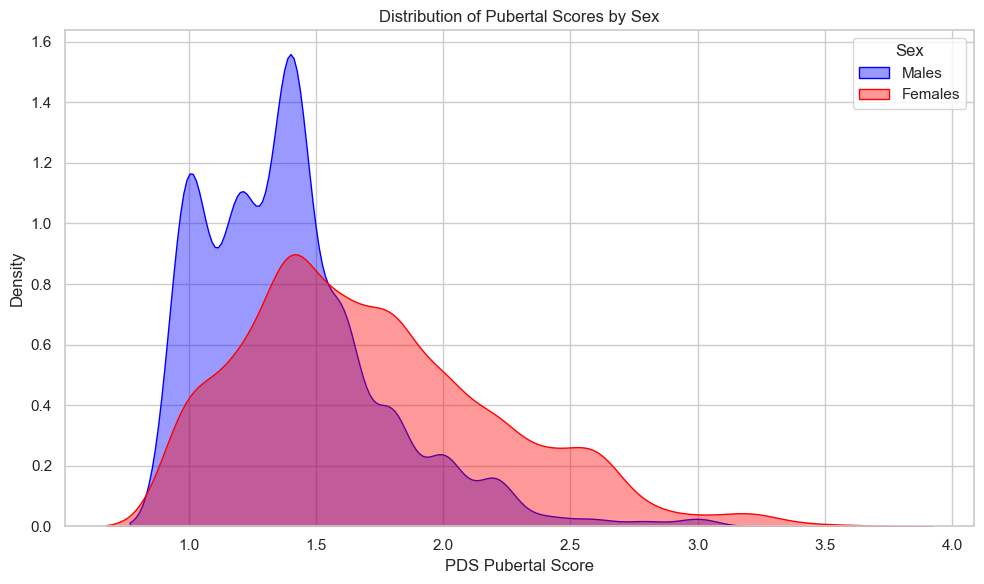

In [58]:
### Density plots
# This uses kernel density estimation (kdeplot) to visualize distributions smoothly.
# You can also adjust alpha to change transparency and fill=False if you'd prefer just the outline.

# Set style
sns.set(style="whitegrid")

# Create the plot
plt.figure(figsize=(10, 6))

# Plot male distribution
sns.kdeplot(
    data=abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'],
    x='pds_p_score',
    label='Males',
    color='blue',
    fill=True,
    alpha=0.4
)

# Plot female distribution
sns.kdeplot(
    data=abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'],
    x='pds_p_score',
    label='Females',
    color='red',
    fill=True,
    alpha=0.4
)

# Add labels and title
plt.xlabel("PDS Pubertal Score")
plt.ylabel("Density")
plt.title("Distribution of Pubertal Scores by Sex")
plt.legend(title="Sex")
plt.tight_layout()
plt.show()


#### CBCL

Describe total symptoms and symptom dimensions

In [59]:
print("CBCL Total Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_baseline_clean.cbcl_tot[abcd_demo_baseline_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_baseline_clean.cbcl_tot[abcd_demo_baseline_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_baseline_clean.cbcl_tot[abcd_demo_baseline_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_baseline_clean.cbcl_tot[abcd_demo_baseline_clean.sex == 'M']):.2f}")

print("\nCBCL Internalizing Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_baseline_clean.cbcl_int[abcd_demo_baseline_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_baseline_clean.cbcl_int[abcd_demo_baseline_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_baseline_clean.cbcl_int[abcd_demo_baseline_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_baseline_clean.cbcl_int[abcd_demo_baseline_clean.sex == 'M']):.2f}")

print("\nCBCL Externalizing Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_baseline_clean.cbcl_ext[abcd_demo_baseline_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_baseline_clean.cbcl_ext[abcd_demo_baseline_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_baseline_clean.cbcl_ext[abcd_demo_baseline_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_baseline_clean.cbcl_ext[abcd_demo_baseline_clean.sex == 'M']):.2f}")

CBCL Total Symptoms
Females: Mean: 15.26, SD: 15.35
Males: Mean: 18.26, SD: 18.11

CBCL Internalizing Symptoms
Females: Mean: 5.00, SD: 5.39
Males: Mean: 4.88, SD: 5.30

CBCL Externalizing Symptoms
Females: Mean: 3.47, SD: 4.83
Males: Mean: 4.64, SD: 6.19


In [60]:
print("CBCL Total Symptoms")
print(stats.levene(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].cbcl_tot, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].cbcl_tot, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].cbcl_tot, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].cbcl_tot, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

print("\nCBCL Internalizing Symptoms")
print(stats.levene(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].cbcl_int, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].cbcl_int, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].cbcl_int, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].cbcl_int, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

print("\nCBCL Externalizing Symptoms")
print(stats.levene(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].cbcl_ext, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].cbcl_ext, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].cbcl_ext, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].cbcl_ext, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

CBCL Total Symptoms
LeveneResult(statistic=16.477858182335652, pvalue=5.0161386737990004e-05)
FlignerResult(statistic=27.354238059582748, pvalue=1.6939278603359047e-07)

CBCL Internalizing Symptoms
LeveneResult(statistic=0.22521101913550973, pvalue=0.6351236230349571)
FlignerResult(statistic=0.17089760242911115, pvalue=0.6793153090269102)

CBCL Externalizing Symptoms
LeveneResult(statistic=35.175089936975525, pvalue=3.268138410994069e-09)
FlignerResult(statistic=30.60261159684282, pvalue=3.166672075285197e-08)


In [61]:
print("CBCL Total Symptoms")
print(f"{stats.ttest_ind(abcd_demo_baseline_clean.cbcl_tot[abcd_demo_baseline_clean.sex == 'F'], abcd_demo_baseline_clean.cbcl_tot[abcd_demo_baseline_clean.sex == 'M'], nan_policy='omit')}")

print("\nCBCL Internalizing Symptoms")
print(f"{stats.ttest_ind(abcd_demo_baseline_clean.cbcl_int[abcd_demo_baseline_clean.sex == 'F'], abcd_demo_baseline_clean.cbcl_int[abcd_demo_baseline_clean.sex == 'M'], nan_policy='omit')}")

print("\nCBCL Externalizing Symptoms")
print(f"{stats.ttest_ind(abcd_demo_baseline_clean.cbcl_ext[abcd_demo_baseline_clean.sex == 'F'], abcd_demo_baseline_clean.cbcl_ext[abcd_demo_baseline_clean.sex == 'M'], nan_policy='omit')}")

CBCL Total Symptoms
TtestResult(statistic=-5.666088143193802, pvalue=1.5636481827016265e-08, df=4005.0)

CBCL Internalizing Symptoms
TtestResult(statistic=0.6972155675368149, pvalue=0.48570836646905036, df=4005.0)

CBCL Externalizing Symptoms
TtestResult(statistic=-6.725294971025936, pvalue=2.000257467078362e-11, df=4005.0)


In [62]:
print("CBCL Total Symptoms")
print(stats.mannwhitneyu(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].cbcl_tot, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].cbcl_tot, nan_policy='omit'))

print("\nCBCL Internalizing Symptoms")
print(stats.mannwhitneyu(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].cbcl_int, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].cbcl_int, nan_policy='omit'))

print("\nCBCL Externalizing Symptoms")
print(stats.mannwhitneyu(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].cbcl_ext, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].cbcl_ext, nan_policy='omit'))

CBCL Total Symptoms
MannwhitneyuResult(statistic=2206003.0, pvalue=3.0215470228732705e-08)

CBCL Internalizing Symptoms
MannwhitneyuResult(statistic=1973967.5, pvalue=0.417908951193377)

CBCL Externalizing Symptoms
MannwhitneyuResult(statistic=2236861.5, pvalue=9.256814286835979e-11)


Checking NaNs

In [63]:
abcd_demo_baseline_clean["cbcl_tot"].isna().sum()

0

In [64]:
abcd_demo_baseline_clean["cbcl_int"].isna().sum()

0

In [65]:
abcd_demo_baseline_clean["cbcl_ext"].isna().sum()

0

In [66]:
abcd_demo_baseline_clean[abcd_demo_baseline_clean["cbcl_tot"].isna()]

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMIz,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y


#### Family Conflict (FES)

In [67]:
abcd_demo_baseline_clean.fam_conflict_y.value_counts()

fam_conflict_y
0.0    1181
1.0     920
2.0     669
3.0     456
4.0     339
5.0     199
6.0     119
7.0      88
8.0      24
9.0       7
Name: count, dtype: int64

In [68]:
print(f"Females: Mean: {np.mean(abcd_demo_baseline_clean.fam_conflict_y[abcd_demo_baseline_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_baseline_clean.fam_conflict_y[abcd_demo_baseline_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_baseline_clean.fam_conflict_y[abcd_demo_baseline_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_baseline_clean.fam_conflict_y[abcd_demo_baseline_clean.sex == 'M']):.2f}")

Females: Mean: 1.76, SD: 1.88
Males: Mean: 2.03, SD: 1.92


In [69]:
print(stats.levene(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].fam_conflict_y, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].fam_conflict_y, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

LeveneResult(statistic=4.382248606390763, pvalue=0.03637788204084737)
FlignerResult(statistic=14.478811435672142, pvalue=0.00014174499856493272)


In [70]:
print(f"{stats.ttest_ind(abcd_demo_baseline_clean.fam_conflict_y[abcd_demo_baseline_clean.sex == 'F'], abcd_demo_baseline_clean.fam_conflict_y[abcd_demo_baseline_clean.sex == 'M'], nan_policy='omit')}")

TtestResult(statistic=-4.45732120551849, pvalue=8.526334501542777e-06, df=4000.0)


In [71]:
print(stats.mannwhitneyu(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].fam_conflict_y, nan_policy='omit'))

MannwhitneyuResult(statistic=2181906.0, pvalue=2.712547090210084e-07)


Checking NaNs

In [72]:
abcd_demo_baseline_clean["fam_conflict_y"].isna().sum()

5

#### BMI z-score (relative to age and sex - with reference to the CDC 2000 Growth Charts)

In [73]:
print(f"Females: Mean: {np.mean(abcd_demo_baseline_clean.BMIz[abcd_demo_baseline_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_baseline_clean.BMIz[abcd_demo_baseline_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_baseline_clean.BMIz[abcd_demo_baseline_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_baseline_clean.BMIz[abcd_demo_baseline_clean.sex == 'M']):.2f}")

Females: Mean: 0.14, SD: 1.14
Males: Mean: 0.18, SD: 1.11


In [74]:
print(stats.levene(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].BMIz, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].BMIz, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].BMIz, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].BMIz, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

LeveneResult(statistic=0.28650672075368944, pvalue=0.5924976370232322)
FlignerResult(statistic=0.35204787791452974, pvalue=0.5529561590791101)


In [75]:
print(f"{stats.ttest_ind(abcd_demo_baseline_clean.BMIz[abcd_demo_baseline_clean.sex == 'F'], abcd_demo_baseline_clean.BMIz[abcd_demo_baseline_clean.sex == 'M'], nan_policy='omit')}")

TtestResult(statistic=-1.094778601524917, pvalue=0.2736796255543498, df=3996.0)


In [76]:
print(stats.mannwhitneyu(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].BMIz, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].BMIz, nan_policy='omit'))

MannwhitneyuResult(statistic=2034399.0, pvalue=0.27348617057170865)


Checking NaNs

In [77]:
abcd_demo_baseline_clean["BMIz"].isna().sum()

9

### fu2y

In [134]:
len(abcd_demo_fu2y_clean)

1235

In [78]:
print(f"{np.sum(abcd_demo_fu2y_clean.sex == 'F')} females, {np.sum(abcd_demo_fu2y_clean.sex == 'M')} males")

633 females, 602 males


In [79]:
abcd_demo_fu2y_clean["edu_parent"].isna().sum()

2

#### Age

In [80]:
# 1. Setup shorthand variables
df = abcd_demo_fu2y_clean
m_data = df[df['sex'] == 'M']['age_months']
f_data = df[df['sex'] == 'F']['age_months']
all_data = df['age_months']

def print_stats(label, data):
    med, mean, sd = np.median(data), np.mean(data), np.std(data)
    print(f"{label:12} | Median: {med:.2f}m ({med/12:.2f}y) | Mean: {mean:.2f}m ({mean/12:.2f}y) | SD: {sd:.2f}")

# 2. Descriptive Statistics
print("--- Descriptive Statistics ---")
print_stats("Full Sample", all_data)
print_stats("Males", m_data)
print_stats("Females", f_data)

print(f"\nRange (All): {all_data.min():.2f} - {all_data.max():.2f} months "
      f"({all_data.min()/12:.2f} - {all_data.max()/12:.2f} years)")

# 3. Normality & Significance Tests
print("\n--- Statistical Tests ---")

# Shapiro-Wilk for normality
# (If p < 0.05, data is significantly different from normal)
shapiro_m = stats.shapiro(m_data)
shapiro_f = stats.shapiro(f_data)
print(f"Shapiro Normality (M): W={shapiro_m.statistic:.4f}, p={shapiro_m.pvalue:.4f}")
print(f"Shapiro Normality (F): W={shapiro_f.statistic:.4f}, p={shapiro_f.pvalue:.4f}")

# Mann-Whitney U (Non-parametric comparison)

u_stat, p_val = stats.mannwhitneyu(m_data, f_data)
print(f"\nMann-Whitney U Test: U={u_stat}, p={p_val:.4f}")

--- Descriptive Statistics ---
Full Sample  | Median: 144.00m (12.00y) | Mean: 143.60m (11.97y) | SD: 7.95
Males        | Median: 145.00m (12.08y) | Mean: 144.25m (12.02y) | SD: 7.98
Females      | Median: 143.00m (11.92y) | Mean: 142.97m (11.91y) | SD: 7.87

Range (All): 129.00 - 161.00 months (10.75 - 13.42 years)

--- Statistical Tests ---
Shapiro Normality (M): W=0.9504, p=0.0000
Shapiro Normality (F): W=0.9584, p=0.0000

Mann-Whitney U Test: U=208195.0, p=0.0048


#### Total SA

In [81]:
print("mm2")
print(f"Total SA in Females: Mean: {np.mean(abcd_demo_fu2y_clean.tot_SA[abcd_demo_fu2y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.tot_SA[abcd_demo_fu2y_clean.sex == 'F']):.2f}") 
print(f"Total SA in Males: Mean: {np.mean(abcd_demo_fu2y_clean.tot_SA[abcd_demo_fu2y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.tot_SA[abcd_demo_fu2y_clean.sex == 'M']):.2f}")

print("\ncm2")
print(f"Total SA in Females: Mean: {np.mean(abcd_demo_fu2y_clean.tot_SA[abcd_demo_fu2y_clean.sex == 'F']/100):.2f}, SD: {np.std(abcd_demo_fu2y_clean.tot_SA[abcd_demo_fu2y_clean.sex == 'F']/100):.2f}") 
print(f"Total SA in Males: Mean: {np.mean(abcd_demo_fu2y_clean.tot_SA[abcd_demo_fu2y_clean.sex == 'M']/100):.2f}, SD: {np.std(abcd_demo_fu2y_clean.tot_SA[abcd_demo_fu2y_clean.sex == 'M']/100):.2f}")


mm2
Total SA in Females: Mean: 188184.90, SD: 14497.46
Total SA in Males: Mean: 205878.94, SD: 17199.99

cm2
Total SA in Females: Mean: 1881.85, SD: 144.97
Total SA in Males: Mean: 2058.79, SD: 172.00


In [82]:
stats.ttest_ind(abcd_demo_fu2y_clean.tot_SA[abcd_demo_fu2y_clean.sex == 'F'], abcd_demo_fu2y_clean.tot_SA[abcd_demo_fu2y_clean.sex == 'M'])

TtestResult(statistic=-19.565879208062256, pvalue=1.8698481058602426e-74, df=1233.0)

#### Puberty

In [83]:
# 1. Setup shorthand variables
df = abcd_demo_fu2y_clean
m_data = df[df['sex'] == 'M']['pds_p_score']
f_data = df[df['sex'] == 'F']['pds_p_score']
all_data = df['pds_p_score']

def print_stats(label, data):
    med, mean, sd = np.median(data), np.mean(data), np.std(data)
    print(f"{label:12} | Median: {med:.2f} | Mean: {mean:.2f} | SD: {sd:.2f}")

# 2. Descriptive Statistics
print("--- Descriptive Statistics ---")
print_stats("Full Sample", all_data)
print_stats("Males", m_data)
print_stats("Females", f_data)

print(f"\nRange (All): {all_data.min():.2f} - {all_data.max():.2f}")

# 3. Normality & Significance Tests
print("\n--- Statistical Tests ---")

# Shapiro-Wilk for normality
# (If p < 0.05, data is significantly different from normal)
shapiro_m = stats.shapiro(m_data)
shapiro_f = stats.shapiro(f_data)
print(f"Shapiro Normality (M): W={shapiro_m.statistic:.4f}, p={shapiro_m.pvalue:.4f}")
print(f"Shapiro Normality (F): W={shapiro_f.statistic:.4f}, p={shapiro_f.pvalue:.4f}")

# Mann-Whitney U (Non-parametric comparison)

u_stat, p_val = stats.mannwhitneyu(m_data, f_data)
print(f"\nMann-Whitney U Test: U={u_stat}, p={p_val:.4f}")

--- Descriptive Statistics ---
Full Sample  | Median: 2.20 | Mean: 2.16 | SD: 0.69
Males        | Median: 1.80 | Mean: 1.83 | SD: 0.55
Females      | Median: 2.50 | Mean: 2.48 | SD: 0.66

Range (All): 1.00 - 3.80

--- Statistical Tests ---
Shapiro Normality (M): W=0.9437, p=0.0000
Shapiro Normality (F): W=0.9538, p=0.0000

Mann-Whitney U Test: U=87734.5, p=0.0000


#### CBCL

Describe total symptoms and symptom diensions

In [84]:
print("CBCL Total Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_fu2y_clean.cbcl_tot[abcd_demo_fu2y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.cbcl_tot[abcd_demo_fu2y_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_fu2y_clean.cbcl_tot[abcd_demo_fu2y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.cbcl_tot[abcd_demo_fu2y_clean.sex == 'M']):.2f}")

print("\nCBCL Internalizing Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_fu2y_clean.cbcl_int[abcd_demo_fu2y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.cbcl_int[abcd_demo_fu2y_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_fu2y_clean.cbcl_int[abcd_demo_fu2y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.cbcl_int[abcd_demo_fu2y_clean.sex == 'M']):.2f}")

print("\nCBCL Externalizing Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_fu2y_clean.cbcl_ext[abcd_demo_fu2y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.cbcl_ext[abcd_demo_fu2y_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_fu2y_clean.cbcl_ext[abcd_demo_fu2y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.cbcl_ext[abcd_demo_fu2y_clean.sex == 'M']):.2f}")

CBCL Total Symptoms
Females: Mean: 14.94, SD: 14.08
Males: Mean: 17.07, SD: 16.67

CBCL Internalizing Symptoms
Females: Mean: 5.53, SD: 5.46
Males: Mean: 4.80, SD: 5.53

CBCL Externalizing Symptoms
Females: Mean: 3.28, SD: 4.41
Males: Mean: 4.13, SD: 5.23


In [85]:
print("CBCL Total Symptoms")
print(stats.levene(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].cbcl_tot, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].cbcl_tot, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].cbcl_tot, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].cbcl_tot, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

print("\nCBCL Internalizing Symptoms")
print(stats.levene(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].cbcl_int, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].cbcl_int, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].cbcl_int, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].cbcl_int, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

print("\nCBCL Externalizing Symptoms")
print(stats.levene(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].cbcl_ext, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].cbcl_ext, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].cbcl_ext, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].cbcl_ext, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

CBCL Total Symptoms
LeveneResult(statistic=6.393619893314841, pvalue=0.01157716316814538)
FlignerResult(statistic=7.9664427533591144, pvalue=0.004765249359763292)

CBCL Internalizing Symptoms
LeveneResult(statistic=0.8638038794440441, pvalue=0.3528584504444541)
FlignerResult(statistic=5.630824609581286, pvalue=0.017647327988106754)

CBCL Externalizing Symptoms
LeveneResult(statistic=10.112200328981704, pvalue=0.0015096154836785123)
FlignerResult(statistic=8.337704770172861, pvalue=0.0038830623531625596)


In [86]:
print("CBCL Total Symptoms")
print(f"{stats.ttest_ind(abcd_demo_fu2y_clean.cbcl_tot[abcd_demo_fu2y_clean.sex == 'F'], abcd_demo_fu2y_clean.cbcl_tot[abcd_demo_fu2y_clean.sex == 'M'], nan_policy='omit')}")

print("\nCBCL Internalizing Symptoms")
print(f"{stats.ttest_ind(abcd_demo_fu2y_clean.cbcl_int[abcd_demo_fu2y_clean.sex == 'F'], abcd_demo_fu2y_clean.cbcl_int[abcd_demo_fu2y_clean.sex == 'M'], nan_policy='omit')}")

print("\nCBCL Externalizing Symptoms")
print(f"{stats.ttest_ind(abcd_demo_fu2y_clean.cbcl_ext[abcd_demo_fu2y_clean.sex == 'F'], abcd_demo_fu2y_clean.cbcl_ext[abcd_demo_fu2y_clean.sex == 'M'], nan_policy='omit')}")

CBCL Total Symptoms
TtestResult(statistic=-2.4366341364257065, pvalue=0.014965513048916442, df=1232.0)

CBCL Internalizing Symptoms
TtestResult(statistic=2.3169078465165764, pvalue=0.020672080159231512, df=1232.0)

CBCL Externalizing Symptoms
TtestResult(statistic=-3.078341829999094, pvalue=0.002127551788745212, df=1232.0)


In [87]:
print("CBCL Total Symptoms")
print(stats.mannwhitneyu(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].cbcl_tot, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].cbcl_tot, nan_policy='omit'))

print("\nCBCL Internalizing Symptoms")
print(stats.mannwhitneyu(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].cbcl_int, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].cbcl_int, nan_policy='omit'))

print("\nCBCL Externalizing Symptoms")
print(stats.mannwhitneyu(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].cbcl_ext, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].cbcl_ext, nan_policy='omit'))

CBCL Total Symptoms
MannwhitneyuResult(statistic=200861.5, pvalue=0.08873466459157146)

CBCL Internalizing Symptoms
MannwhitneyuResult(statistic=168948.5, pvalue=0.0006365697540493935)

CBCL Externalizing Symptoms
MannwhitneyuResult(statistic=204117.0, pvalue=0.02380207545991213)


Checking NaNs

In [88]:
abcd_demo_fu2y_clean["cbcl_tot"].isna().sum()

1

In [89]:
abcd_demo_fu2y_clean["cbcl_int"].isna().sum()

1

In [90]:
abcd_demo_fu2y_clean["cbcl_ext"].isna().sum()

1

In [91]:
abcd_demo_fu2y_clean[abcd_demo_fu2y_clean["cbcl_tot"].isna()]

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMIz,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y
64,sub-NDARINV1DDX454E,9.0,M,17.0,2_year_follow_up_y_arm_1,site21,4727.0,132.0,1.0,3.0,1.2,2.2,1.634283,217172.631572,NaN,NaN,NaN,NaN


#### Family Conflict (FES)

In [92]:
abcd_demo_fu2y_clean.fam_conflict_y.value_counts()

fam_conflict_y
0.0    357
1.0    308
2.0    205
3.0    137
4.0    108
5.0     58
6.0     34
7.0     20
8.0      6
9.0      1
Name: count, dtype: int64

In [93]:
print(f"Females: Mean: {np.mean(abcd_demo_fu2y_clean.fam_conflict_y[abcd_demo_fu2y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.fam_conflict_y[abcd_demo_fu2y_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_fu2y_clean.fam_conflict_y[abcd_demo_fu2y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.fam_conflict_y[abcd_demo_fu2y_clean.sex == 'M']):.2f}")

Females: Mean: 1.85, SD: 1.83
Males: Mean: 1.80, SD: 1.81


In [94]:
print(stats.levene(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].fam_conflict_y, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].fam_conflict_y, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

LeveneResult(statistic=0.010307855761430111, pvalue=0.9191481610724539)
FlignerResult(statistic=0.00044371058631677393, pvalue=0.9831942522408581)


In [95]:
print(f"{stats.ttest_ind(abcd_demo_fu2y_clean.fam_conflict_y[abcd_demo_fu2y_clean.sex == 'F'], abcd_demo_fu2y_clean.fam_conflict_y[abcd_demo_fu2y_clean.sex == 'M'], nan_policy='omit')}")

TtestResult(statistic=0.5246893995443446, pvalue=0.5998935222374506, df=1232.0)


In [96]:
print(stats.mannwhitneyu(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].fam_conflict_y, nan_policy='omit'))

MannwhitneyuResult(statistic=186626.0, pvalue=0.5568246698192785)


Checking NaNs

In [97]:
abcd_demo_fu2y_clean["fam_conflict_y"].isna().sum()

1

#### BMI z-score (relative to age and sex - with reference to the CDC 2000 Growth Charts)

In [98]:
print(f"Females: Mean: {np.mean(abcd_demo_fu2y_clean.BMIz[abcd_demo_fu2y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.BMIz[abcd_demo_fu2y_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_fu2y_clean.BMIz[abcd_demo_fu2y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.BMIz[abcd_demo_fu2y_clean.sex == 'M']):.2f}")

Females: Mean: 0.38, SD: 1.05
Males: Mean: 0.26, SD: 1.21


In [99]:
print(stats.levene(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].BMIz, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].BMIz, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].BMIz, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].BMIz, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

LeveneResult(statistic=12.867999217618296, pvalue=0.00034733715207998383)
FlignerResult(statistic=12.820277710850553, pvalue=0.00034288282564677336)


In [100]:
print(f"{stats.ttest_ind(abcd_demo_fu2y_clean.BMIz[abcd_demo_fu2y_clean.sex == 'F'], abcd_demo_fu2y_clean.BMIz[abcd_demo_fu2y_clean.sex == 'M'], nan_policy='omit')}")

TtestResult(statistic=1.8147784322815277, pvalue=0.06980086575082764, df=1233.0)


In [101]:
print(stats.mannwhitneyu(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].BMIz, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].BMIz, nan_policy='omit'))

MannwhitneyuResult(statistic=182533.0, pvalue=0.2016507960182944)


Checking NaNs

In [102]:
abcd_demo_fu2y_clean["BMIz"].isna().sum()

0

### fu4y

In [135]:
len(abcd_demo_fu4y_clean)

929

In [103]:
print(f"{np.sum(abcd_demo_fu4y_clean.sex == 'F')} females, {np.sum(abcd_demo_fu4y_clean.sex == 'M')} males")

447 females, 482 males


In [104]:
abcd_demo_fu4y_clean["edu_parent"].isna().sum()

0

#### Age

In [105]:
# 1. Setup shorthand variables
df = abcd_demo_fu4y_clean
m_data = df[df['sex'] == 'M']['age_months']
f_data = df[df['sex'] == 'F']['age_months']
all_data = df['age_months']

def print_stats(label, data):
    med, mean, sd = np.median(data), np.mean(data), np.std(data)
    print(f"{label:12} | Median: {med:.2f}m ({med/12:.2f}y) | Mean: {mean:.2f}m ({mean/12:.2f}y) | SD: {sd:.2f}")

# 2. Descriptive Statistics
print("--- Descriptive Statistics ---")
print_stats("Full Sample", all_data)
print_stats("Males", m_data)
print_stats("Females", f_data)

print(f"\nRange (All): {all_data.min():.2f} - {all_data.max():.2f} months "
      f"({all_data.min()/12:.2f} - {all_data.max()/12:.2f} years)")

# 3. Normality & Significance Tests
print("\n--- Statistical Tests ---")

# Shapiro-Wilk for normality
# (If p < 0.05, data is significantly different from normal)
shapiro_m = stats.shapiro(m_data)
shapiro_f = stats.shapiro(f_data)
print(f"Shapiro Normality (M): W={shapiro_m.statistic:.4f}, p={shapiro_m.pvalue:.4f}")
print(f"Shapiro Normality (F): W={shapiro_f.statistic:.4f}, p={shapiro_f.pvalue:.4f}")

# Mann-Whitney U (Non-parametric comparison)

u_stat, p_val = stats.mannwhitneyu(m_data, f_data)
print(f"\nMann-Whitney U Test: U={u_stat}, p={p_val:.4f}")

--- Descriptive Statistics ---
Full Sample  | Median: 169.00m (14.08y) | Mean: 169.19m (14.10y) | SD: 8.14
Males        | Median: 170.00m (14.17y) | Mean: 169.62m (14.14y) | SD: 8.26
Females      | Median: 168.00m (14.00y) | Mean: 168.72m (14.06y) | SD: 7.99

Range (All): 151.00 - 187.00 months (12.58 - 15.58 years)

--- Statistical Tests ---
Shapiro Normality (M): W=0.9604, p=0.0000
Shapiro Normality (F): W=0.9702, p=0.0000

Mann-Whitney U Test: U=114814.0, p=0.0827


#### Total SA

In [106]:
print("mm2")
print(f"Total SA in Females: Mean: {np.mean(abcd_demo_fu4y_clean.tot_SA[abcd_demo_fu4y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.tot_SA[abcd_demo_fu4y_clean.sex == 'F']):.2f}") 
print(f"Total SA in Males: Mean: {np.mean(abcd_demo_fu4y_clean.tot_SA[abcd_demo_fu4y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.tot_SA[abcd_demo_fu4y_clean.sex == 'M']):.2f}")

print("\ncm2")
print(f"Total SA in Females: Mean: {np.mean(abcd_demo_fu4y_clean.tot_SA[abcd_demo_fu4y_clean.sex == 'F']/100):.2f}, SD: {np.std(abcd_demo_fu4y_clean.tot_SA[abcd_demo_fu4y_clean.sex == 'F']/100):.2f}") 
print(f"Total SA in Males: Mean: {np.mean(abcd_demo_fu4y_clean.tot_SA[abcd_demo_fu4y_clean.sex == 'M']/100):.2f}, SD: {np.std(abcd_demo_fu4y_clean.tot_SA[abcd_demo_fu4y_clean.sex == 'M']/100):.2f}")


mm2
Total SA in Females: Mean: 187947.27, SD: 15576.01
Total SA in Males: Mean: 205410.64, SD: 16723.15

cm2
Total SA in Females: Mean: 1879.47, SD: 155.76
Total SA in Males: Mean: 2054.11, SD: 167.23


In [107]:
stats.ttest_ind(abcd_demo_fu4y_clean.tot_SA[abcd_demo_fu4y_clean.sex == 'F'], abcd_demo_fu4y_clean.tot_SA[abcd_demo_fu4y_clean.sex == 'M'])

TtestResult(statistic=-16.417801700439583, pvalue=2.3004889989410065e-53, df=927.0)

#### Puberty

In [108]:
# 1. Setup shorthand variables
df = abcd_demo_fu4y_clean
m_data = df[df['sex'] == 'M']['pds_p_score']
f_data = df[df['sex'] == 'F']['pds_p_score']
all_data = df['pds_p_score']

def print_stats(label, data):
    med, mean, sd = np.median(data), np.mean(data), np.std(data)
    print(f"{label:12} | Median: {med:.2f} | Mean: {mean:.2f} | SD: {sd:.2f}")

# 2. Descriptive Statistics
print("--- Descriptive Statistics ---")
print_stats("Full Sample", all_data)
print_stats("Males", m_data)
print_stats("Females", f_data)

print(f"\nRange (All): {all_data.min():.2f} - {all_data.max():.2f}")

# 3. Normality & Significance Tests
print("\n--- Statistical Tests ---")

# Shapiro-Wilk for normality
# (If p < 0.05, data is significantly different from normal)
shapiro_m = stats.shapiro(m_data)
shapiro_f = stats.shapiro(f_data)
print(f"Shapiro Normality (M): W={shapiro_m.statistic:.4f}, p={shapiro_m.pvalue:.4f}")
print(f"Shapiro Normality (F): W={shapiro_f.statistic:.4f}, p={shapiro_f.pvalue:.4f}")

# Mann-Whitney U (Non-parametric comparison)

u_stat, p_val = stats.mannwhitneyu(m_data, f_data)
print(f"\nMann-Whitney U Test: U={u_stat}, p={p_val:.4f}")

--- Descriptive Statistics ---
Full Sample  | Median: 3.00 | Mean: 2.99 | SD: 0.54
Males        | Median: 2.80 | Mean: 2.70 | SD: 0.48
Females      | Median: 3.20 | Mean: 3.31 | SD: 0.41

Range (All): 1.00 - 4.00

--- Statistical Tests ---
Shapiro Normality (M): W=0.8964, p=0.0000
Shapiro Normality (F): W=0.9217, p=0.0000

Mann-Whitney U Test: U=28918.5, p=0.0000


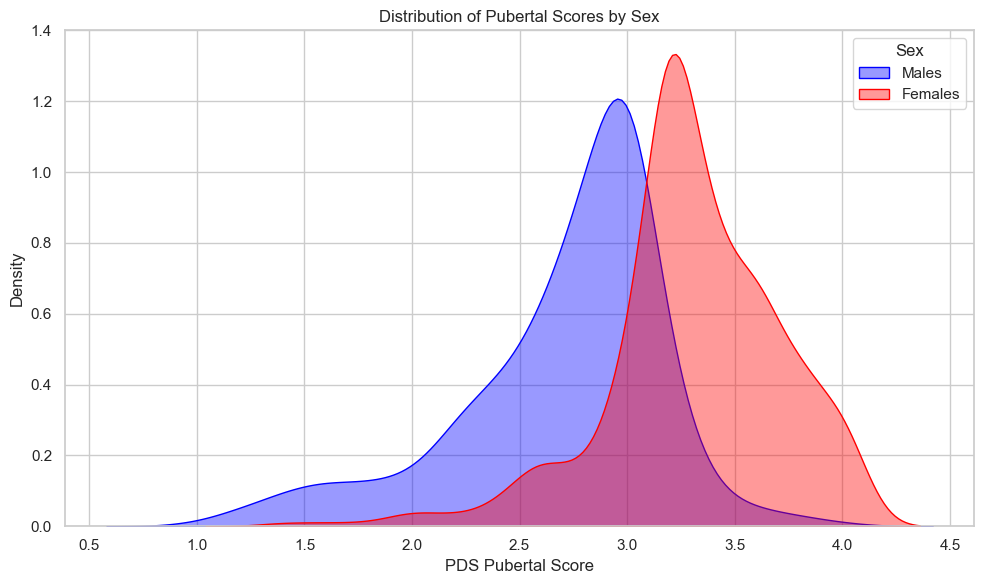

In [109]:
### Density plots
# This uses kernel density estimation (kdeplot) to visualize distributions smoothly.
# You can also adjust alpha to change transparency and fill=False if you'd prefer just the outline.

# Set style
sns.set(style="whitegrid")

# Create the plot
plt.figure(figsize=(10, 6))

# Plot male distribution
sns.kdeplot(
    data=abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'],
    x='pds_p_score',
    label='Males',
    color='blue',
    fill=True,
    alpha=0.4
)

# Plot female distribution
sns.kdeplot(
    data=abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'],
    x='pds_p_score',
    label='Females',
    color='red',
    fill=True,
    alpha=0.4
)

# Add labels and title
plt.xlabel("PDS Pubertal Score")
plt.ylabel("Density")
plt.title("Distribution of Pubertal Scores by Sex")
plt.legend(title="Sex")
plt.tight_layout()
plt.show()


#### CBCL

Describe total symptoms and symptom diensions

In [110]:
print("CBCL Total Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_fu4y_clean.cbcl_tot[abcd_demo_fu4y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.cbcl_tot[abcd_demo_fu4y_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_fu4y_clean.cbcl_tot[abcd_demo_fu4y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.cbcl_tot[abcd_demo_fu4y_clean.sex == 'M']):.2f}")

print("\nCBCL Internalizing Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_fu4y_clean.cbcl_int[abcd_demo_fu4y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.cbcl_int[abcd_demo_fu4y_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_fu4y_clean.cbcl_int[abcd_demo_fu4y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.cbcl_int[abcd_demo_fu4y_clean.sex == 'M']):.2f}")

print("\nCBCL Externalizing Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_fu4y_clean.cbcl_ext[abcd_demo_fu4y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.cbcl_ext[abcd_demo_fu4y_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_fu4y_clean.cbcl_ext[abcd_demo_fu4y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.cbcl_ext[abcd_demo_fu4y_clean.sex == 'M']):.2f}")

CBCL Total Symptoms
Females: Mean: 14.39, SD: 15.19
Males: Mean: 14.45, SD: 14.96

CBCL Internalizing Symptoms
Females: Mean: 6.12, SD: 6.66
Males: Mean: 4.32, SD: 5.03

CBCL Externalizing Symptoms
Females: Mean: 2.72, SD: 4.29
Males: Mean: 3.58, SD: 4.98


In [111]:
print("CBCL Total Symptoms")
print(stats.levene(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].cbcl_tot, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].cbcl_tot, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].cbcl_tot, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].cbcl_tot, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

print("\nCBCL Internalizing Symptoms")
print(stats.levene(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].cbcl_int, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].cbcl_int, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].cbcl_int, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].cbcl_int, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

print("\nCBCL Externalizing Symptoms")
print(stats.levene(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].cbcl_ext, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].cbcl_ext, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].cbcl_ext, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].cbcl_ext, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

CBCL Total Symptoms
LeveneResult(statistic=0.5307238315258325, pvalue=0.4664868934387638)
FlignerResult(statistic=1.8134084405140165, pvalue=0.1780998957144025)

CBCL Internalizing Symptoms
LeveneResult(statistic=9.934671263578174, pvalue=0.0016740967671590187)
FlignerResult(statistic=13.742342639678274, pvalue=0.0002096738322301482)

CBCL Externalizing Symptoms
LeveneResult(statistic=8.761157689819697, pvalue=0.0031555604627186568)
FlignerResult(statistic=31.543633171442856, pvalue=1.9500871566836863e-08)


In [112]:
print("CBCL Total Symptoms")
print(f"{stats.ttest_ind(abcd_demo_fu4y_clean.cbcl_tot[abcd_demo_fu4y_clean.sex == 'F'], abcd_demo_fu4y_clean.cbcl_tot[abcd_demo_fu4y_clean.sex == 'M'], nan_policy='omit')}")

print("\nCBCL Internalizing Symptoms")
print(f"{stats.ttest_ind(abcd_demo_fu4y_clean.cbcl_int[abcd_demo_fu4y_clean.sex == 'F'], abcd_demo_fu4y_clean.cbcl_int[abcd_demo_fu4y_clean.sex == 'M'], nan_policy='omit')}")

print("\nCBCL Externalizing Symptoms")
print(f"{stats.ttest_ind(abcd_demo_fu4y_clean.cbcl_ext[abcd_demo_fu4y_clean.sex == 'F'], abcd_demo_fu4y_clean.cbcl_ext[abcd_demo_fu4y_clean.sex == 'M'], nan_policy='omit')}")

CBCL Total Symptoms
TtestResult(statistic=-0.06511355337490507, pvalue=0.9480976432499848, df=926.0)

CBCL Internalizing Symptoms
TtestResult(statistic=4.659814127065144, pvalue=3.6286745693661665e-06, df=926.0)

CBCL Externalizing Symptoms
TtestResult(statistic=-2.801062889024033, pvalue=0.005199569340434276, df=926.0)


In [113]:
print("CBCL Total Symptoms")
print(stats.mannwhitneyu(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].cbcl_tot, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].cbcl_tot, nan_policy='omit'))

print("\nCBCL Internalizing Symptoms")
print(stats.mannwhitneyu(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].cbcl_int, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].cbcl_int, nan_policy='omit'))

print("\nCBCL Externalizing Symptoms")
print(stats.mannwhitneyu(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].cbcl_ext, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].cbcl_ext, nan_policy='omit'))

CBCL Total Symptoms
MannwhitneyuResult(statistic=106053.5, pvalue=0.7253373420492758)

CBCL Internalizing Symptoms
MannwhitneyuResult(statistic=87251.0, pvalue=6.069674694138111e-07)

CBCL Externalizing Symptoms
MannwhitneyuResult(statistic=116593.5, pvalue=0.022204761908217248)


Checking NaNs

In [114]:
abcd_demo_fu4y_clean["cbcl_tot"].isna().sum()

1

In [115]:
abcd_demo_fu4y_clean["cbcl_int"].isna().sum()

1

In [116]:
abcd_demo_fu4y_clean["cbcl_ext"].isna().sum()

1

In [117]:
abcd_demo_fu4y_clean[abcd_demo_fu4y_clean["cbcl_tot"].isna()]

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMIz,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y
80,sub-NDARINV2GDYKWG2,10.0,F,18.0,4_year_follow_up_y_arm_1,site06,8812.0,168.0,4.0,4.0,3.4,3.4,0.141732,187139.982964,NaN,NaN,NaN,8.0


#### Family Conflict (FES)

In [118]:
abcd_demo_fu4y_clean.fam_conflict_y.value_counts()

fam_conflict_y
0.0    258
1.0    187
2.0    150
3.0     98
4.0     86
5.0     72
6.0     36
7.0     27
9.0      8
8.0      7
Name: count, dtype: int64

In [119]:
print(f"Females: Mean: {np.mean(abcd_demo_fu4y_clean.fam_conflict_y[abcd_demo_fu4y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.fam_conflict_y[abcd_demo_fu4y_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_fu4y_clean.fam_conflict_y[abcd_demo_fu4y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.fam_conflict_y[abcd_demo_fu4y_clean.sex == 'M']):.2f}")

Females: Mean: 2.40, SD: 2.24
Males: Mean: 1.96, SD: 1.98


In [120]:
print(stats.levene(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].fam_conflict_y, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].fam_conflict_y, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

LeveneResult(statistic=7.357858021704127, pvalue=0.006800719968055592)
FlignerResult(statistic=11.86718947025221, pvalue=0.0005713156466106111)


In [121]:
print(f"{stats.ttest_ind(abcd_demo_fu4y_clean.fam_conflict_y[abcd_demo_fu4y_clean.sex == 'F'], abcd_demo_fu4y_clean.fam_conflict_y[abcd_demo_fu4y_clean.sex == 'M'], nan_policy='omit')}")

TtestResult(statistic=3.204464969526962, pvalue=0.0013993613325488233, df=927.0)


In [122]:
print(stats.mannwhitneyu(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].fam_conflict_y, nan_policy='omit'))

MannwhitneyuResult(statistic=96615.0, pvalue=0.005606289795373813)


Checking NaNs

In [123]:
abcd_demo_fu4y_clean["fam_conflict_y"].isna().sum()

0

#### BMI z-score (relative to age and sex - with reference to the CDC 2000 Growth Charts)

In [124]:
print(f"Females: Mean: {np.mean(abcd_demo_fu4y_clean.BMIz[abcd_demo_fu4y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.BMIz[abcd_demo_fu4y_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_fu4y_clean.BMIz[abcd_demo_fu4y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.BMIz[abcd_demo_fu4y_clean.sex == 'M']):.2f}")

Females: Mean: 0.63, SD: 1.04
Males: Mean: 0.38, SD: 1.21


In [125]:
print(stats.levene(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].BMIz, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].BMIz, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].BMIz, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].BMIz, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

LeveneResult(statistic=11.32018523438875, pvalue=0.0007982392434428779)
FlignerResult(statistic=11.609525321967093, pvalue=0.0006561489696159542)


In [126]:
print(f"{stats.ttest_ind(abcd_demo_fu4y_clean.BMIz[abcd_demo_fu4y_clean.sex == 'F'], abcd_demo_fu4y_clean.BMIz[abcd_demo_fu4y_clean.sex == 'M'], nan_policy='omit')}")

TtestResult(statistic=3.2799098272823266, pvalue=0.0010772289637255392, df=924.0)


In [127]:
print(stats.mannwhitneyu(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].BMIz, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].BMIz, nan_policy='omit'))

MannwhitneyuResult(statistic=95064.0, pvalue=0.003191818019719028)


Checking NaNs

In [128]:
abcd_demo_fu4y_clean["BMIz"].isna().sum()

3

### full

In [130]:
abcd_demo_all_clean

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMIz,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y
0,sub-NDARINV003RTV85,10.0,F,13.0,baseline_year_1_arm_1,site06,8781.0,131.0,3.0,3.0,1.6,2.4,0.961662,188827.953554,4.0,1.0,1.0,3.0
1,sub-NDARINV007W6H7B,10.0,M,19.0,baseline_year_1_arm_1,site22,4722.0,126.0,2.0,1.0,1.5,1.0,0.550824,233329.288961,23.0,8.0,2.0,0.0
2,sub-NDARINV00J52GPG,9.0,M,21.0,baseline_year_1_arm_1,site17,4151.0,110.0,2.0,2.0,1.4,1.6,1.129072,201853.751338,11.0,0.0,1.0,0.0
3,sub-NDARINV00LH735Y,9.0,M,13.0,baseline_year_1_arm_1,site03,6069.0,109.0,1.0,1.0,1.0,1.4,1.570677,204865.644678,8.0,4.0,2.0,0.0
4,sub-NDARINV00NPMHND,9.0,F,18.0,baseline_year_1_arm_1,site17,4152.0,118.0,2.0,3.0,1.5,1.8,0.363954,212433.396427,42.0,23.0,3.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6166,sub-NDARINVZYC44GB8,10.0,M,21.0,4_year_follow_up_y_arm_1,site16,1840.0,179.0,4.0,4.0,3.0,3.0,-0.503814,206655.702684,0.0,0.0,0.0,0.0
6167,sub-NDARINVZYRTFYRP,9.0,M,13.0,4_year_follow_up_y_arm_1,site10,10925.0,164.0,1.0,3.0,1.6,2.6,-0.428811,173346.170313,20.0,4.0,5.0,1.0
6168,sub-NDARINVZZ1MNPK5,10.0,F,20.0,4_year_follow_up_y_arm_1,site08,7031.0,175.0,5.0,4.0,3.6,3.6,-0.500384,171459.001848,20.0,13.0,2.0,0.0
6169,sub-NDARINVZZ81LEEV,9.0,M,15.0,4_year_follow_up_y_arm_1,site11,8433.0,157.0,2.0,2.0,1.2,1.8,-1.408592,202083.016847,6.0,3.0,0.0,0.0


In [129]:
print(f"{np.sum(abcd_demo_all_clean.sex == 'F')} females, {np.sum(abcd_demo_all_clean.sex == 'M')} males")

3168 females, 3003 males


In [131]:
len(pd.unique(abcd_demo_all_clean['src_subject_id_fmt']))

4856

In [132]:
len(pd.unique(abcd_demo_all_clean['family_id']))

4353

#### Age

In [158]:
print(f"Mean age (months): {np.mean(abcd_demo_all_clean.age_months):.2f}, sd: {np.std(abcd_demo_all_clean.age_months):.2f}")
print(f"Mean age (months) - Males: {np.mean(abcd_demo_all_clean.age_months[abcd_demo_all_clean.sex == 'M']):.2f}")
print(f"Mean age (months) - Females: {np.mean(abcd_demo_all_clean.age_months[abcd_demo_all_clean.sex == 'F']):.2f}")

print(f"Min age (months): {np.min(abcd_demo_all_clean.age_months):.2f}")
print(f"Max age (months): {np.max(abcd_demo_all_clean.age_months):.2f}")

Mean age (months): 131.94, sd: 19.81
Mean age (months) - Males: 132.83
Mean age (months) - Females: 131.11
Min age (months): 107.00
Max age (months): 187.00


/tmp/ipykernel_1454/3866318734.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Females", "Males"])


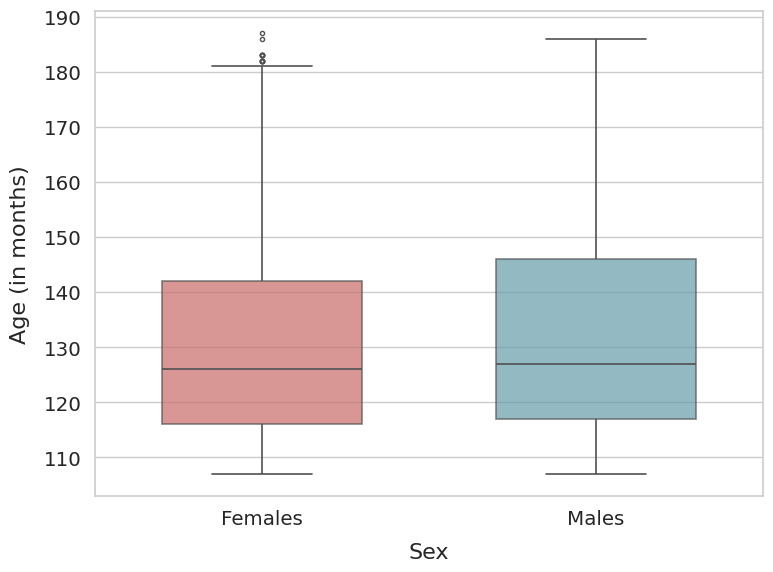

In [159]:

# Style setup
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
#sns.set_theme(style="white", font="DejaVu Sans", font_scale=1.3)

plt.rcParams["axes.linewidth"] = 1.2  # thicker axes for cleaner appearance
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create figure
plt.figure(figsize=(8, 6))

# Boxplot
ax = sns.boxplot(
    data=abcd_demo_all_clean,
    x="sex",
    y="age_months",
    hue="sex",
    palette={"F": "#d85c59", "M": "#5aa3b5"},  # palette={'M': 'cadetblue', 'F': 'lightcoral'},
    dodge=False,
    width=0.6,
    linewidth=1.2,
    fliersize=3,
    boxprops={"alpha": 0.7},
)

#sns.despine(trim=True)

# Axis labels and title
ax.set_xlabel("Sex", fontsize=16, labelpad=10)
ax.set_ylabel("Age (in months)", fontsize=16, labelpad=10)
ax.set_xticklabels(["Females", "Males"])
#ax.set_title("Age (in months) by Sex", pad=15, weight="bold")


# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

#plt.savefig(resdir_fig+"boxplot_age_by_sex.svg", format="svg", bbox_inches="tight", dpi=300)

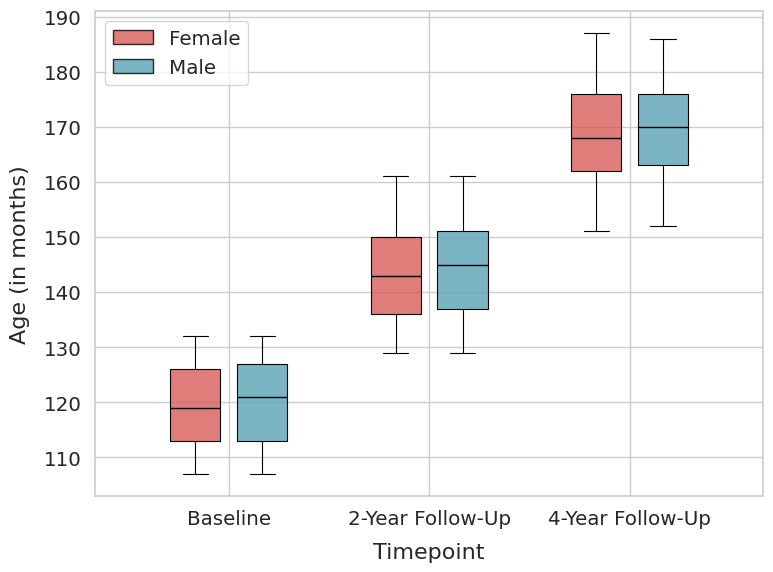

In [160]:
from matplotlib.patches import Patch
import matplotlib.colors as mcolors

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

alpha_map = {
    "Baseline": 0.8,  # 0.8
    "2-Year Follow-Up": 0.8,  # 0.6
    "4-Year Follow-Up": 0.8  # 0.3
}

sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

data = [
    abcd_demo_baseline_clean,
    abcd_demo_fu2y_clean,
    abcd_demo_fu4y_clean
]

# --- Style setup (consistent with your manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axes ---
fig, ax = plt.subplots(figsize=(8, 6))

# --- Function to draw SEX-SPLIT boxplots with TIMEPOINT alpha ---
def draw_boxplots(ax, data):

    box_width = 0.25
    offsets = [-box_width / 1.5, box_width / 1.5]  # F left, M right

    for tp_idx, tp in enumerate(timepoints):

        df_tp = data[tp_idx]
        alpha = alpha_map[tp]

        for sex_idx, sex in enumerate(["F", "M"]):

            df_sex = df_tp[df_tp["sex"] == sex]["age_months"].dropna()

            color = sex_palette[sex]
            rgba = mcolors.to_rgba(color, alpha=alpha)

            position = tp_idx + offsets[sex_idx]

            bp = ax.boxplot(
                df_sex,
                positions=[position],
                widths=box_width,
                patch_artist=True,
                boxprops=dict(facecolor=rgba, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8),
                flierprops=dict(
                    marker='o',
                    markersize=3,
                    alpha=0.5,
                    markerfacecolor='black',
                    markeredgecolor='black'
                )
            )


# --- Draw boxplots ---
draw_boxplots(ax, data)

# --- Axis labels ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("Age (in months)", fontsize=16, labelpad=10)

# --- Legend (Sex only, alpha encoded visually) ---
legend_elements = [
    Patch(facecolor=sex_palette["F"], alpha=0.8, edgecolor="black", label="Female"),
    Patch(facecolor=sex_palette["M"], alpha=0.8, edgecolor="black", label="Male"),
]
ax.legend(handles=legend_elements, loc="upper left", frameon=True)




# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(
    resdir_fig + "boxplot_age_by_sex_by_timepoint.svg",
    format="svg",
    bbox_inches="tight",
    dpi=300
)


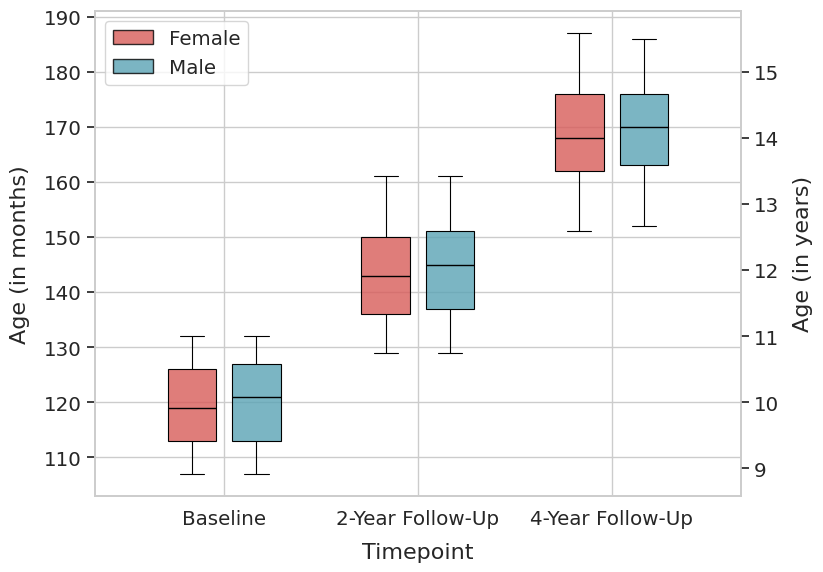

In [161]:
from matplotlib.patches import Patch
import matplotlib.colors as mcolors

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

alpha_map = {
    "Baseline": 0.8,  # 0.8
    "2-Year Follow-Up": 0.8,  # 0.6
    "4-Year Follow-Up": 0.8  # 0.3
}

sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

data = [
    abcd_demo_baseline_clean,
    abcd_demo_fu2y_clean,
    abcd_demo_fu4y_clean
]

# --- Style setup (consistent with your manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axes ---
fig, ax = plt.subplots(figsize=(8.5, 6))

# --- Function to draw SEX-SPLIT boxplots with TIMEPOINT alpha ---
def draw_boxplots(ax, data):

    box_width = 0.25
    offsets = [-box_width / 1.5, box_width / 1.5]  # F left, M right

    for tp_idx, tp in enumerate(timepoints):

        df_tp = data[tp_idx]
        alpha = alpha_map[tp]

        for sex_idx, sex in enumerate(["F", "M"]):

            df_sex = df_tp[df_tp["sex"] == sex]["age_months"].dropna()

            color = sex_palette[sex]
            rgba = mcolors.to_rgba(color, alpha=alpha)

            position = tp_idx + offsets[sex_idx]

            bp = ax.boxplot(
                df_sex,
                positions=[position],
                widths=box_width,
                patch_artist=True,
                boxprops=dict(facecolor=rgba, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8),
                flierprops=dict(
                    marker='o',
                    markersize=3,
                    alpha=0.5,
                    markerfacecolor='black',
                    markeredgecolor='black'
                )
            )


# --- Draw boxplots ---
draw_boxplots(ax, data)


# --- Axis labels and primary formatting ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("Age (in months)", fontsize=16, labelpad=10)

# --- Create the second y-axis (Age in years) ---
ax2 = ax.twinx()  # Create a twin axis sharing the x-axis

# Synchronize the limits: 
# We get the current month limits and convert them to years for the second axis
y_min, y_max = ax.get_ylim()
ax2.set_ylim(y_min / 12, y_max / 12)

ax2.set_ylabel("Age (in years)", fontsize=16, labelpad=10)
ax2.grid(False) # Usually cleaner to turn off the second grid

# --- Legend and final touches ---
legend_elements = [
    Patch(facecolor=sex_palette["F"], alpha=0.8, edgecolor="black", label="Female"),
    Patch(facecolor=sex_palette["M"], alpha=0.8, edgecolor="black", label="Male"),
]
ax.legend(handles=legend_elements, loc="upper left", frameon=True)

plt.tight_layout()


#plt.show()

plt.savefig(
    resdir_fig + "boxplot_age_by_sex_by_timepoint_2yaxes.svg",
    format="svg",
    bbox_inches="tight",
    dpi=300
)


#### Total SA

In [162]:
print("mm2")
print(f"Total SA in Females: Mean: {np.mean(abcd_demo_all_clean.tot_SA[abcd_demo_all_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_all_clean.tot_SA[abcd_demo_all_clean.sex == 'F']):.2f}") 
print(f"Total SA in Males: Mean: {np.mean(abcd_demo_all_clean.tot_SA[abcd_demo_all_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_all_clean.tot_SA[abcd_demo_all_clean.sex == 'M']):.2f}")

print("\ncm2")
print(f"Total SA in Females: Mean: {np.mean(abcd_demo_all_clean.tot_SA[abcd_demo_all_clean.sex == 'F']/100):.2f}, SD: {np.std(abcd_demo_all_clean.tot_SA[abcd_demo_all_clean.sex == 'F']/100):.2f}") 
print(f"Total SA in Males: Mean: {np.mean(abcd_demo_all_clean.tot_SA[abcd_demo_all_clean.sex == 'M']/100):.2f}, SD: {np.std(abcd_demo_all_clean.tot_SA[abcd_demo_all_clean.sex == 'M']/100):.2f}")


mm2
Total SA in Females: Mean: 190607.62, SD: 15345.58
Total SA in Males: Mean: 208438.50, SD: 17064.94

cm2
Total SA in Females: Mean: 1906.08, SD: 153.46
Total SA in Males: Mean: 2084.38, SD: 170.65


In [163]:
stats.ttest_ind(abcd_demo_all_clean.tot_SA[abcd_demo_all_clean.sex == 'F'], abcd_demo_all_clean.tot_SA[abcd_demo_all_clean.sex == 'M'])

TtestResult(statistic=-43.19602308427395, pvalue=0.0, df=6169.0)

#### Puberty

In [164]:
print(f"Males: median = {statistics.median(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].pds_p_score)}, mean = {round(statistics.mean(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].pds_p_score),2)}, sd = {round(statistics.stdev(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].pds_p_score),2)}") 
print(f"Females: median = {statistics.median(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].pds_p_score)}, mean = {round(statistics.mean(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].pds_p_score),2)}, sd = {round(statistics.stdev(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].pds_p_score),2)}") 

print()

print(stats.mannwhitneyu(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].pds_p_score, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].pds_p_score))
#print(stats.levene(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].pds_p_score, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].pds_p_score, center='median'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
#print(stats.fligner(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].pds_p_score, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].pds_p_score))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data


Males: median = 1.4, mean = 1.69, sd = 0.63
Females: median = 1.8, mean = 2.09, sd = 0.78

MannwhitneyuResult(statistic=3250623.5, pvalue=6.518843295246651e-104)


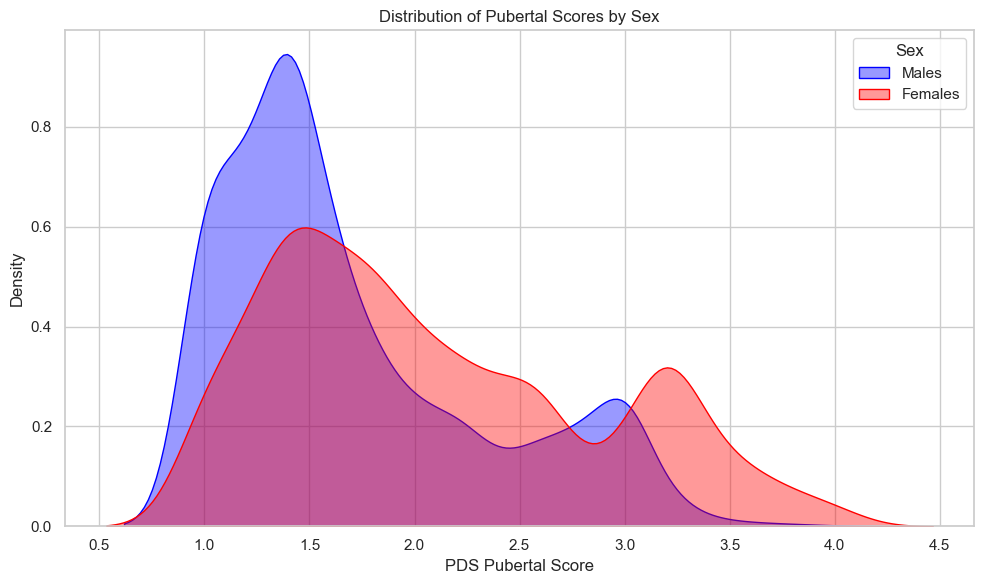

In [165]:
### Density plots
# This uses kernel density estimation (kdeplot) to visualize distributions smoothly.
# You can also adjust alpha to change transparency and fill=False if you'd prefer just the outline.

# Set style
sns.set(style="whitegrid")

# Create the plot
plt.figure(figsize=(10, 6))

# Plot male distribution
sns.kdeplot(
    data=abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'],
    x='pds_p_score',
    label='Males',
    color='blue',
    fill=True,
    alpha=0.4
)

# Plot female distribution
sns.kdeplot(
    data=abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'],
    x='pds_p_score',
    label='Females',
    color='red',
    fill=True,
    alpha=0.4
)

# Add labels and title
plt.xlabel("PDS Pubertal Score")
plt.ylabel("Density")
plt.title("Distribution of Pubertal Scores by Sex")
plt.legend(title="Sex")
plt.tight_layout()
plt.show()


/tmp/ipykernel_1454/3956193913.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Females", "Males"])


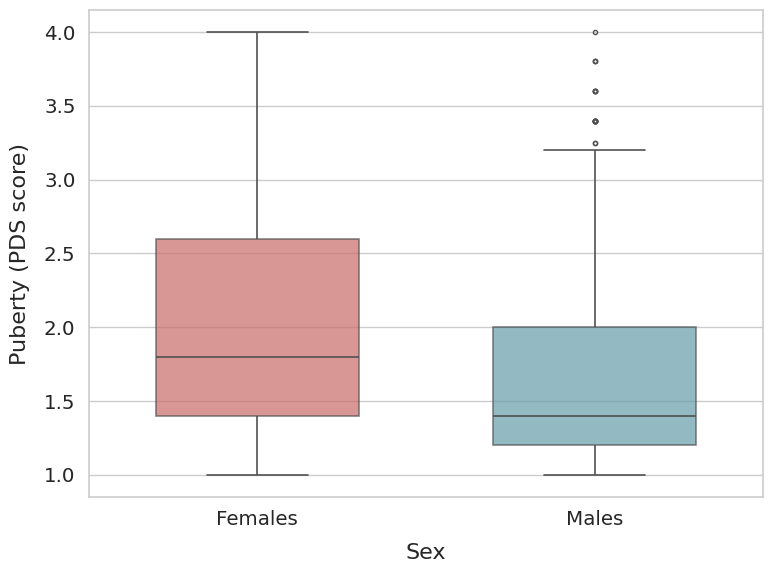

In [166]:

# Style setup
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
#sns.set_theme(style="white", font="DejaVu Sans", font_scale=1.3)

plt.rcParams["axes.linewidth"] = 1.2  # thicker axes for cleaner appearance
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create figure
plt.figure(figsize=(8, 6))

# Boxplot
ax = sns.boxplot(
    data=abcd_demo_all_clean,
    x="sex",
    y="pds_p_score",
    hue="sex",
    palette={"F": "#d85c59", "M": "#5aa3b5"},  # palette={'M': 'cadetblue', 'F': 'lightcoral'},
    dodge=False,
    width=0.6,
    linewidth=1.2,
    fliersize=3,
    boxprops={"alpha": 0.7},
)

#sns.despine(trim=True)

# Axis labels and title
ax.set_xlabel("Sex", fontsize=16, labelpad=10)
ax.set_ylabel("Puberty (PDS score)", fontsize=16, labelpad=10)
ax.set_xticklabels(["Females", "Males"])
#ax.set_title("Pubertal Scores by Sex", pad=15, weight="bold")

# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

#plt.savefig(resdir_fig+"boxplot_pds_by_sex.svg", format="svg", bbox_inches="tight", dpi=300)

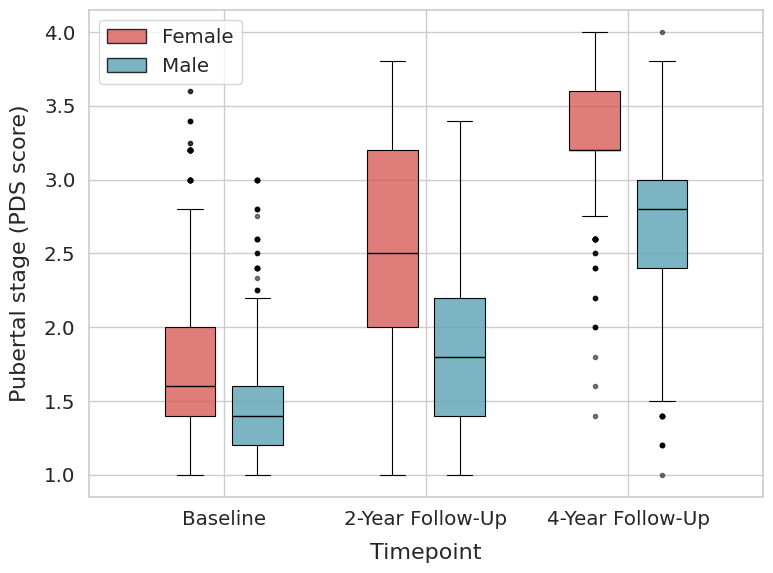

In [167]:
from matplotlib.patches import Patch
import matplotlib.colors as mcolors

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

alpha_map = {
    "Baseline": 0.8,  # 0.8
    "2-Year Follow-Up": 0.8,  # 0.8
    "4-Year Follow-Up": 0.8  # 0.8
}

sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

data = [
    abcd_demo_baseline_clean,
    abcd_demo_fu2y_clean,
    abcd_demo_fu4y_clean
]

# --- Style setup (consistent with your manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axes ---
fig, ax = plt.subplots(figsize=(8, 6))

# --- Function to draw SEX-SPLIT boxplots with TIMEPOINT alpha ---
def draw_boxplots(ax, data):

    box_width = 0.25
    offsets = [-box_width / 1.5, box_width / 1.5]  # F left, M right

    for tp_idx, tp in enumerate(timepoints):

        df_tp = data[tp_idx]
        alpha = alpha_map[tp]

        for sex_idx, sex in enumerate(["F", "M"]):

            df_sex = df_tp[df_tp["sex"] == sex]["pds_p_score"].dropna()

            color = sex_palette[sex]
            rgba = mcolors.to_rgba(color, alpha=alpha)

            position = tp_idx + offsets[sex_idx]

            bp = ax.boxplot(
                df_sex,
                positions=[position],
                widths=box_width,
                patch_artist=True,
                boxprops=dict(facecolor=rgba, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8),
                flierprops=dict(
                    marker='o',
                    markersize=3,
                    alpha=0.5,
                    markerfacecolor='black',
                    markeredgecolor='black'
                )
            )


# --- Draw boxplots ---
draw_boxplots(ax, data)

# --- Axis labels ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("Pubertal stage (PDS score)", fontsize=16, labelpad=10)

# --- Legend (Sex only, alpha encoded visually) ---
legend_elements = [
    Patch(facecolor=sex_palette["F"], alpha=0.8, edgecolor="black", label="Female"),
    Patch(facecolor=sex_palette["M"], alpha=0.8, edgecolor="black", label="Male"),
]
ax.legend(handles=legend_elements, loc="upper left", frameon=True)




# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(
    resdir_fig + "boxplot_pds_by_sex_by_timepoint.svg",
    format="svg",
    bbox_inches="tight",
    dpi=300
)


#### Collinearity age-puberty

In [154]:
stats.spearmanr(abcd_demo_all_clean.age_months, abcd_demo_all_clean.pds_p_score)

SignificanceResult(statistic=0.5917093232732135, pvalue=0.0)

In [252]:
# collinearity (correlation) by sex

for sex, grp in abcd_demo_all_clean.groupby('sex'):
    rho, p = stats.spearmanr(grp.age_months, grp.pds_p_score, nan_policy='omit')
    print(f"{sex}: rho = {rho:.3f}, p = {p:.3g}, n = {len(grp)}")

F: rho = 0.669, p = 0, n = 3168
M: rho = 0.580, p = 1.41e-269, n = 3003


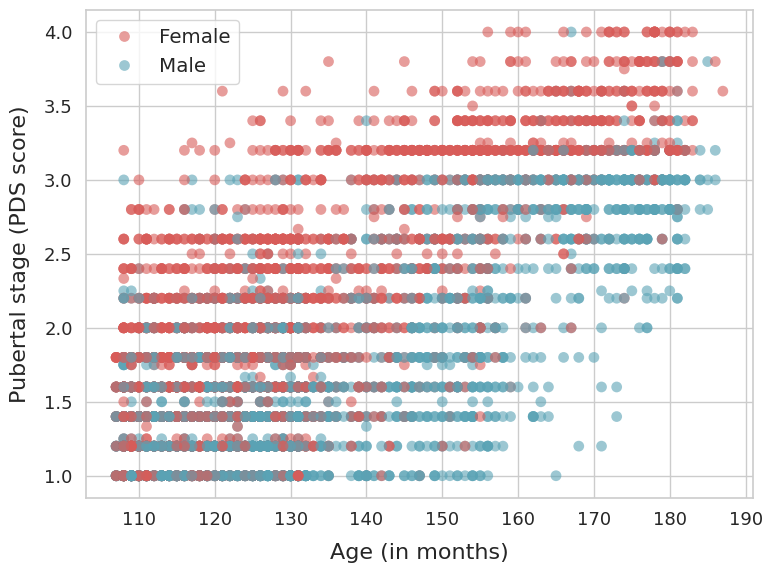

In [157]:

df_plot = abcd_demo_all_clean[['age_months', 'pds_p_score', 'sex']]

# --- Plot setup ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

fig, ax = plt.subplots(figsize=(8, 6))

# Define the colors used in your previous plot
sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

# --- Scatterplot (color-coded by Sex) ---
sns.scatterplot(
    data=df_plot,
    x="age_months", 
    y="pds_p_score",
    hue="sex",           # Map color to sex
    palette=sex_palette, # Use your specific colors
    s=60, 
    alpha=0.6,           # Reduced alpha slightly to see overlapping points
    edgecolor="none",    # Removing edgecolors makes high-density plots cleaner
    ax=ax
)

# --- Aesthetics ---
ax.set_xlabel("Age (in months)", fontsize=16, labelpad=10)
ax.set_ylabel("Pubertal stage (PDS score)", fontsize=16, labelpad=10)
ax.tick_params(labelsize=13)

# --- Legend ---
# This creates a clean legend using your palette labels
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=['Female', 'Male'], loc='upper left')

plt.tight_layout()
#plt.show()


# save figure in directory 
plt.savefig(resdir_fig+'age_puberty_correspondance.svg', dpi=300, bbox_inches="tight")  # bbox_inches is so that the figure doesn't get cut off when saving

Variance Inflation Factor

In [156]:
from statsmodels.stats.outliers_influence import variance_inflation_factor


# Create a subset of your predictors
X = abcd_demo_all_clean[['age_months', 'pds_p_score']]

# Add a constant (required for VIF calculation)
X['intercept'] = 1

vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]
print(vif_data)

       feature        VIF
0   age_months   1.996272
1  pds_p_score   1.996272
2    intercept  54.431033


/tmp/ipykernel_1454/2572699726.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['intercept'] = 1


In [170]:
# vif by sex

import statsmodels.api as sm

vif_results = []

for sex, grp in abcd_demo_all_clean.groupby('sex'):
    X = grp[['age_months', 'pds_p_score']].dropna()
    X = sm.add_constant(X)  # adds 'const' column

    for i, col in enumerate(X.columns):
        if col == 'const':
            continue
        vif_results.append({
            'sex': sex,
            'feature': col,
            'VIF': variance_inflation_factor(X.values, i),
            'n': len(X)
        })

vif_df = pd.DataFrame(vif_results)
print(vif_df)

  sex      feature       VIF     n
0   F   age_months  2.428333  3168
1   F  pds_p_score  2.428333  3168
2   M   age_months  2.161907  3003
3   M  pds_p_score  2.161907  3003


How many subjects

In [171]:
df = abcd_demo_all_clean.copy()

# Bins: [1, 2), [2, 3), [3, 4]
df['pds_bin'] = pd.cut(
    df['pds_p_score'],
    bins=[1, 2, 3, 4.0001],
    right=False,
    labels=['1-1.99', '2-2.99', '3-4']
)

bin_counts = pd.crosstab(df['pds_bin'], df['sex'], margins=True, margins_name='Total')
print(bin_counts)

# Exactly PDS = 4
df['pds_is_4'] = np.isclose(df['pds_p_score'], 4)
pds4_counts = df.loc[df['pds_is_4']].groupby('sex').size()
pds4_counts['Total'] = pds4_counts.sum()
print("\nSubjects with PDS = 4:")
print(pds4_counts)

sex         F     M  Total
pds_bin                   
1-1.99   1589  2157   3746
2-2.99    920   595   1515
3-4       659   251    910
Total    3168  3003   6171

Subjects with PDS = 4:
sex
F        31
M         1
Total    32
dtype: int64


#### Race

In [146]:
abcd_p_demo = pd.read_csv(datadir+'abcd-data-release-5.1/core/abcd-general/abcd_p_demo.csv')
abcd_p_demo

,src_subject_id,eventname,demoi_p_select_language___1,demo_prim,demo_brthdat_v2,demo_ed_v2,demo_adopt_agex_v2,demo_adopt_agex_v2_bl_dk,demo_sex_v2,demo_gender_id_v2,...,demo_nat_lang_3_yrs_other_p_14,demo_nat_lang_3_p,demo_nat_lang_3_yrs_eng_p___1,demo_nat_lang_3_yrs_eng_p___2,demo_nat_lang_3_yrs_eng_p___3,demo_nat_lang_3_yrs_eng_p___4,demo_nat_lang_3_yrs_eng_p___5,demo_nat_lang_3_yrs_eng_p___6,race_ethnicity,acs_raked_propensity_score
0,NDAR_INV003RTV85,baseline_year_1_arm_1,0,1.0,10.0,5.0,NaN,NaN,2.0,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,466.092707
1,NDAR_INV003RTV85,1_year_follow_up_y_arm_1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,533.381820
2,NDAR_INV003RTV85,2_year_follow_up_y_arm_1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NDAR_INV003RTV85,3_year_follow_up_y_arm_1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NDAR_INV005V6D2C,baseline_year_1_arm_1,1,1.0,10.0,4.0,NaN,NaN,2.0,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,520.488325
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48802,NDAR_INVZZZP87KR,baseline_year_1_arm_1,0,1.0,10.0,5.0,NaN,NaN,2.0,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,835.604891
48803,NDAR_INVZZZP87KR,1_year_follow_up_y_arm_1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,842.080358
48804,NDAR_INVZZZP87KR,2_year_follow_up_y_arm_1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
48805,NDAR_INVZZZP87KR,3_year_follow_up_y_arm_1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [147]:
# take one entry per subject because we only need the information once (baseline has the info for all)
abcd_p_demo_overall =  abcd_p_demo[abcd_p_demo['eventname'] == 'baseline_year_1_arm_1']

# Create a new column with the reformatted IDs to match IDs in MPI folders
abcd_p_demo_overall['src_subject_id_fmt'] = abcd_p_demo_overall['src_subject_id'].apply(lambda x: 'sub-' + x.replace('_INV', 'INV'))


# only keep subjects that are in the final sample
abcd_p_demo_overall = abcd_p_demo_overall[abcd_p_demo_overall['src_subject_id_fmt'].isin(abcd_demo_all_clean.src_subject_id_fmt)]


# taking only a subset of df with relevant race columns
abcd_p_demo_overall = abcd_p_demo_overall[["src_subject_id_fmt", 'demo_race_a_p___10', 'demo_race_a_p___11', 'demo_race_a_p___12', 'demo_race_a_p___13', "demo_race_a_p___14", "demo_race_a_p___15","demo_race_a_p___16", 
                                             "demo_race_a_p___17", "demo_race_a_p___18", "demo_race_a_p___19", "demo_race_a_p___20", "demo_race_a_p___21", "demo_race_a_p___22", "demo_race_a_p___23", "demo_race_a_p___24", 
                                             "demo_race_a_p___25", "demo_race_a_p___0", "demo_race_a_p___77", "demo_race_a_p___99"]]


### Cleaning variables

# renaming some variables
abcd_p_demo_overall = abcd_p_demo_overall.rename(columns={"demo_race_a_p___10": "white", 
                                                                    "demo_race_a_p___11": "black", 
                                                                    "demo_race_a_p___12": "indian native", 
                                                                    "demo_race_a_p___13": "alaska native", 
                                                                    "demo_race_a_p___14": "hawaii native", 
                                                                    "demo_race_a_p___15": "guamanian", 
                                                                    "demo_race_a_p___16": "samoan",
                                                                    "demo_race_a_p___17": "other pacific",
                                                                    "demo_race_a_p___18": "asian indian",
                                                                    "demo_race_a_p___19": "chinese",
                                                                    "demo_race_a_p___20": "filipino",
                                                                    "demo_race_a_p___21": "japanese",
                                                                    "demo_race_a_p___22": "korean",
                                                                    "demo_race_a_p___23": "vietnamese",
                                                                    "demo_race_a_p___24": "other asian",
                                                                    "demo_race_a_p___25": "other race", 
                                                                    "demo_race_a_p___0": "none",
                                                                    "demo_race_a_p___77": "decline",
                                                                    "demo_race_a_p___99": "dont know"
                                                                   })



/tmp/ipykernel_1454/2058291093.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  abcd_p_demo_overall['src_subject_id_fmt'] = abcd_p_demo_overall['src_subject_id'].apply(lambda x: 'sub-' + x.replace('_INV', 'INV'))


In [148]:
options = ['white', 'black', 'indian native','alaska native', 'hawaii native', 'guamanian', 'samoan', 'other pacific', 'asian indian', 'chinese', 'filipino', 'japanese','korean', 'vietnamese', 
         'other asian', 'other race', 'none', 'decline', 'dont know']

races = ['white', 'black', 'indian native','alaska native', 'hawaii native', 'guamanian', 'samoan', 'other pacific', 'asian indian', 'chinese', 'filipino', 'japanese','korean', 'vietnamese', 
         'other asian', 'other race']


## create a final race column

# Count actual race selections only
abcd_p_demo_overall["n_races"] = abcd_p_demo_overall[races].sum(axis=1)

# Create race column safely
abcd_p_demo_overall["race"] = pd.NA

# Mixed race
abcd_p_demo_overall.loc[
    abcd_p_demo_overall["n_races"] > 1,
    "race"
] = "mixed"

# Single race (exactly one race selected)
mask_single = abcd_p_demo_overall["n_races"] == 1

abcd_p_demo_overall.loc[mask_single, "race"] = (
    abcd_p_demo_overall.loc[mask_single, races]
    .idxmax(axis=1)
)

# Handle the non-race responses
# none selected
abcd_p_demo_overall.loc[
    (abcd_p_demo_overall["n_races"] == 0) &
    (abcd_p_demo_overall["none"] == 1),
    "race"
] = "none"

# decline
abcd_p_demo_overall.loc[
    (abcd_p_demo_overall["n_races"] == 0) &
    (abcd_p_demo_overall["decline"] == 1),
    "race"
] = "decline"

# dont know
abcd_p_demo_overall.loc[
    (abcd_p_demo_overall["n_races"] == 0) &
    (abcd_p_demo_overall["dont know"] == 1),
    "race"
] = "dont know"

# replace na values with a string "NaN" so that it appears in the counts
abcd_p_demo_overall["race"] = (
    abcd_p_demo_overall["race"]
    .fillna("NaN")
)


## map races into categories

race_map = {
    # keep as is
    "white": "white",
    "black": "black",
    "mixed": "mixed",
    
    # asian
    "asian indian": "asian",
    "chinese": "asian",
    "filipino": "asian",
    "japanese": "asian",
    "korean": "asian",
    "vietnamese": "asian",
    "other asian": "asian",
    
    # pacific islander
    "hawaii native": "pacific islander",
    "guamanian": "pacific islander",
    "samoan": "pacific islander",
    "other pacific": "pacific islander",
    
    # native american
    "indian native": "native american",
    "alaska native": "native american",
    
    # other
    "other race": "other",
    
    # missing
    "none": "missing",
    "dont know": "missing",
    "decline": "missing",
    "NaN": "missing"
}

abcd_p_demo_overall["race cat"] = (
    abcd_p_demo_overall["race"]
    .map(race_map)
)


In [149]:
abcd_p_demo_overall

,src_subject_id_fmt,white,black,indian native,alaska native,hawaii native,guamanian,samoan,other pacific,asian indian,...,korean,vietnamese,other asian,other race,none,decline,dont know,n_races,race,race cat
0,sub-NDARINV003RTV85,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,white,white
8,sub-NDARINV007W6H7B,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,white,white
14,sub-NDARINV00CY2MDM,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,white,white
19,sub-NDARINV00HEV6HB,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,black,black
24,sub-NDARINV00J52GPG,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,decline,missing
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48767,sub-NDARINVZZFG6J5U,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,white,white
48785,sub-NDARINVZZNX6W2P,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,white,white
48790,sub-NDARINVZZPKBDAC,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,white,white
48795,sub-NDARINVZZZ2ALR6,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,mixed,mixed


In [150]:
abcd_p_demo_overall['race'].value_counts()

race
white            3441
mixed             572
black             501
other race        166
chinese            30
dont know          29
indian native      28
asian indian       21
decline            15
other asian        14
filipino           11
NaN                 8
vietnamese          7
korean              6
japanese            3
other pacific       3
samoan              1
Name: count, dtype: int64

In [151]:
abcd_p_demo_overall['race cat'].value_counts()

race cat
white               3441
mixed                572
black                501
other                166
asian                 92
missing               52
native american       28
pacific islander       4
Name: count, dtype: int64

In [153]:
abcd_p_demo_overall["race cat"] \
    .value_counts(normalize=True) \
    .mul(100) \
    .round(2)

race cat
white               70.86
mixed               11.78
black               10.32
other                3.42
asian                1.89
missing              1.07
native american      0.58
pacific islander     0.08
Name: proportion, dtype: float64

#### CBCL

Describe total symptoms and symptom diensions

In [103]:
print("CBCL Total Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_all_clean.cbcl_tot[abcd_demo_all_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_all_clean.cbcl_tot[abcd_demo_all_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_all_clean.cbcl_tot[abcd_demo_all_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_all_clean.cbcl_tot[abcd_demo_all_clean.sex == 'M']):.2f}")

print("\nCBCL Internalizing Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_all_clean.cbcl_int[abcd_demo_all_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_all_clean.cbcl_int[abcd_demo_all_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_all_clean.cbcl_int[abcd_demo_all_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_all_clean.cbcl_int[abcd_demo_all_clean.sex == 'M']):.2f}")

print("\nCBCL Externalizing Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_all_clean.cbcl_ext[abcd_demo_all_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_all_clean.cbcl_ext[abcd_demo_all_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_all_clean.cbcl_ext[abcd_demo_all_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_all_clean.cbcl_ext[abcd_demo_all_clean.sex == 'M']):.2f}")

CBCL Total Symptoms
Females: Mean: 15.04, SD: 15.06
Males: Mean: 17.45, SD: 17.53

CBCL Internalizing Symptoms
Females: Mean: 5.25, SD: 5.61
Males: Mean: 4.79, SD: 5.34

CBCL Externalizing Symptoms
Females: Mean: 3.33, SD: 4.68
Males: Mean: 4.39, SD: 5.86


In [104]:
print("CBCL Total Symptoms")
print(stats.levene(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].cbcl_tot, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].cbcl_tot, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].cbcl_tot, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].cbcl_tot, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

print("\nCBCL Internalizing Symptoms")
print(stats.levene(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].cbcl_int, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].cbcl_int, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].cbcl_int, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].cbcl_int, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

print("\nCBCL Externalizing Symptoms")
print(stats.levene(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].cbcl_ext, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].cbcl_ext, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].cbcl_ext, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].cbcl_ext, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

CBCL Total Symptoms
LeveneResult(statistic=25.050822401173516, pvalue=5.735100883504716e-07)
FlignerResult(statistic=40.861178301485204, pvalue=1.634357329423899e-10)

CBCL Internalizing Symptoms
LeveneResult(statistic=4.565922729924627, pvalue=0.03265240516086229)
FlignerResult(statistic=25.132986602559846, pvalue=5.350965716544322e-07)

CBCL Externalizing Symptoms
LeveneResult(statistic=54.439800132035465, pvalue=1.8087765338734176e-13)
FlignerResult(statistic=51.45564941940058, pvalue=7.32329395608101e-13)


In [105]:
print("CBCL Total Symptoms")
print(f"{stats.ttest_ind(abcd_demo_all_clean.cbcl_tot[abcd_demo_all_clean.sex == 'F'], abcd_demo_all_clean.cbcl_tot[abcd_demo_all_clean.sex == 'M'], nan_policy='omit')}")

print("\nCBCL Internalizing Symptoms")
print(f"{stats.ttest_ind(abcd_demo_all_clean.cbcl_int[abcd_demo_all_clean.sex == 'F'], abcd_demo_all_clean.cbcl_int[abcd_demo_all_clean.sex == 'M'], nan_policy='omit')}")

print("\nCBCL Externalizing Symptoms")
print(f"{stats.ttest_ind(abcd_demo_all_clean.cbcl_ext[abcd_demo_all_clean.sex == 'F'], abcd_demo_all_clean.cbcl_ext[abcd_demo_all_clean.sex == 'M'], nan_policy='omit')}")

CBCL Total Symptoms
TtestResult(statistic=-5.874948871151165, pvalue=4.445123599997868e-09, df=6317.0)

CBCL Internalizing Symptoms
TtestResult(statistic=3.2653330827102782, pvalue=0.0010991814079618963, df=6317.0)

CBCL Externalizing Symptoms
TtestResult(statistic=-7.943101192404206, pvalue=2.3173388308024874e-15, df=6317.0)


In [106]:
print("CBCL Total Symptoms")
print(stats.mannwhitneyu(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].cbcl_tot, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].cbcl_tot, nan_policy='omit'))

print("\nCBCL Internalizing Symptoms")
print(stats.mannwhitneyu(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].cbcl_int, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].cbcl_int, nan_policy='omit'))

print("\nCBCL Externalizing Symptoms")
print(stats.mannwhitneyu(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].cbcl_ext, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].cbcl_ext, nan_policy='omit'))

CBCL Total Symptoms
MannwhitneyuResult(statistic=5360732.5, pvalue=2.985428476547452e-07)

CBCL Internalizing Symptoms
MannwhitneyuResult(statistic=4706833.0, pvalue=8.86273634158895e-05)

CBCL Externalizing Symptoms
MannwhitneyuResult(statistic=5495349.0, pvalue=1.2807822199154854e-12)


Checking NaNs

In [107]:
abcd_demo_all_clean["cbcl_tot"].isna().sum()

2

In [108]:
abcd_demo_all_clean["cbcl_int"].isna().sum()

2

In [109]:
abcd_demo_all_clean["cbcl_ext"].isna().sum()

2

In [110]:
abcd_demo_all_clean[abcd_demo_all_clean["cbcl_tot"].isna()]

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMI,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y
66,sub-NDARINV1DDX454E,9.0,M,17.0,2_year_follow_up_y_arm_1,site21,4727.0,132.0,1.0,3.0,1.2,2.2,23.144033,217172.631572,NaN,NaN,NaN,NaN
83,sub-NDARINV2GDYKWG2,10.0,F,18.0,4_year_follow_up_y_arm_1,site06,8812.0,168.0,4.0,4.0,3.4,3.4,19.779216,187139.982964,NaN,NaN,NaN,8.0


In [111]:
# Need to remove nans for plotting
abcd_demo_all_clean_omit_nan = abcd_demo_all_clean.dropna(subset=["cbcl_tot", "cbcl_int", "cbcl_ext"])
abcd_demo_baseline_clean_omit_nan = abcd_demo_baseline_clean.dropna(subset=["cbcl_tot", "cbcl_int", "cbcl_ext"])
abcd_demo_fu2y_clean_omit_nan = abcd_demo_fu2y_clean.dropna(subset=["cbcl_tot", "cbcl_int", "cbcl_ext"])
abcd_demo_fu4y_clean_omit_nan = abcd_demo_fu4y_clean.dropna(subset=["cbcl_tot", "cbcl_int", "cbcl_ext"])

Plots = Total Symptoms

/tmp/ipykernel_60461/3294123443.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Females", "Males"])


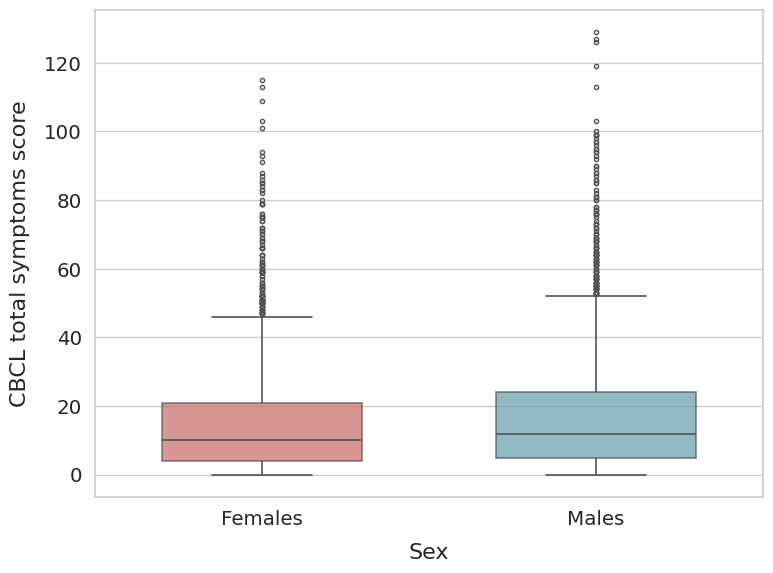

In [112]:
# Style setup
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
#sns.set_theme(style="white", font="DejaVu Sans", font_scale=1.3)

plt.rcParams["axes.linewidth"] = 1.2  # thicker axes for cleaner appearance
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create figure
plt.figure(figsize=(8, 6))

# Boxplot
ax = sns.boxplot(
    data=abcd_demo_all_clean_omit_nan,
    x="sex",
    y="cbcl_tot",
    hue="sex",
    palette={"F": "#d85c59", "M": "#5aa3b5"},  # palette={'M': 'cadetblue', 'F': 'lightcoral'},
    dodge=False,
    width=0.6,
    linewidth=1.2,
    fliersize=3,
    boxprops={"alpha": 0.7},
)

#sns.despine(trim=True)

# Axis labels and title
ax.set_xlabel("Sex", fontsize=16, labelpad=10)
ax.set_ylabel("CBCL total symptoms score", fontsize=16, labelpad=10)
ax.set_xticklabels(["Females", "Males"])
#ax.set_title("Pubertal Scores by Sex", pad=15, weight="bold")

# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(resdir_fig+"boxplot_cbcl_tot_by_sex.svg", format="svg", bbox_inches="tight", dpi=300)

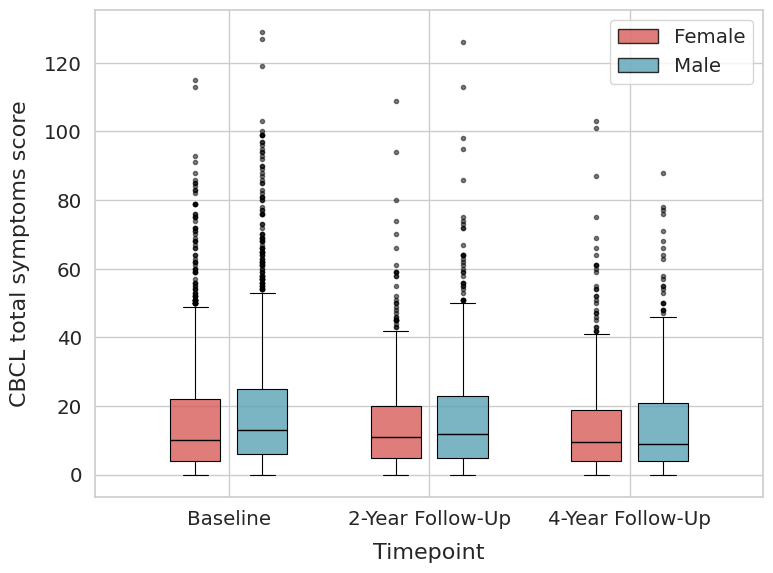

In [113]:
from matplotlib.patches import Patch
import matplotlib.colors as mcolors

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

alpha_map = {
    "Baseline": 0.8,  # 0.8
    "2-Year Follow-Up": 0.8,  # 0.8
    "4-Year Follow-Up": 0.8  # 0.8
}

sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

data = [
    abcd_demo_baseline_clean_omit_nan,
    abcd_demo_fu2y_clean_omit_nan,
    abcd_demo_fu4y_clean_omit_nan
]

# --- Style setup (consistent with your manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axes ---
fig, ax = plt.subplots(figsize=(8, 6))

# --- Function to draw SEX-SPLIT boxplots with TIMEPOINT alpha ---
def draw_boxplots(ax, data):

    box_width = 0.25
    offsets = [-box_width / 1.5, box_width / 1.5]  # F left, M right

    for tp_idx, tp in enumerate(timepoints):

        df_tp = data[tp_idx]
        alpha = alpha_map[tp]

        for sex_idx, sex in enumerate(["F", "M"]):

            df_sex = df_tp[df_tp["sex"] == sex]["cbcl_tot"].dropna()

            color = sex_palette[sex]
            rgba = mcolors.to_rgba(color, alpha=alpha)

            position = tp_idx + offsets[sex_idx]

            bp = ax.boxplot(
                df_sex,
                positions=[position],
                widths=box_width,
                patch_artist=True,
                boxprops=dict(facecolor=rgba, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8),
                flierprops=dict(
                    marker='o',
                    markersize=3,
                    alpha=0.5,
                    markerfacecolor='black',
                    markeredgecolor='black'
                )
            )


# --- Draw boxplots ---
draw_boxplots(ax, data)

# --- Axis labels ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("CBCL total symptoms score", fontsize=16, labelpad=10)

# --- Legend (Sex only, alpha encoded visually) ---
legend_elements = [
    Patch(facecolor=sex_palette["F"], alpha=0.8, edgecolor="black", label="Female"),
    Patch(facecolor=sex_palette["M"], alpha=0.8, edgecolor="black", label="Male"),
]
ax.legend(handles=legend_elements, loc="upper right", frameon=True)




# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(
    resdir_fig + "boxplot_cbcl_tot_by_sex_by_timepoint.svg",
    format="svg",
    bbox_inches="tight",
    dpi=300
)


Plots = Internalizing Symptoms

/tmp/ipykernel_60461/754615528.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Females", "Males"])


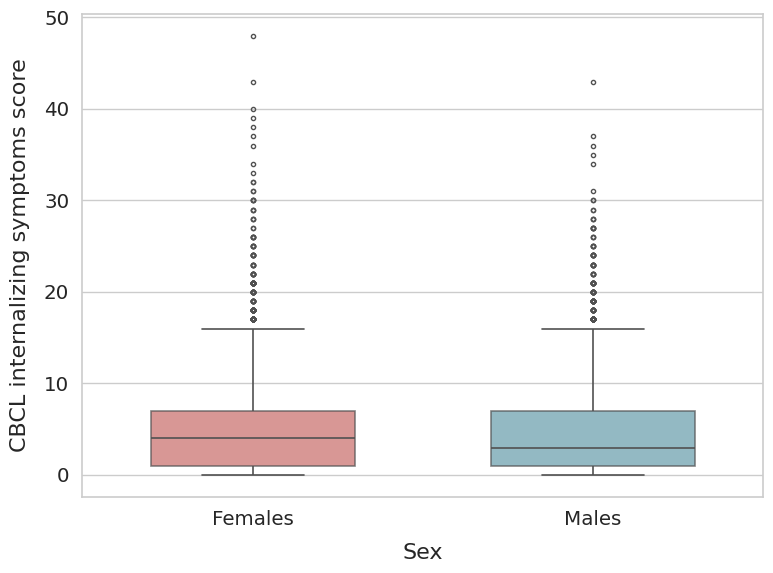

In [114]:
# Style setup
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
#sns.set_theme(style="white", font="DejaVu Sans", font_scale=1.3)

plt.rcParams["axes.linewidth"] = 1.2  # thicker axes for cleaner appearance
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create figure
plt.figure(figsize=(8, 6))

# Boxplot
ax = sns.boxplot(
    data=abcd_demo_all_clean_omit_nan,
    x="sex",
    y="cbcl_int",
    hue="sex",
    palette={"F": "#d85c59", "M": "#5aa3b5"},  # palette={'M': 'cadetblue', 'F': 'lightcoral'},
    dodge=False,
    width=0.6,
    linewidth=1.2,
    fliersize=3,
    boxprops={"alpha": 0.7},
)

#sns.despine(trim=True)

# Axis labels and title
ax.set_xlabel("Sex", fontsize=16, labelpad=10)
ax.set_ylabel("CBCL internalizing symptoms score", fontsize=16, labelpad=10)
ax.set_xticklabels(["Females", "Males"])
#ax.set_title("Pubertal Scores by Sex", pad=15, weight="bold")

# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(resdir_fig+"boxplot_cbcl_int_by_sex.svg", format="svg", bbox_inches="tight", dpi=300)

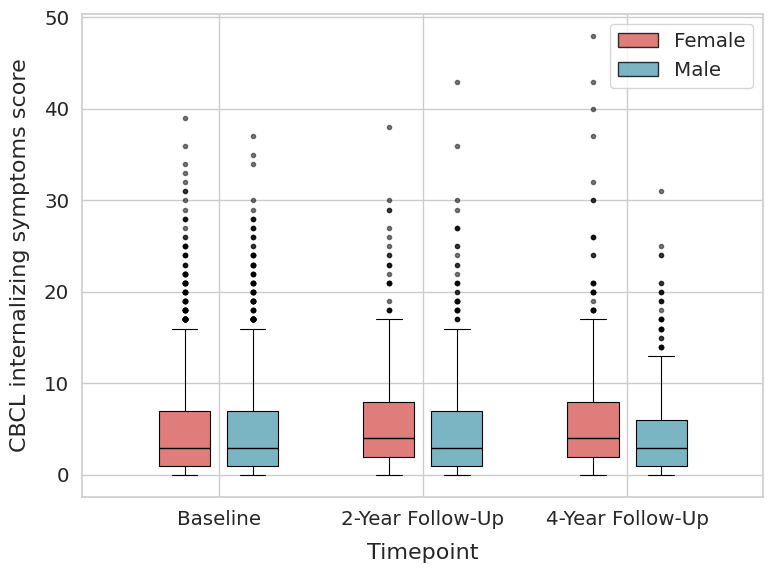

In [115]:
from matplotlib.patches import Patch
import matplotlib.colors as mcolors

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

alpha_map = {
    "Baseline": 0.8,  # 0.8
    "2-Year Follow-Up": 0.8,  # 0.8
    "4-Year Follow-Up": 0.8  # 0.8
}

sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

data = [
    abcd_demo_baseline_clean_omit_nan,
    abcd_demo_fu2y_clean_omit_nan,
    abcd_demo_fu4y_clean_omit_nan
]

# --- Style setup (consistent with your manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axes ---
fig, ax = plt.subplots(figsize=(8, 6))

# --- Function to draw SEX-SPLIT boxplots with TIMEPOINT alpha ---
def draw_boxplots(ax, data):

    box_width = 0.25
    offsets = [-box_width / 1.5, box_width / 1.5]  # F left, M right

    for tp_idx, tp in enumerate(timepoints):

        df_tp = data[tp_idx]
        alpha = alpha_map[tp]

        for sex_idx, sex in enumerate(["F", "M"]):

            df_sex = df_tp[df_tp["sex"] == sex]["cbcl_int"].dropna()

            color = sex_palette[sex]
            rgba = mcolors.to_rgba(color, alpha=alpha)

            position = tp_idx + offsets[sex_idx]

            bp = ax.boxplot(
                df_sex,
                positions=[position],
                widths=box_width,
                patch_artist=True,
                boxprops=dict(facecolor=rgba, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8),
                flierprops=dict(
                    marker='o',
                    markersize=3,
                    alpha=0.5,
                    markerfacecolor='black',
                    markeredgecolor='black'
                )
            )


# --- Draw boxplots ---
draw_boxplots(ax, data)

# --- Axis labels ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("CBCL internalizing symptoms score", fontsize=16, labelpad=10)

# --- Legend (Sex only, alpha encoded visually) ---
legend_elements = [
    Patch(facecolor=sex_palette["F"], alpha=0.8, edgecolor="black", label="Female"),
    Patch(facecolor=sex_palette["M"], alpha=0.8, edgecolor="black", label="Male"),
]
ax.legend(handles=legend_elements, loc="upper right", frameon=True)




# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(
    resdir_fig + "boxplot_cbcl_int_by_sex_by_timepoint.svg",
    format="svg",
    bbox_inches="tight",
    dpi=300
)


Plots = Externalizing Symptoms

/tmp/ipykernel_60461/3452833889.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Females", "Males"])


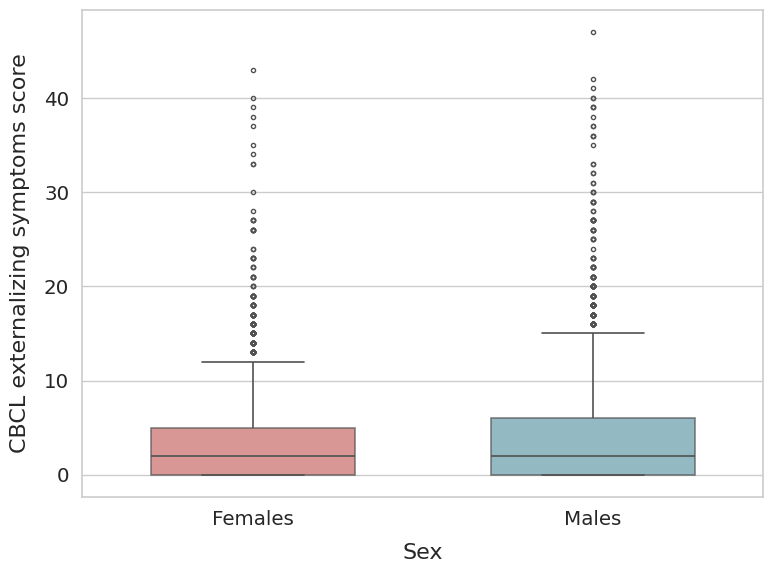

In [116]:
# Style setup
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
#sns.set_theme(style="white", font="DejaVu Sans", font_scale=1.3)

plt.rcParams["axes.linewidth"] = 1.2  # thicker axes for cleaner appearance
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create figure
plt.figure(figsize=(8, 6))

# Boxplot
ax = sns.boxplot(
    data=abcd_demo_all_clean_omit_nan,
    x="sex",
    y="cbcl_ext",
    hue="sex",
    palette={"F": "#d85c59", "M": "#5aa3b5"},  # palette={'M': 'cadetblue', 'F': 'lightcoral'},
    dodge=False,
    width=0.6,
    linewidth=1.2,
    fliersize=3,
    boxprops={"alpha": 0.7},
)

#sns.despine(trim=True)

# Axis labels and title
ax.set_xlabel("Sex", fontsize=16, labelpad=10)
ax.set_ylabel("CBCL externalizing symptoms score", fontsize=16, labelpad=10)
ax.set_xticklabels(["Females", "Males"])
#ax.set_title("Pubertal Scores by Sex", pad=15, weight="bold")

# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(resdir_fig+"boxplot_cbcl_ext_by_sex.svg", format="svg", bbox_inches="tight", dpi=300)

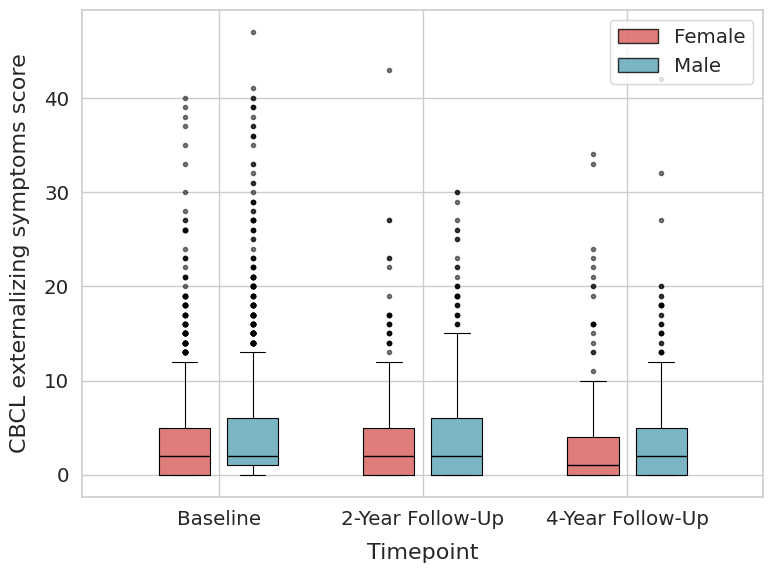

In [117]:
from matplotlib.patches import Patch
import matplotlib.colors as mcolors

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

alpha_map = {
    "Baseline": 0.8,  # 0.8
    "2-Year Follow-Up": 0.8,  # 0.8
    "4-Year Follow-Up": 0.8  # 0.8
}

sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

data = [
    abcd_demo_baseline_clean_omit_nan,
    abcd_demo_fu2y_clean_omit_nan,
    abcd_demo_fu4y_clean_omit_nan
]

# --- Style setup (consistent with your manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axes ---
fig, ax = plt.subplots(figsize=(8, 6))

# --- Function to draw SEX-SPLIT boxplots with TIMEPOINT alpha ---
def draw_boxplots(ax, data):

    box_width = 0.25
    offsets = [-box_width / 1.5, box_width / 1.5]  # F left, M right

    for tp_idx, tp in enumerate(timepoints):

        df_tp = data[tp_idx]
        alpha = alpha_map[tp]

        for sex_idx, sex in enumerate(["F", "M"]):

            df_sex = df_tp[df_tp["sex"] == sex]["cbcl_ext"].dropna()

            color = sex_palette[sex]
            rgba = mcolors.to_rgba(color, alpha=alpha)

            position = tp_idx + offsets[sex_idx]

            bp = ax.boxplot(
                df_sex,
                positions=[position],
                widths=box_width,
                patch_artist=True,
                boxprops=dict(facecolor=rgba, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8),
                flierprops=dict(
                    marker='o',
                    markersize=3,
                    alpha=0.5,
                    markerfacecolor='black',
                    markeredgecolor='black'
                )
            )


# --- Draw boxplots ---
draw_boxplots(ax, data)

# --- Axis labels ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("CBCL externalizing symptoms score", fontsize=16, labelpad=10)

# --- Legend (Sex only, alpha encoded visually) ---
legend_elements = [
    Patch(facecolor=sex_palette["F"], alpha=0.8, edgecolor="black", label="Female"),
    Patch(facecolor=sex_palette["M"], alpha=0.8, edgecolor="black", label="Male"),
]
ax.legend(handles=legend_elements, loc="upper right", frameon=True)




# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(
    resdir_fig + "boxplot_cbcl_ext_by_sex_by_timepoint.svg",
    format="svg",
    bbox_inches="tight",
    dpi=300
)


#### Family Conflict (FES)

In [118]:
abcd_demo_all_clean.fam_conflict_y.value_counts()

fam_conflict_y
0.0    1833
1.0    1446
2.0    1049
3.0     716
4.0     550
5.0     334
6.0     197
7.0     136
8.0      39
9.0      16
Name: count, dtype: int64

In [119]:
print(f"Females: Mean: {np.mean(abcd_demo_all_clean.fam_conflict_y[abcd_demo_all_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_all_clean.fam_conflict_y[abcd_demo_all_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_all_clean.fam_conflict_y[abcd_demo_all_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_all_clean.fam_conflict_y[abcd_demo_all_clean.sex == 'M']):.2f}")

Females: Mean: 1.88, SD: 1.94
Males: Mean: 1.97, SD: 1.91


In [120]:
print(stats.levene(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].fam_conflict_y, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].fam_conflict_y, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

CBCL Total Symptoms
LeveneResult(statistic=0.02368483701231276, pvalue=0.8776944580046452)
FlignerResult(statistic=0.025566407652623812, pvalue=0.8729637955749926)


In [121]:
print(f"{stats.ttest_ind(abcd_demo_all_clean.fam_conflict_y[abcd_demo_all_clean.sex == 'F'], abcd_demo_all_clean.fam_conflict_y[abcd_demo_all_clean.sex == 'M'], nan_policy='omit')}")

TtestResult(statistic=-1.9543288170391635, pvalue=0.05070642072378096, df=6314.0)


In [122]:
print(stats.mannwhitneyu(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].fam_conflict_y, nan_policy='omit'))

MannwhitneyuResult(statistic=5180049.0, pvalue=0.005829610084576603)


Checking NaNs

In [123]:
abcd_demo_all_clean["fam_conflict_y"].isna().sum()

5

Plots

In [260]:
# Need to remove nans for plotting  fpr family conflict
abcd_demo_all_clean_omit_nan = abcd_demo_all_clean.dropna(subset=["fam_conflict_y"])
abcd_demo_baseline_clean_omit_nan = abcd_demo_baseline_clean.dropna(subset=["fam_conflict_y"])
abcd_demo_fu2y_clean_omit_nan = abcd_demo_fu2y_clean.dropna(subset=["fam_conflict_y"])
abcd_demo_fu4y_clean_omit_nan = abcd_demo_fu4y_clean.dropna(subset=["fam_conflict_y"])

/tmp/ipykernel_60461/4167232621.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Females", "Males"])


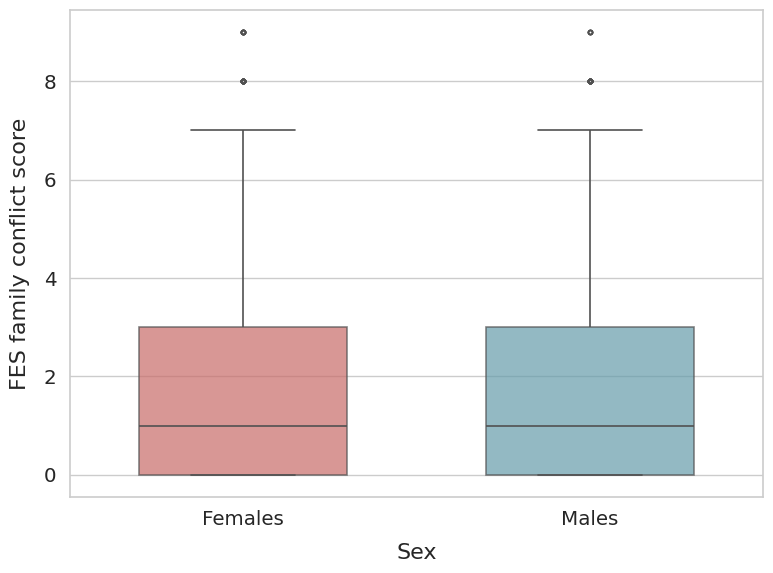

In [261]:
# Style setup
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
#sns.set_theme(style="white", font="DejaVu Sans", font_scale=1.3)

plt.rcParams["axes.linewidth"] = 1.2  # thicker axes for cleaner appearance
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create figure
plt.figure(figsize=(8, 6))

# Boxplot
ax = sns.boxplot(
    data=abcd_demo_all_clean_omit_nan,
    x="sex",
    y="fam_conflict_y",
    hue="sex",
    palette={"F": "#d85c59", "M": "#5aa3b5"},  # palette={'M': 'cadetblue', 'F': 'lightcoral'},
    dodge=False,
    width=0.6,
    linewidth=1.2,
    fliersize=3,
    boxprops={"alpha": 0.7},
)

#sns.despine(trim=True)

# Axis labels and title
ax.set_xlabel("Sex", fontsize=16, labelpad=10)
ax.set_ylabel("FES family conflict score", fontsize=16, labelpad=10)
ax.set_xticklabels(["Females", "Males"])
#ax.set_title("Pubertal Scores by Sex", pad=15, weight="bold")

# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(resdir_fig+"boxplot_fes_by_sex.svg", format="svg", bbox_inches="tight", dpi=300)

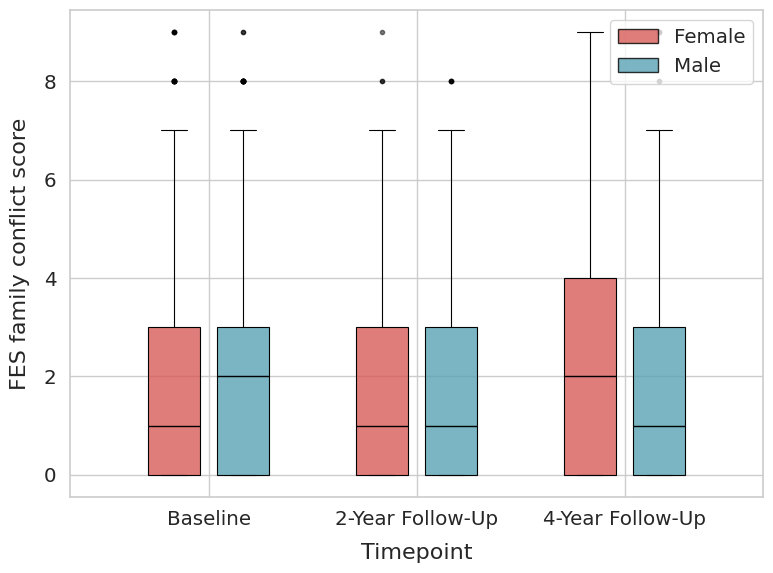

In [262]:
from matplotlib.patches import Patch
import matplotlib.colors as mcolors

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

alpha_map = {
    "Baseline": 0.8,  # 0.8
    "2-Year Follow-Up": 0.8,  # 0.8
    "4-Year Follow-Up": 0.8  # 0.8
}

sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

data = [
    abcd_demo_baseline_clean_omit_nan,
    abcd_demo_fu2y_clean_omit_nan,
    abcd_demo_fu4y_clean_omit_nan
]

# --- Style setup (consistent with your manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axes ---
fig, ax = plt.subplots(figsize=(8, 6))

# --- Function to draw SEX-SPLIT boxplots with TIMEPOINT alpha ---
def draw_boxplots(ax, data):

    box_width = 0.25
    offsets = [-box_width / 1.5, box_width / 1.5]  # F left, M right

    for tp_idx, tp in enumerate(timepoints):

        df_tp = data[tp_idx]
        alpha = alpha_map[tp]

        for sex_idx, sex in enumerate(["F", "M"]):

            df_sex = df_tp[df_tp["sex"] == sex]["fam_conflict_y"].dropna()

            color = sex_palette[sex]
            rgba = mcolors.to_rgba(color, alpha=alpha)

            position = tp_idx + offsets[sex_idx]

            bp = ax.boxplot(
                df_sex,
                positions=[position],
                widths=box_width,
                patch_artist=True,
                boxprops=dict(facecolor=rgba, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8),
                flierprops=dict(
                    marker='o',
                    markersize=3,
                    alpha=0.5,
                    markerfacecolor='black',
                    markeredgecolor='black'
                )
            )


# --- Draw boxplots ---
draw_boxplots(ax, data)

# --- Axis labels ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("FES family conflict score", fontsize=16, labelpad=10)

# --- Legend (Sex only, alpha encoded visually) ---
legend_elements = [
    Patch(facecolor=sex_palette["F"], alpha=0.8, edgecolor="black", label="Female"),
    Patch(facecolor=sex_palette["M"], alpha=0.8, edgecolor="black", label="Male"),
]
ax.legend(handles=legend_elements, loc="upper right", frameon=True)




# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(
    resdir_fig + "boxplot_fes_by_sex_by_timepoint.svg",
    format="svg",
    bbox_inches="tight",
    dpi=300
)


#### SES (parental education)

In [278]:
edu_parent_labels = {
    0: "Never attended / Kindergarten only",
    1: "1st grade",
    2: "2nd grade",
    3: "3rd grade",
    4: "4th grade",
    5: "5th grade",
    6: "6th grade",
    7: "7th grade",
    8: "8th grade",
    9: "9th grade",
    10: "10th grade",
    11: "11th grade",
    12: "12th grade",
    13: "High school graduate",
    14: "General Educational Development",  # General Educational Development
    15: "Some college",
    16: "Occupational associate degree",
    17: "Academic associate degree",
    18: "Bachelor’s degree",
    19: "Master’s degree",
    20: "Professional school degree",
    21: "Doctoral degree"
}

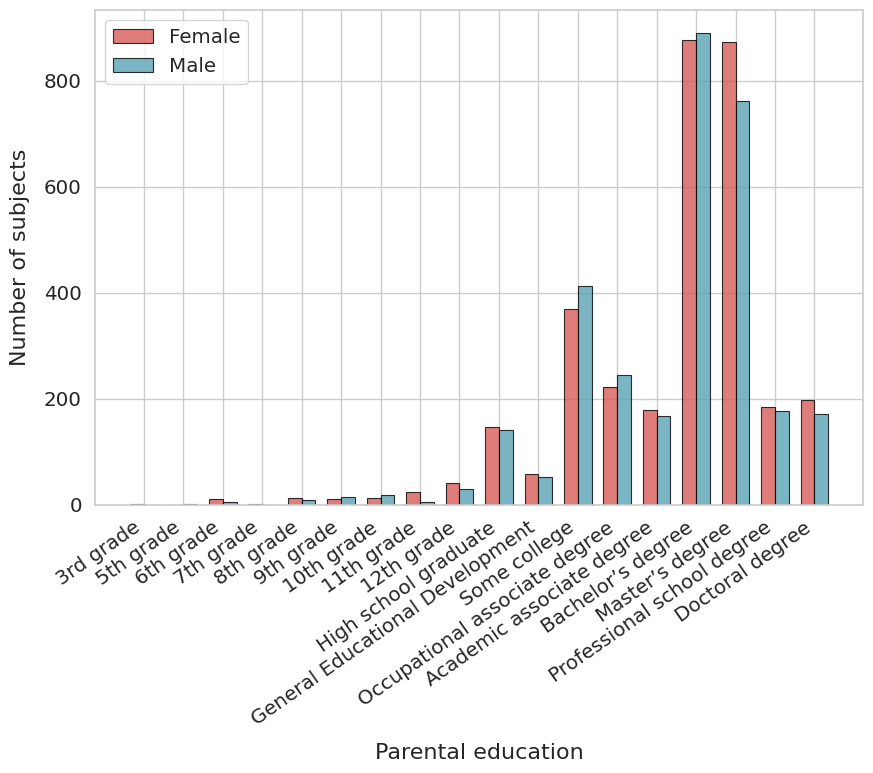

In [282]:
# --- Style setup (match manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

df = abcd_demo_all_clean.copy()

# --- Define full category order ---
edu_levels = sorted(df["edu_parent"].dropna().unique())
sex_levels = ["F", "M"]

# --- Count subjects, explicitly filling missing combinations with 0 ---
counts = (
    df
    .groupby(["edu_parent", "sex"])
    .size()
    .reindex(
        pd.MultiIndex.from_product(
            [edu_levels, sex_levels],
            names=["edu_parent", "sex"]
        ),
        fill_value=0
    )
    .reset_index(name="n")
)

# Map numeric codes to labels (only for those present)
counts["edu_parent_label"] = counts["edu_parent"].map(edu_parent_labels)


# --- Plot ---
x = np.arange(len(edu_levels))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(9, 8))

for i, sex in enumerate(sex_levels):
    sex_counts = counts[counts["sex"] == sex]

    ax.bar(
        x + (i - 0.5) * bar_width,
        sex_counts["n"].values,
        width=bar_width,
        color=sex_palette[sex],
        alpha=0.8,
        edgecolor="black",
        linewidth=0.8,
        label="Female" if sex == "F" else "Male"
    )

# --- Axis labels ---
ax.set_xticks(x)

# Use mapped labels, only for observed categories
xtick_labels = [
    edu_parent_labels.get(code, str(code)) for code in edu_levels
]
ax.set_xticklabels(xtick_labels, rotation=35, ha="right")

ax.set_xlabel("Parental education", fontsize=16, labelpad=10)
ax.set_ylabel("Number of subjects", fontsize=16, labelpad=10)

# --- Legend ---
ax.legend(frameon=True, loc="upper left")

plt.tight_layout()
plt.savefig(resdir_fig + "hist_edu_parent_by_sex.svg", format="svg", bbox_inches="tight", dpi=300)
# plt.show()


#### BMI z-score (relative to age and sex - with reference to the CDC 2000 Growth Charts)

In [63]:
print(f"Females: Mean: {np.mean(abcd_demo_all_clean.BMIz[abcd_demo_all_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_all_clean.BMIz[abcd_demo_all_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_all_clean.BMIz[abcd_demo_all_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_all_clean.BMIz[abcd_demo_all_clean.sex == 'M']):.2f}")

Females: Mean: 0.26, SD: 1.12
Males: Mean: 0.23, SD: 1.15


In [64]:
print(stats.levene(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].BMIz, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].BMIz, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].BMIz, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].BMIz, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

LeveneResult(statistic=2.3475911706051393, pvalue=0.12552691233014576)
FlignerResult(statistic=2.3980552138387985, pvalue=0.12148619653366982)


In [65]:
print(f"{stats.ttest_ind(abcd_demo_all_clean.BMIz[abcd_demo_all_clean.sex == 'F'], abcd_demo_all_clean.BMIz[abcd_demo_all_clean.sex == 'M'], nan_policy='omit')}")

TtestResult(statistic=1.0765021818933722, pvalue=0.2817438942614545, df=6308.0)


In [66]:
print(stats.mannwhitneyu(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].BMIz, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].BMIz, nan_policy='omit'))

MannwhitneyuResult(statistic=4907551.0, pvalue=0.34920391298448783)


Checking NaNs

In [67]:
abcd_demo_all_clean["BMIz"].isna().sum()

13

Plots

In [68]:
# Need to remove nans for plotting  fpr family conflict
abcd_demo_all_clean_omit_nan = abcd_demo_all_clean.dropna(subset=["BMIz"])
abcd_demo_baseline_clean_omit_nan = abcd_demo_baseline_clean.dropna(subset=["BMIz"])
abcd_demo_fu2y_clean_omit_nan = abcd_demo_fu2y_clean.dropna(subset=["BMIz"])
abcd_demo_fu4y_clean_omit_nan = abcd_demo_fu4y_clean.dropna(subset=["BMIz"])

/tmp/ipykernel_19527/284022671.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Females", "Males"])


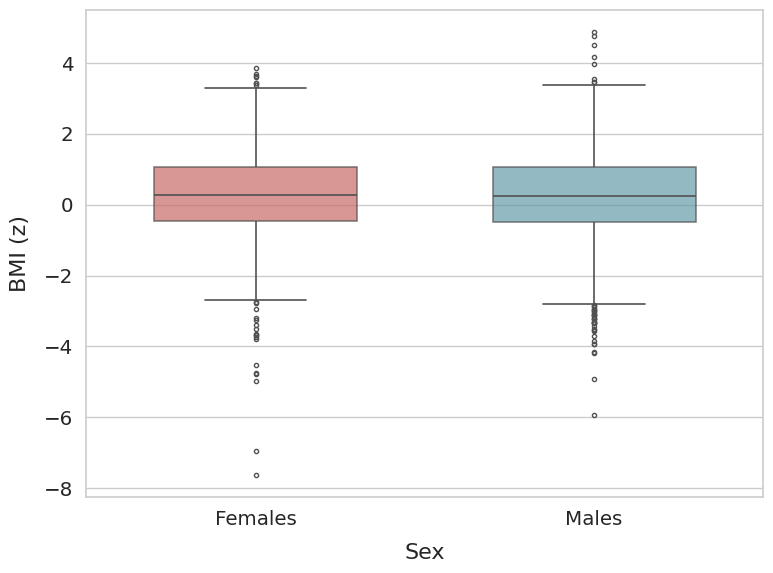

In [69]:
# Style setup
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
#sns.set_theme(style="white", font="DejaVu Sans", font_scale=1.3)

plt.rcParams["axes.linewidth"] = 1.2  # thicker axes for cleaner appearance
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create figure
plt.figure(figsize=(8, 6))

# Boxplot
ax = sns.boxplot(
    data=abcd_demo_all_clean_omit_nan,
    x="sex",
    y="BMIz",
    hue="sex",
    palette={"F": "#d85c59", "M": "#5aa3b5"},  # palette={'M': 'cadetblue', 'F': 'lightcoral'},
    dodge=False,
    width=0.6,
    linewidth=1.2,
    fliersize=3,
    boxprops={"alpha": 0.7},
)

#sns.despine(trim=True)

# Axis labels and title
ax.set_xlabel("Sex", fontsize=16, labelpad=10)
ax.set_ylabel("BMI (z)", fontsize=16, labelpad=10)
ax.set_xticklabels(["Females", "Males"])
#ax.set_title("Pubertal Scores by Sex", pad=15, weight="bold")

# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(resdir_fig+"boxplot_BMIz_by_sex.svg", format="svg", bbox_inches="tight", dpi=300)

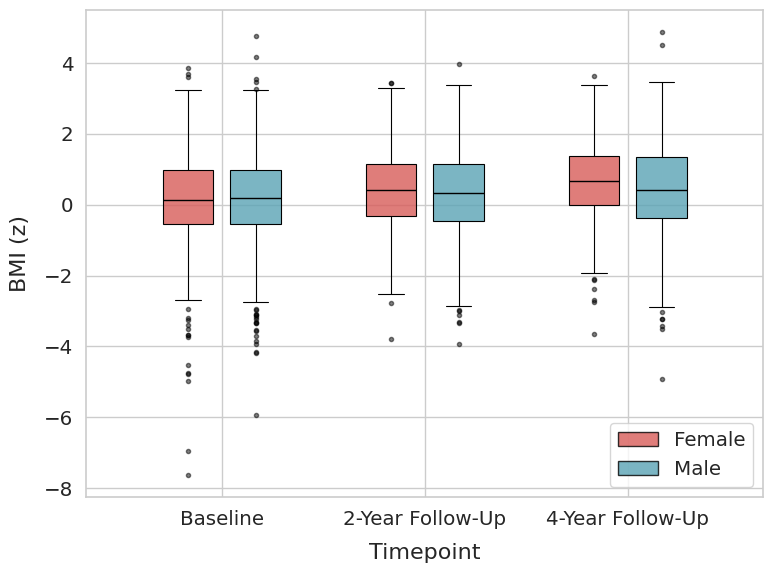

In [71]:
from matplotlib.patches import Patch
import matplotlib.colors as mcolors

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

alpha_map = {
    "Baseline": 0.8,  # 0.8
    "2-Year Follow-Up": 0.8,  # 0.8
    "4-Year Follow-Up": 0.8  # 0.8
}

sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

data = [
    abcd_demo_baseline_clean_omit_nan,
    abcd_demo_fu2y_clean_omit_nan,
    abcd_demo_fu4y_clean_omit_nan
]

# --- Style setup (consistent with your manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axes ---
fig, ax = plt.subplots(figsize=(8, 6))

# --- Function to draw SEX-SPLIT boxplots with TIMEPOINT alpha ---
def draw_boxplots(ax, data):

    box_width = 0.25
    offsets = [-box_width / 1.5, box_width / 1.5]  # F left, M right

    for tp_idx, tp in enumerate(timepoints):

        df_tp = data[tp_idx]
        alpha = alpha_map[tp]

        for sex_idx, sex in enumerate(["F", "M"]):

            df_sex = df_tp[df_tp["sex"] == sex]["BMIz"].dropna()

            color = sex_palette[sex]
            rgba = mcolors.to_rgba(color, alpha=alpha)

            position = tp_idx + offsets[sex_idx]

            bp = ax.boxplot(
                df_sex,
                positions=[position],
                widths=box_width,
                patch_artist=True,
                boxprops=dict(facecolor=rgba, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8),
                flierprops=dict(
                    marker='o',
                    markersize=3,
                    alpha=0.5,
                    markerfacecolor='black',
                    markeredgecolor='black'
                )
            )


# --- Draw boxplots ---
draw_boxplots(ax, data)

# --- Axis labels ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("BMI (z)", fontsize=16, labelpad=10)

# --- Legend (Sex only, alpha encoded visually) ---
legend_elements = [
    Patch(facecolor=sex_palette["F"], alpha=0.8, edgecolor="black", label="Female"),
    Patch(facecolor=sex_palette["M"], alpha=0.8, edgecolor="black", label="Male"),
]
ax.legend(handles=legend_elements, loc="lower right", frameon=True)




# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(
    resdir_fig + "boxplot_BMIz_by_sex_by_timepoint.svg",
    format="svg",
    bbox_inches="tight",
    dpi=300
)


#
#
#
#
# Compute gradients - Overall - BASELINE

## Mean gradients

In [172]:
mean_fc_matrix = np.sum(fc_matrices_baseline, axis=0)/len(fc_matrices_baseline)

In [173]:
mean_fc_matrix.shape

(400, 400)

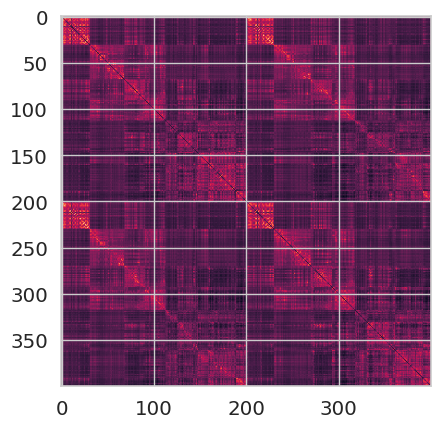

(400, 400)


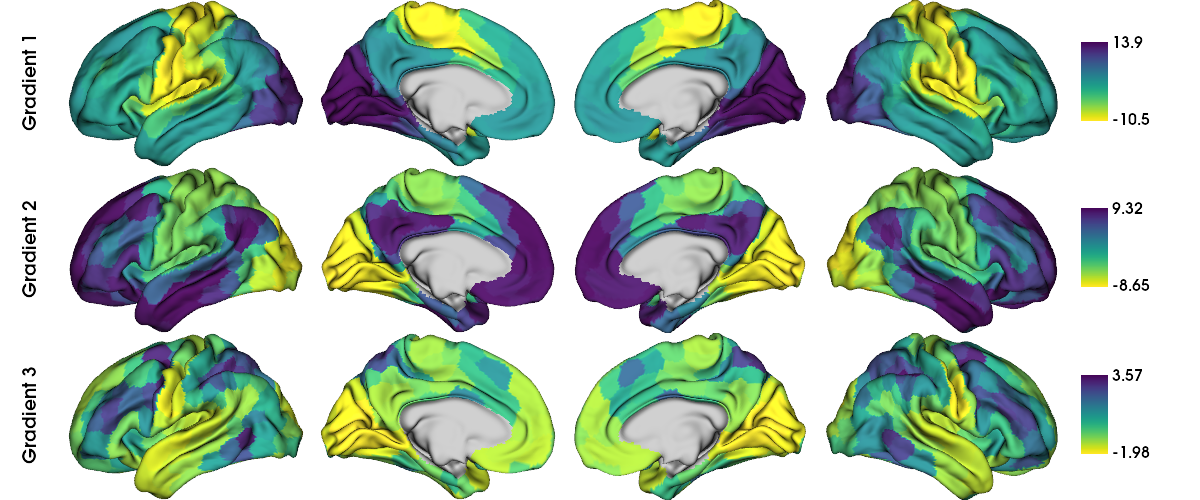

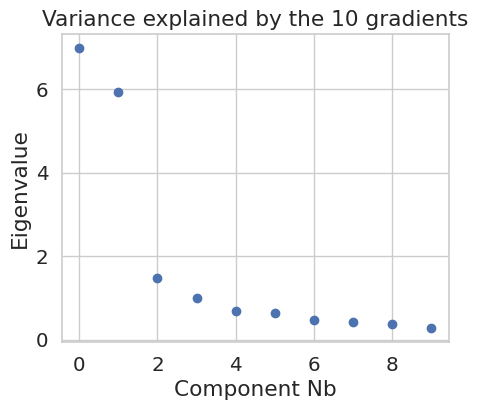

Total amount of variance explained by the 10 gradients (uncorrected sum lambdas): 18.27

G1: 38.22%
G2: 32.47%
G3: 8.05


In [176]:
# don't save these screenshots! (saves G1 and I actually want flipped -> next cells)
mean_fc_grad = compute_mean_gradients(mean_fc_matrix, display_output = True, data_reduction_algorithm = 'dm', kernel='cosine', save_screenshot = False, output_dir = resdir_fig, sample_modality = 'fc')

### RainCloudPlot
Using RainCloud plots https://github.com/RainCloudPlots/RainCloudPlots#python-environment

## Subject-level gradients (NOT ALIGNED)

In [177]:
# compute aligned gradients
compute_indvidual_gradients = compute_indvidual_gradients_NOT_aligned(conn_matrices = fc_matrices_baseline, ref_SA_axis = Margulies_gradients_schaefer400[0], data_reduction_algorithm = 'dm', kernel = 'cosine')

# store output of the gradient computation
array_SA_axis_baseline = compute_indvidual_gradients['array_SA_axis']
array_grad_other1_baseline = compute_indvidual_gradients['array_grad_other1']
array_grad_other2_baseline = compute_indvidual_gradients['array_grad_other2']
list_SA_axis_grad_num_baseline = compute_indvidual_gradients['list_SA_axis_grad_num']
list_SA_axis_corr_to_ref_baseline = compute_indvidual_gradients['list_SA_axis_corr_to_ref']
scaled_var_exp_SA_axis_baseline = compute_indvidual_gradients['scaled_var_exp_SA_axis']
scaled_var_exp_other1_baseline = compute_indvidual_gradients['scaled_var_exp_other1']
scaled_var_exp_other2_baseline = compute_indvidual_gradients['scaled_var_exp_other2']
diff_scaled_var_exp_SA_axis_other1_baseline = compute_indvidual_gradients['diff_scaled_var_exp_SA_axis_other1']


/data/u_serio_software/miniforge3/lib/python3.12/site-packages/brainspace/gradient/embedding.py:77: UserWarning: Graph is not fully connected.
  warnings.warn('Graph is not fully connected.')


In [178]:
array_SA_axis_baseline.shape

(4007, 400)

In [179]:
Counter(list_SA_axis_grad_num_baseline)

Counter({1: 2079, 2: 1857, 3: 57, 4: 8, 5: 6})

/tmp/ipykernel_1454/1113933288.py:22: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, 5000)


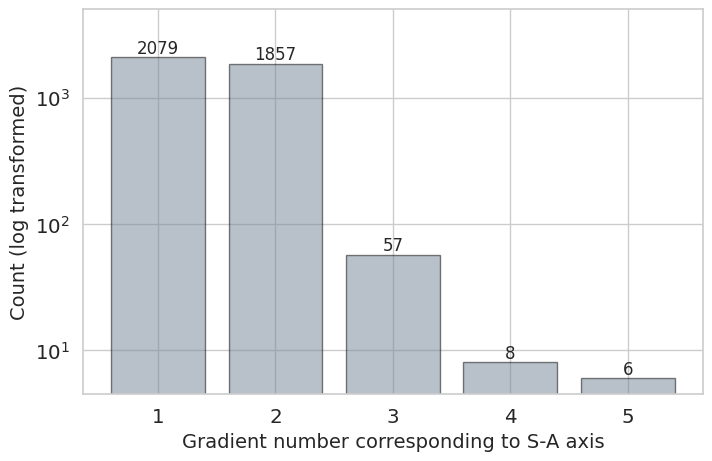

In [180]:
counts = Counter(list_SA_axis_grad_num_baseline)

# Sort by key to keep the x-axis in order
keys = sorted(counts.keys())
values = [counts[k] for k in keys]

# Style setup (match your other figures)
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create the bar plot
plt.figure(figsize=(8, 5))

bars = plt.bar(keys, values, color='xkcd:steel', alpha=0.5, edgecolor='black')

plt.xlabel('Gradient number corresponding to S-A axis', fontsize=14)
plt.ylabel('Count (log transformed)', fontsize=14)
#plt.title('Counts of Axis Gradient Numbers at Baseline', fontsize=16)
plt.xticks(keys)
plt.yscale('log')  # log scale
plt.ylim(0, 5000)

# Annotate counts on top of the bars
for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,  # x position: center of the bar
        value,                               # y position: top of the bar
        str(value),                          # text to display
        ha='center', va='bottom', fontsize=12
    )

plt.show()


In [181]:
# Compute the loading range for the S-A axis at individual level
SA_axis_baseline_individual_range = np.max(array_SA_axis_baseline, axis=1) - np.min(array_SA_axis_baseline, axis=1) 

In [182]:
print(f"Min correlation: r = {round(np.min(list_SA_axis_corr_to_ref_baseline),2)}")
print(f"Max correlation: r = {round(np.max(list_SA_axis_corr_to_ref_baseline),2)}")
print(f"Mean correlation: r = {round(np.mean(list_SA_axis_corr_to_ref_baseline),2)}")
print(f"Median correlation: r = {round(np.median(list_SA_axis_corr_to_ref_baseline),2)}")
print(f"Mean individual range: r = {round(np.mean(SA_axis_baseline_individual_range),2)}")

Min correlation: r = 0.37
Max correlation: r = 0.94
Mean correlation: r = 0.75
Median correlation: r = 0.75
Mean individual range: r = 14.56


In [183]:
data = list_SA_axis_corr_to_ref_baseline
# Coefficient of variation
print("CV = std / mean. Scale-free measure of relative dispersion")
print(np.std(data, ddof=1) / np.mean(data))

# Interquartile range
print("\nIQR = Q3 - Q1. Middle 50% spread, robust to outliers")
print(np.percentile(data, 75) - np.percentile(data, 25))

# Median absolute deviation
print("\nMAD = median(|xi - median(x)|). Robust, outlier-resistant spread")
print(np.median(np.abs(data - np.median(data))))

# Normalized range
print("\nNR = (max - min) / mean. Simple but sensitive to outliers")
print((np.max(data) - np.min(data)) / np.mean(data))

# Gini coefficient
print("\nGini coefficient. 0 = perfect equality, 1 = maximal inequality")
sorted_data = np.sort(data)
n = len(sorted_data)
index = np.arange(1, n + 1)
print((2 * np.sum(index * sorted_data) / (n * np.sum(sorted_data))) - (n + 1) / n)

CV = std / mean. Scale-free measure of relative dispersion
0.12334549996875623

IQR = Q3 - Q1. Middle 50% spread, robust to outliers
0.13336733354583463

MAD = median(|xi - median(x)|). Robust, outlier-resistant spread
0.06630678941743384

NR = (max - min) / mean. Simple but sensitive to outliers
0.7681556541840644

Gini coefficient. 0 = perfect equality, 1 = maximal inequality
0.07006423697026931


In [184]:
print(f"Min scaled variance explained by S-A axis: {round(np.min(scaled_var_exp_SA_axis_baseline),2)}")
print(f"Max scaled variance explained by S-A axis: {round(np.max(scaled_var_exp_SA_axis_baseline),2)}")
print("")
print(f"Min difference variance explained by S-A axis and other gradient 1: {round(np.min(diff_scaled_var_exp_SA_axis_other1_baseline),2)}")
print(f"Max difference variance explained by S-A axis and other gradient 1: {round(np.max(diff_scaled_var_exp_SA_axis_other1_baseline),2)}")

Min scaled variance explained by S-A axis: 0.43
Max scaled variance explained by S-A axis: 57.58

Min difference variance explained by S-A axis and other gradient 1: -95.31
Max difference variance explained by S-A axis and other gradient 1: 50.8


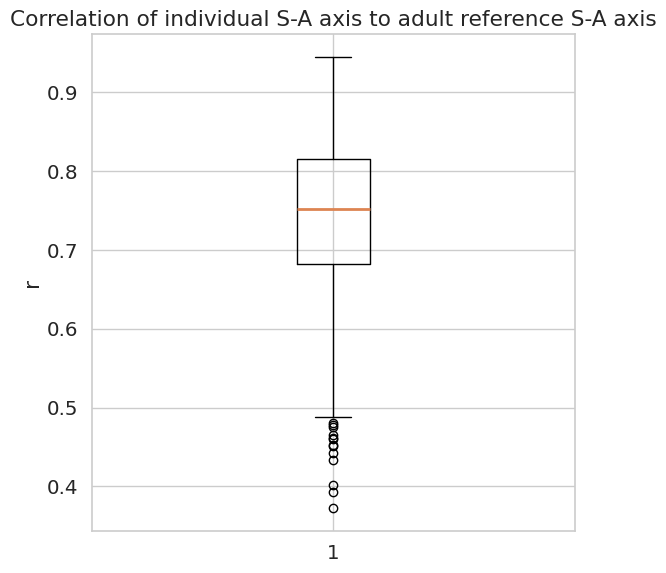

In [185]:
plt.figure(figsize=(6, 6))
plt.boxplot(list_SA_axis_corr_to_ref_baseline)
plt.ylabel('r')
plt.title('Correlation of individual S-A axis to adult reference S-A axis')
plt.tight_layout()
plt.show()

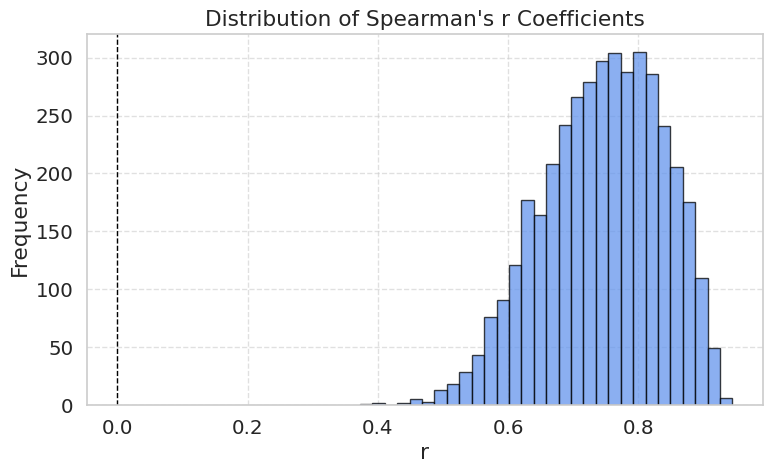

In [186]:
# Plot histogram
plt.figure(figsize=(8, 5))
plt.hist(list_SA_axis_corr_to_ref_baseline, bins=30, color='cornflowerblue', edgecolor='black', alpha=0.75)
plt.title("Distribution of Spearman's r Coefficients")
plt.xlabel("r")
plt.ylabel("Frequency")
plt.axvline(0, color='black', linestyle='--', linewidth=1)  # reference line at r = 0
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

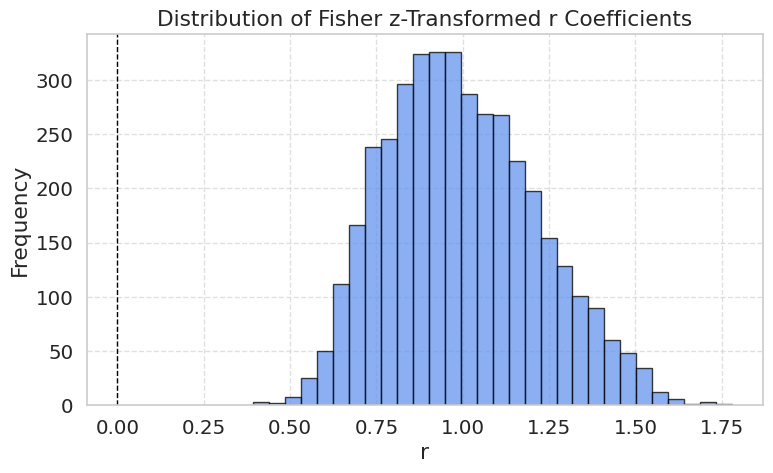

In [187]:
# Apply Fisher r-to-z transformation <- ALTHOUGH FOR ANALYSES NEED TO APPLY TRANSFORMATION ON CONCATENATED SAMPLE AT 3 TIMEPOINTS! (DOING THIS IN R)
list_SA_axis_corr_to_ref_baseline_z = 0.5 * np.log((1 + np.array(list_SA_axis_corr_to_ref_baseline)) / (1 - np.array(list_SA_axis_corr_to_ref_baseline)))

# Plot histogram of transformed z values
# Plot histogram
plt.figure(figsize=(8, 5))
plt.hist(list_SA_axis_corr_to_ref_baseline_z, bins=30, color='cornflowerblue', edgecolor='black', alpha=0.75)
plt.title("Distribution of Fisher z-Transformed r Coefficients")
plt.xlabel("r")
plt.ylabel("Frequency")
plt.axvline(0, color='black', linestyle='--', linewidth=1)  # reference line at r = 0
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [188]:
# export S-A axis individual gradients as matfile
mdict = {'array_SA_axis_baseline': array_SA_axis_baseline, 'sub_ID_baseline': sub_ID_baseline, 
         'list_SA_axis_grad_num_baseline': list_SA_axis_grad_num_baseline, 
         'list_SA_axis_corr_to_ref_baseline': list_SA_axis_corr_to_ref_baseline, 'list_SA_axis_corr_to_ref_baseline_z': list_SA_axis_corr_to_ref_baseline_z,
         'SA_axis_baseline_individual_range': SA_axis_baseline_individual_range
        }

scipy.io.savemat(datadir_local_pds_cleaned+'array_SA_axis_NOT_aligned_baseline.mat', mdict)

#
#
#
#
# Compute gradients - Overall - 2yfu

## Mean gradients

In [189]:
mean_fc_matrix_fu2y = np.sum(fc_matrices_fu2y, axis=0)/len(fc_matrices_fu2y)

In [190]:
mean_fc_matrix_fu2y.shape

(400, 400)

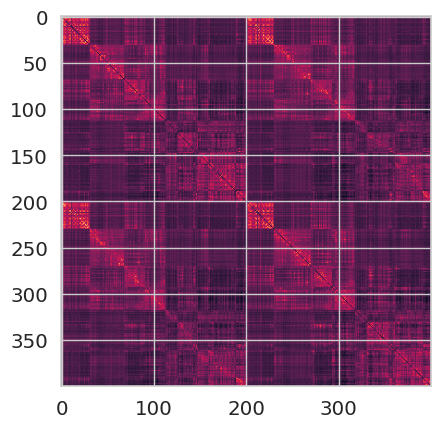

(400, 400)


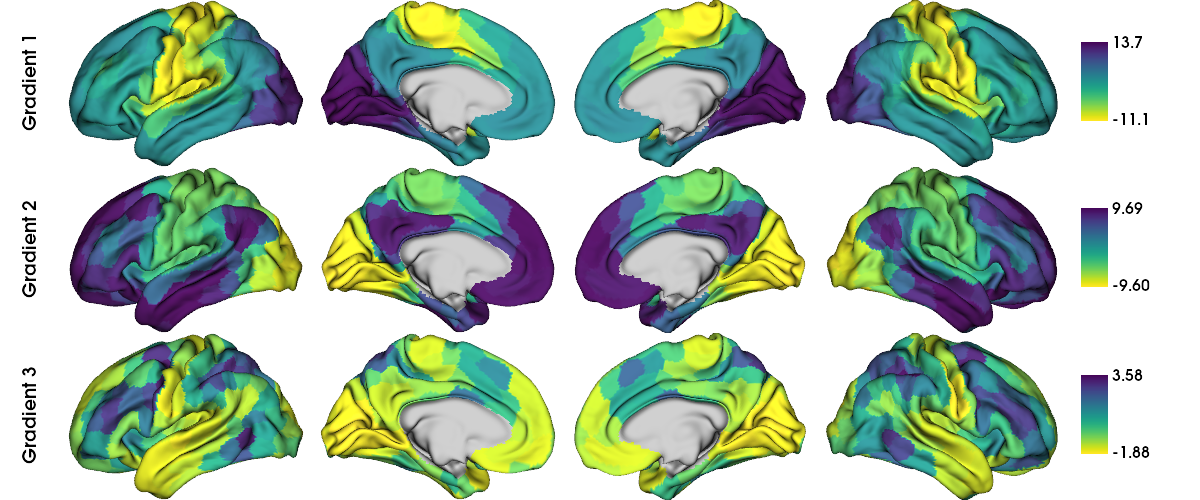

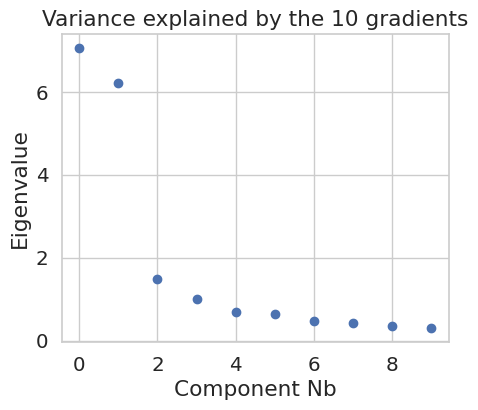

Total amount of variance explained by the 10 gradients (uncorrected sum lambdas): 18.68

G1: 37.78%
G2: 33.34%
G3: 7.95


In [191]:
# don't save these screenshots! (saves G1 and I actually want flipped -> next cells)
mean_fc_grad_fu2y = compute_mean_gradients(mean_fc_matrix_fu2y, display_output = True, data_reduction_algorithm = 'dm', kernel = 'cosine', save_screenshot = False, output_dir = resdir_fig, sample_modality = 'fc')

In [192]:
# I am creating a new variable with gradients that are flipped because I want G2 to go from sensory (-) to association (+) and I want to align individual level gradients to this
mean_fc_grad_flipped_fu2y = - mean_fc_grad_fu2y.gradients_

### RainCloudPlot
Using RainCloud plots https://github.com/RainCloudPlots/RainCloudPlots#python-environment

## Subject-level gradients (NOT ALIGNED)

In [193]:
# compute aligned gradients
compute_indvidual_gradients_fu2y = compute_indvidual_gradients_NOT_aligned(conn_matrices = fc_matrices_fu2y, ref_SA_axis = Margulies_gradients_schaefer400[0], data_reduction_algorithm = 'dm', kernel = 'cosine')

# store output of the gradient computation
array_SA_axis_fu2y = compute_indvidual_gradients_fu2y['array_SA_axis']
array_grad_other1_fu2y = compute_indvidual_gradients_fu2y['array_grad_other1']
array_grad_other2_fu2y = compute_indvidual_gradients_fu2y['array_grad_other2']
list_SA_axis_grad_num_fu2y = compute_indvidual_gradients_fu2y['list_SA_axis_grad_num']
list_SA_axis_corr_to_ref_fu2y = compute_indvidual_gradients_fu2y['list_SA_axis_corr_to_ref']
scaled_var_exp_SA_axis_fu2y = compute_indvidual_gradients_fu2y['scaled_var_exp_SA_axis']
scaled_var_exp_other1_fu2y = compute_indvidual_gradients_fu2y['scaled_var_exp_other1']
scaled_var_exp_other2_fu2y = compute_indvidual_gradients_fu2y['scaled_var_exp_other2']
diff_scaled_var_exp_SA_axis_other1_fu2y = compute_indvidual_gradients_fu2y['diff_scaled_var_exp_SA_axis_other1']


/data/u_serio_software/miniforge3/lib/python3.12/site-packages/brainspace/gradient/embedding.py:77: UserWarning: Graph is not fully connected.
  warnings.warn('Graph is not fully connected.')


In [194]:
array_SA_axis_fu2y.shape

(1235, 400)

In [195]:
Counter(list_SA_axis_grad_num_fu2y)

Counter({1: 720, 2: 493, 3: 20, 4: 2})

/tmp/ipykernel_1454/797398177.py:22: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, 5000)


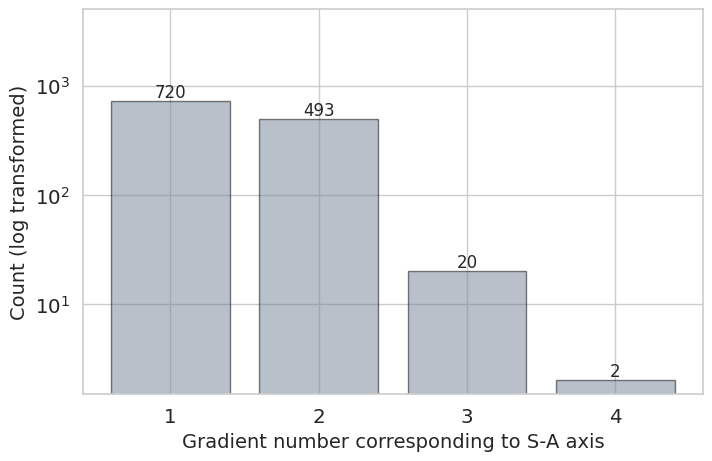

In [196]:
counts = Counter(list_SA_axis_grad_num_fu2y)

# Sort by key to keep the x-axis in order
keys = sorted(counts.keys())
values = [counts[k] for k in keys]

# Style setup (match your other figures)
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create the bar plot
plt.figure(figsize=(8, 5))

bars = plt.bar(keys, values, color='xkcd:steel', alpha=0.5, edgecolor='black')

plt.xlabel('Gradient number corresponding to S-A axis', fontsize=14)
plt.ylabel('Count (log transformed)', fontsize=14)
#plt.title('Counts of Axis Gradient Numbers at Baseline', fontsize=16)
plt.xticks(keys)
plt.yscale('log')  # log scale
plt.ylim(0, 5000)

# Annotate counts on top of the bars
for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,  # x position: center of the bar
        value,                               # y position: top of the bar
        str(value),                          # text to display
        ha='center', va='bottom', fontsize=12
    )

plt.show()


In [197]:
# Compute the loading range for the S-A axis at individual level
SA_axis_fu2y_individual_range = np.max(array_SA_axis_fu2y, axis=1) - np.min(array_SA_axis_fu2y, axis=1)

In [198]:
print(f"Min correlation: r = {round(np.min(list_SA_axis_corr_to_ref_fu2y),2)}")
print(f"Max correlation: r = {round(np.max(list_SA_axis_corr_to_ref_fu2y),2)}")
print(f"Mean correlation: r = {round(np.mean(list_SA_axis_corr_to_ref_fu2y),2)}")
print(f"Median correlation: r = {round(np.median(list_SA_axis_corr_to_ref_fu2y),2)}")
print(f"STD correlation: r = {round(np.std(list_SA_axis_corr_to_ref_fu2y),10)}")
print(f"Mean individual range: r = {round(np.mean(SA_axis_fu2y_individual_range),2)}")

Min correlation: r = 0.44
Max correlation: r = 0.95
Mean correlation: r = 0.76
Median correlation: r = 0.77
STD correlation: r = 0.0920225541
Mean individual range: r = 15.24


In [199]:
data = list_SA_axis_corr_to_ref_fu2y
# Coefficient of variation
print("CV = std / mean. Scale-free measure of relative dispersion")
print(np.std(data, ddof=1) / np.mean(data))

# Interquartile range
print("\nIQR = Q3 - Q1. Middle 50% spread, robust to outliers")
print(np.percentile(data, 75) - np.percentile(data, 25))

# Median absolute deviation
print("\nMAD = median(|xi - median(x)|). Robust, outlier-resistant spread")
print(np.median(np.abs(data - np.median(data))))

# Normalized range
print("\nNR = (max - min) / mean. Simple but sensitive to outliers")
print((np.max(data) - np.min(data)) / np.mean(data))

# Gini coefficient
print("\nGini coefficient. 0 = perfect equality, 1 = maximal inequality")
sorted_data = np.sort(data)
n = len(sorted_data)
index = np.arange(1, n + 1)
print((2 * np.sum(index * sorted_data) / (n * np.sum(sorted_data))) - (n + 1) / n)

CV = std / mean. Scale-free measure of relative dispersion
0.1206233023648739

IQR = Q3 - Q1. Middle 50% spread, robust to outliers
0.1341104944405902

MAD = median(|xi - median(x)|). Robust, outlier-resistant spread
0.06724598278739247

NR = (max - min) / mean. Simple but sensitive to outliers
0.6691426449325801

Gini coefficient. 0 = perfect equality, 1 = maximal inequality
0.06840316818469594


In [200]:
print(f"Min scaled variance explained by S-A axis: {round(np.min(scaled_var_exp_SA_axis_fu2y),2)}")
print(f"Max scaled variance explained by S-A axis: {round(np.max(scaled_var_exp_SA_axis_fu2y),2)}")
print("")
print(f"Min difference variance explained by S-A axis and other gradient 1: {round(np.min(diff_scaled_var_exp_SA_axis_other1_fu2y),2)}")
print(f"Max difference variance explained by S-A axis and other gradient 1: {round(np.max(diff_scaled_var_exp_SA_axis_other1_fu2y),2)}")

Min scaled variance explained by S-A axis: 0.11
Max scaled variance explained by S-A axis: 58.36

Min difference variance explained by S-A axis and other gradient 1: -91.26
Max difference variance explained by S-A axis and other gradient 1: 55.68


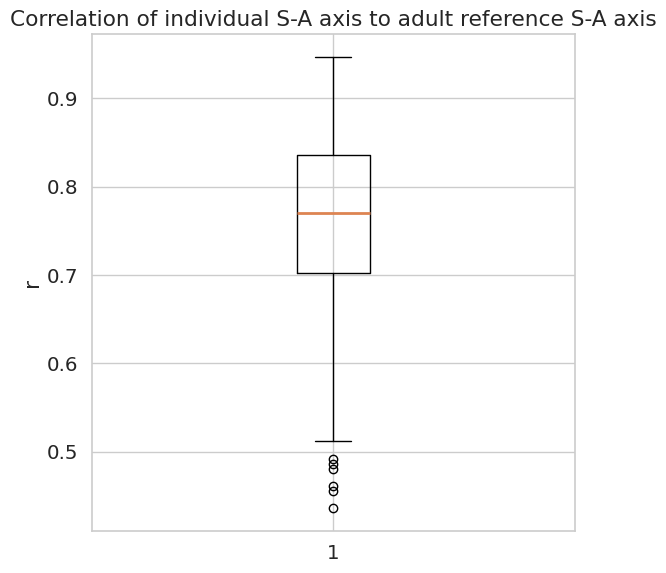

In [201]:
plt.figure(figsize=(6, 6))
plt.boxplot(list_SA_axis_corr_to_ref_fu2y)
plt.ylabel('r')
plt.title('Correlation of individual S-A axis to adult reference S-A axis')
plt.tight_layout()
plt.show()

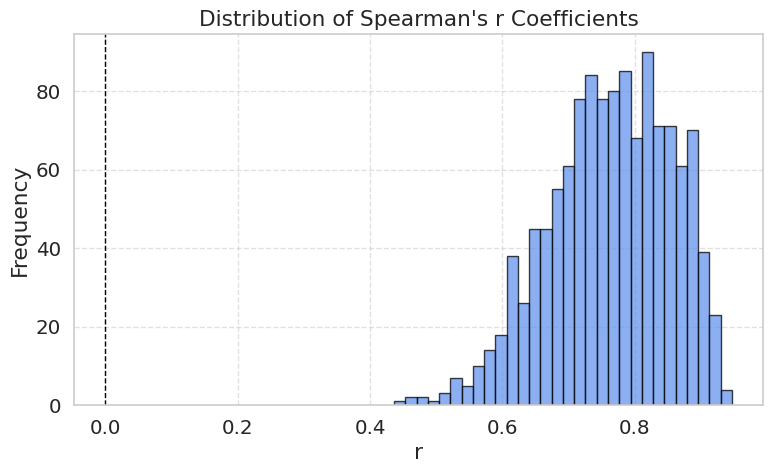

In [202]:
# Plot histogram
plt.figure(figsize=(8, 5))
plt.hist(list_SA_axis_corr_to_ref_fu2y, bins=30, color='cornflowerblue', edgecolor='black', alpha=0.75)
plt.title("Distribution of Spearman's r Coefficients")
plt.xlabel("r")
plt.ylabel("Frequency")
plt.axvline(0, color='black', linestyle='--', linewidth=1)  # reference line at r = 0
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

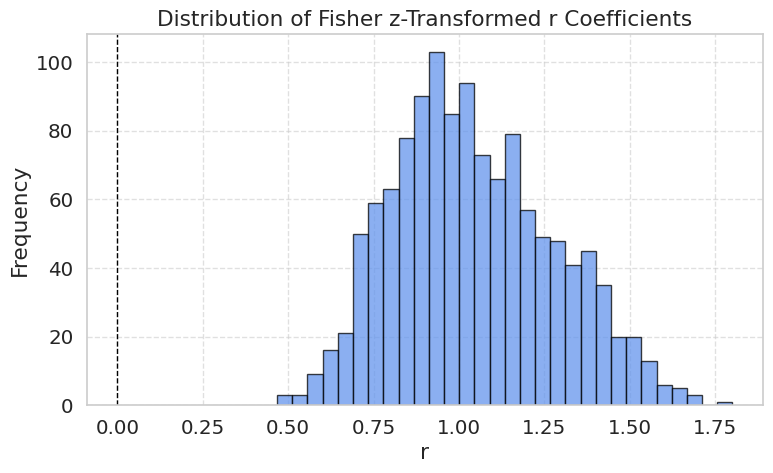

In [203]:
# Apply Fisher r-to-z transformation <- ALTHOUGH FOR ANALYSES NEED TO APPLY TRANSFORMATION ON CONCATENATED SAMPLE AT 3 TIMEPOINTS! (DOING THIS IN R)
list_SA_axis_corr_to_ref_fu2y_z = 0.5 * np.log((1 + np.array(list_SA_axis_corr_to_ref_fu2y)) / (1 - np.array(list_SA_axis_corr_to_ref_fu2y)))

# Plot histogram of transformed z values
# Plot histogram
plt.figure(figsize=(8, 5))
plt.hist(list_SA_axis_corr_to_ref_fu2y_z, bins=30, color='cornflowerblue', edgecolor='black', alpha=0.75)
plt.title("Distribution of Fisher z-Transformed r Coefficients")
plt.xlabel("r")
plt.ylabel("Frequency")
plt.axvline(0, color='black', linestyle='--', linewidth=1)  # reference line at r = 0
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [204]:
# export individual S-A axis 
mdict = {'array_SA_axis_fu2y': array_SA_axis_fu2y, 'sub_ID_fu2y': sub_ID_fu2y, 
         'list_SA_axis_grad_num_fu2y': list_SA_axis_grad_num_fu2y, 
         'list_SA_axis_corr_to_ref_fu2y': list_SA_axis_corr_to_ref_fu2y,  'list_SA_axis_corr_to_ref_fu2y_z': list_SA_axis_corr_to_ref_fu2y_z,
         'SA_axis_fu2y_individual_range': SA_axis_fu2y_individual_range
        }

scipy.io.savemat(datadir_local_pds_cleaned+'array_SA_axis_NOT_aligned_fu2y.mat', mdict)

#
#
#
#
# Compute gradients - Overall - 4yfu

## Mean gradients

In [205]:
mean_fc_matrix_fu4y = np.sum(fc_matrices_fu4y, axis=0)/len(fc_matrices_fu4y)

In [206]:
mean_fc_matrix_fu4y.shape

(400, 400)

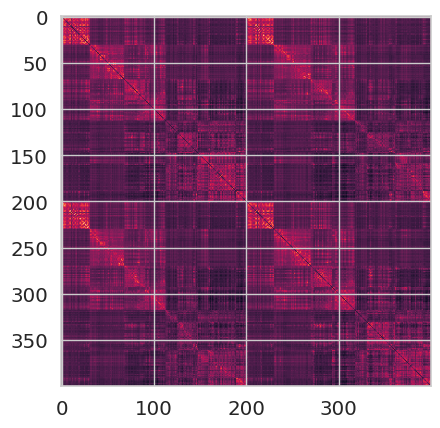

(400, 400)


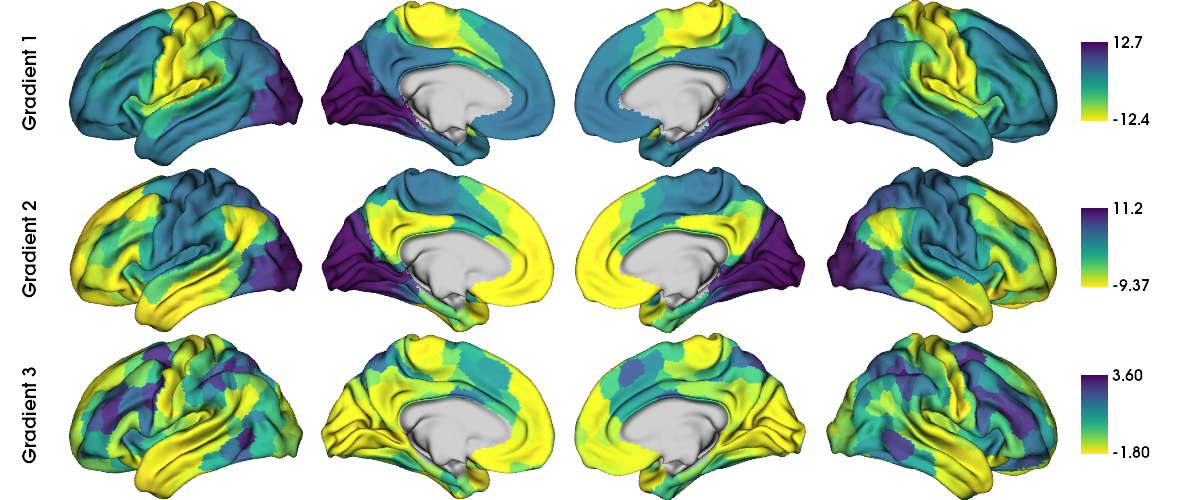

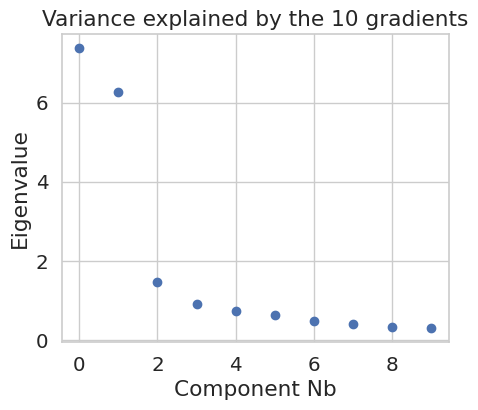

Total amount of variance explained by the 10 gradients (uncorrected sum lambdas): 18.96

G1: 38.87%
G2: 33.04%
G3: 7.82


In [207]:
# don't save these screenshots! (saves G1 and I actually want flipped -> next cells)
mean_fc_grad_fu4y = compute_mean_gradients(mean_fc_matrix_fu4y, display_output = True, data_reduction_algorithm = 'dm', kernel = 'cosine', save_screenshot = False, output_dir = resdir_fig, sample_modality = 'fc')

In [208]:
# I am creating a new variable with gradients that are flipped because I want G2 to go from sensory (-) to association (+) and I want to align individual level gradients to this
mean_fc_grad_flipped_fu4y = - mean_fc_grad_fu4y.gradients_

### RainCloudPlot
Using RainCloud plots https://github.com/RainCloudPlots/RainCloudPlots#python-environment

## Subject-level gradients (NOT ALIGNED)

In [209]:
# compute aligned gradients
compute_indvidual_gradients_fu4y = compute_indvidual_gradients_NOT_aligned(conn_matrices = fc_matrices_fu4y, ref_SA_axis = Margulies_gradients_schaefer400[0], data_reduction_algorithm = 'dm', kernel = 'cosine')

# store output of the gradient computation
array_SA_axis_fu4y = compute_indvidual_gradients_fu4y['array_SA_axis']
array_grad_other1_fu4y = compute_indvidual_gradients_fu4y['array_grad_other1']
array_grad_other2_fu4y = compute_indvidual_gradients_fu4y['array_grad_other2']
list_SA_axis_grad_num_fu4y = compute_indvidual_gradients_fu4y['list_SA_axis_grad_num']
list_SA_axis_corr_to_ref_fu4y = compute_indvidual_gradients_fu4y['list_SA_axis_corr_to_ref']
scaled_var_exp_SA_axis_fu4y = compute_indvidual_gradients_fu4y['scaled_var_exp_SA_axis']
scaled_var_exp_other1_fu4y = compute_indvidual_gradients_fu4y['scaled_var_exp_other1']
scaled_var_exp_other2_fu4y = compute_indvidual_gradients_fu4y['scaled_var_exp_other2']
diff_scaled_var_exp_SA_axis_other1_fu4y = compute_indvidual_gradients_fu4y['diff_scaled_var_exp_SA_axis_other1']


/data/u_serio_software/miniforge3/lib/python3.12/site-packages/brainspace/gradient/embedding.py:77: UserWarning: Graph is not fully connected.
  warnings.warn('Graph is not fully connected.')


In [210]:
array_SA_axis_fu4y.shape

(929, 400)

In [211]:
Counter(list_SA_axis_grad_num_fu4y)

Counter({1: 614, 2: 307, 3: 8})

/tmp/ipykernel_1454/4178445155.py:22: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, 5000)


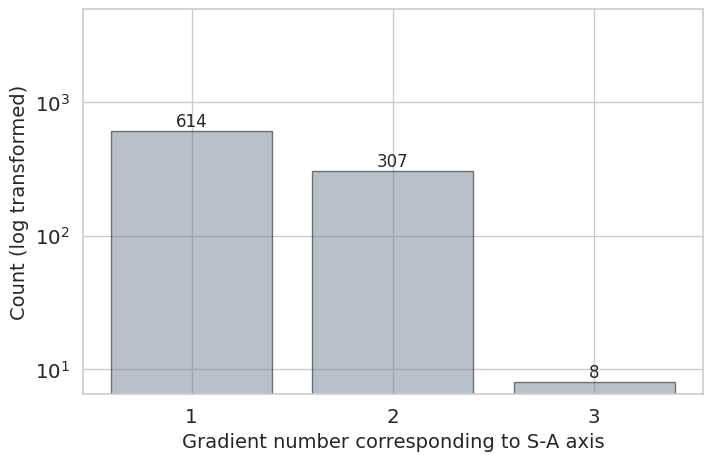

In [212]:
counts = Counter(list_SA_axis_grad_num_fu4y)

# Sort by key to keep the x-axis in order
keys = sorted(counts.keys())
values = [counts[k] for k in keys]

# Style setup (match your other figures)
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create the bar plot
plt.figure(figsize=(8, 5))

bars = plt.bar(keys, values, color='xkcd:steel', alpha=0.5, edgecolor='black')

plt.xlabel('Gradient number corresponding to S-A axis', fontsize=14)
plt.ylabel('Count (log transformed)', fontsize=14)
#plt.title('Counts of Axis Gradient Numbers at Baseline', fontsize=16)
plt.xticks(keys)
plt.yscale('log')  # log scale
plt.ylim(0, 5000)

# Annotate counts on top of the bars
for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,  # x position: center of the bar
        value,                               # y position: top of the bar
        str(value),                          # text to display
        ha='center', va='bottom', fontsize=12
    )

plt.show()


In [213]:
# Compute the loading range for the S-A axis at individual level
SA_axis_fu4y_individual_range = np.max(array_SA_axis_fu4y, axis=1) - np.min(array_SA_axis_fu4y, axis=1)

In [214]:
print(f"Min correlation: r = {round(np.min(list_SA_axis_corr_to_ref_fu4y),2)}")
print(f"Max correlation: r = {round(np.max(list_SA_axis_corr_to_ref_fu4y),2)}")
print(f"Mean correlation: r = {round(np.mean(list_SA_axis_corr_to_ref_fu4y),2)}")
print(f"Median correlation: r = {round(np.median(list_SA_axis_corr_to_ref_fu4y),2)}")
print(f"STD correlation: r = {round(np.std(list_SA_axis_corr_to_ref_fu4y),10)}")
print(f"Mean individual range: r = {round(np.mean(SA_axis_fu4y_individual_range),2)}")

Min correlation: r = 0.51
Max correlation: r = 0.94
Mean correlation: r = 0.78
Median correlation: r = 0.79
STD correlation: r = 0.0898829225
Mean individual range: r = 16.03


In [215]:
data = list_SA_axis_corr_to_ref_fu4y
# Coefficient of variation
print("CV = std / mean. Scale-free measure of relative dispersion")
print(np.std(data, ddof=1) / np.mean(data))

# Interquartile range
print("\nIQR = Q3 - Q1. Middle 50% spread, robust to outliers")
print(np.percentile(data, 75) - np.percentile(data, 25))

# Median absolute deviation
print("\nMAD = median(|xi - median(x)|). Robust, outlier-resistant spread")
print(np.median(np.abs(data - np.median(data))))

# Normalized range
print("\nNR = (max - min) / mean. Simple but sensitive to outliers")
print((np.max(data) - np.min(data)) / np.mean(data))

# Gini coefficient
print("\nGini coefficient. 0 = perfect equality, 1 = maximal inequality")
sorted_data = np.sort(data)
n = len(sorted_data)
index = np.arange(1, n + 1)
print((2 * np.sum(index * sorted_data) / (n * np.sum(sorted_data))) - (n + 1) / n)

CV = std / mean. Scale-free measure of relative dispersion
0.114815564770627

IQR = Q3 - Q1. Middle 50% spread, robust to outliers
0.1359910374439841

MAD = median(|xi - median(x)|). Robust, outlier-resistant spread
0.0684484278026738

NR = (max - min) / mean. Simple but sensitive to outliers
0.554930273966552

Gini coefficient. 0 = perfect equality, 1 = maximal inequality
0.06509242869761311


In [216]:
print(f"Min scaled variance explained by S-A axis: {round(np.min(scaled_var_exp_SA_axis_fu4y),2)}")
print(f"Max scaled variance explained by S-A axis: {round(np.max(scaled_var_exp_SA_axis_fu4y),2)}")
print("")
print(f"Min difference variance explained by S-A axis and other gradient 1: {round(np.min(diff_scaled_var_exp_SA_axis_other1_fu4y),2)}")
print(f"Max difference variance explained by S-A axis and other gradient 1: {round(np.max(diff_scaled_var_exp_SA_axis_other1_fu4y),2)}")

Min scaled variance explained by S-A axis: 0.43
Max scaled variance explained by S-A axis: 56.16

Min difference variance explained by S-A axis and other gradient 1: -97.87
Max difference variance explained by S-A axis and other gradient 1: 50.27


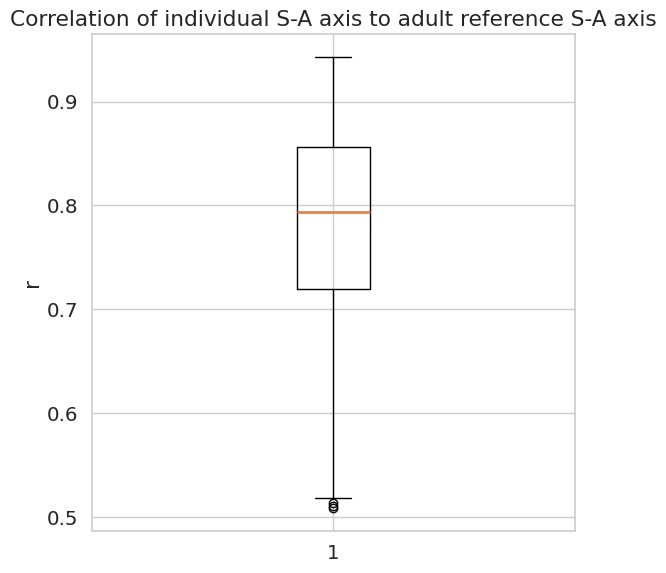

In [217]:
plt.figure(figsize=(6, 6))
plt.boxplot(list_SA_axis_corr_to_ref_fu4y)
plt.ylabel('r')
plt.title('Correlation of individual S-A axis to adult reference S-A axis')
plt.tight_layout()
plt.show()

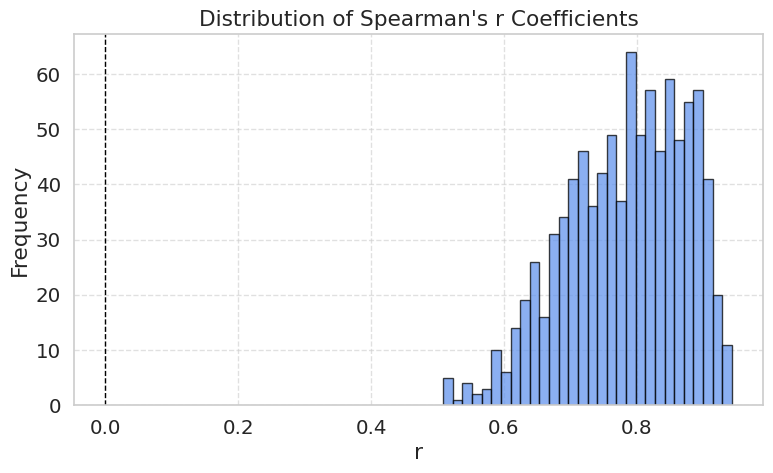

In [218]:
# Plot histogram
plt.figure(figsize=(8, 5))
plt.hist(list_SA_axis_corr_to_ref_fu4y, bins=30, color='cornflowerblue', edgecolor='black', alpha=0.75)
plt.title("Distribution of Spearman's r Coefficients")
plt.xlabel("r")
plt.ylabel("Frequency")
plt.axvline(0, color='black', linestyle='--', linewidth=1)  # reference line at r = 0
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

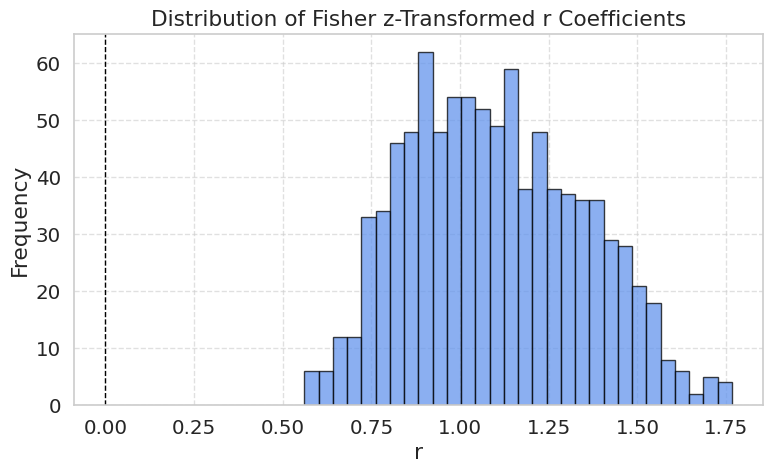

In [219]:
# Apply Fisher r-to-z transformation <- ALTHOUGH FOR ANALYSES NEED TO APPLY TRANSFORMATION ON CONCATENATED SAMPLE AT 3 TIMEPOINTS! (DOING THIS IN R)
list_SA_axis_corr_to_ref_fu4y_z = 0.5 * np.log((1 + np.array(list_SA_axis_corr_to_ref_fu4y)) / (1 - np.array(list_SA_axis_corr_to_ref_fu4y)))

# Plot histogram of transformed z values
# Plot histogram
plt.figure(figsize=(8, 5))
plt.hist(list_SA_axis_corr_to_ref_fu4y_z, bins=30, color='cornflowerblue', edgecolor='black', alpha=0.75)
plt.title("Distribution of Fisher z-Transformed r Coefficients")
plt.xlabel("r")
plt.ylabel("Frequency")
plt.axvline(0, color='black', linestyle='--', linewidth=1)  # reference line at r = 0
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [220]:
# export individual S-A axis 
mdict = {'array_SA_axis_fu4y': array_SA_axis_fu4y, 'sub_ID_fu4y': sub_ID_fu4y, 
         'list_SA_axis_grad_num_fu4y': list_SA_axis_grad_num_fu4y, 
         'list_SA_axis_corr_to_ref_fu4y': list_SA_axis_corr_to_ref_fu4y, 'list_SA_axis_corr_to_ref_fu4y_z': list_SA_axis_corr_to_ref_fu4y_z,
         'SA_axis_fu4y_individual_range': SA_axis_fu4y_individual_range
        }

scipy.io.savemat(datadir_local_pds_cleaned+'array_SA_axis_NOT_aligned_fu4y.mat', mdict)

#
#
#
# Plotting for Figure

## Defining min and max gradient loadings across all (for common colorbar) and computing mean gradient range by timpoint

In [253]:
all_mean_grads = [mean_fc_grad.gradients_, mean_fc_grad_fu2y.gradients_, mean_fc_grad_fu4y.gradients_]

min_loading_across_all_G1 = 0
max_loading_across_all_G1 = 0

min_loading_across_all_G2 = 0
max_loading_across_all_G2 = 0

G1_mean_range = []
G2_mean_range = []

for grads_timepoint in all_mean_grads:

    ### G1

    # checking min and max
    if min(grads_timepoint[:, 0]) < min_loading_across_all_G1:
        min_loading_across_all_G1 = min(grads_timepoint[:, 0])
    if max(grads_timepoint[:, 0]) > max_loading_across_all_G1:
        max_loading_across_all_G1 = max(grads_timepoint[:, 0])

    # computing range
    G1_mean_range.append(max(grads_timepoint[:, 0]) - min(grads_timepoint[:, 0])) 

    
    ### G2

    # checking min and max
    if min(grads_timepoint[:, 1]) < min_loading_across_all_G2:
        min_loading_across_all_G2 = min(grads_timepoint[:, 1])

    if max(grads_timepoint[:, 1]) > max_loading_across_all_G2:
        max_loading_across_all_G2 = max(grads_timepoint[:, 1])

    # computing range
    G2_mean_range.append(max(grads_timepoint[:, 1]) - min(grads_timepoint[:, 1])) 


## Mean gradients

### baseline

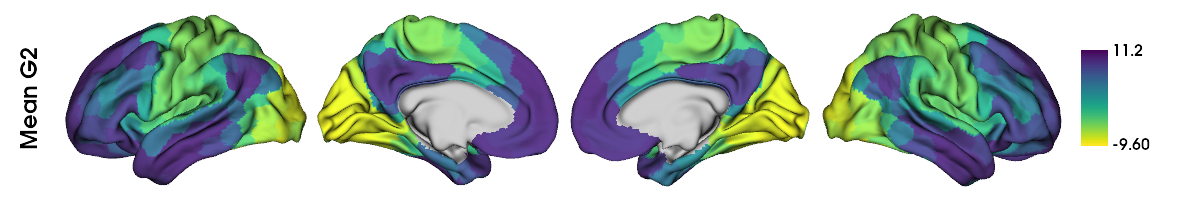

In [271]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = map_to_labels(mean_fc_grad.gradients_[:, 1], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        color_range = (min_loading_across_all_G2, max_loading_across_all_G2),
                        label_text=['Mean G2'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_baseline_mean_G2.svg')

display(plot)

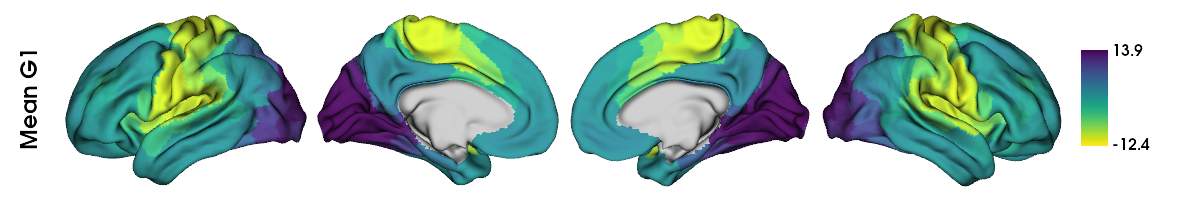

In [273]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = map_to_labels(mean_fc_grad.gradients_[:, 0], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        color_range = (min_loading_across_all_G1, max_loading_across_all_G1),
                        label_text=['Mean G1'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_baseline_mean_G1.svg')

display(plot)

### fu2y

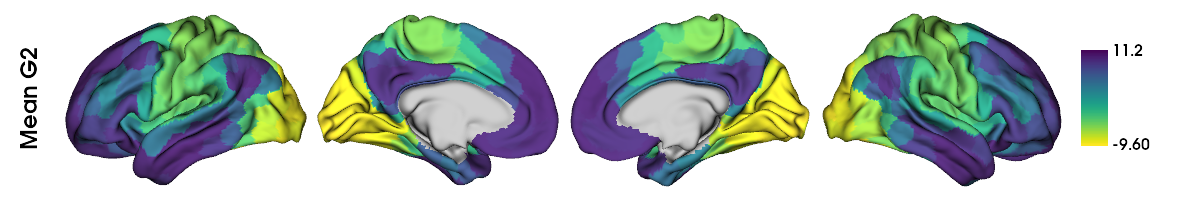

In [275]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = map_to_labels(mean_fc_grad_fu2y.gradients_[:, 1], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        color_range = (min_loading_across_all_G2, max_loading_across_all_G2),
                        label_text=['Mean G2'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_fu2y_mean_G2.svg')

display(plot)

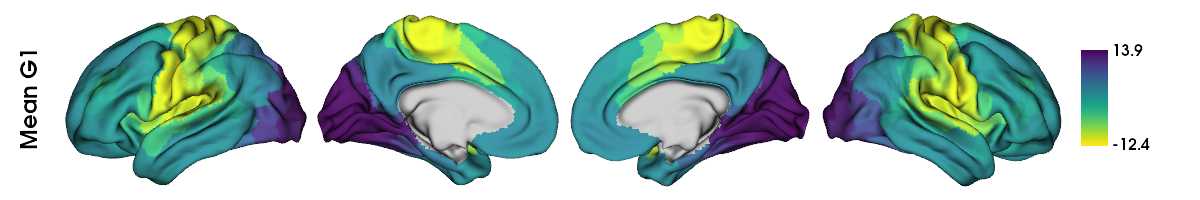

In [277]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = map_to_labels(mean_fc_grad_fu2y.gradients_[:, 0], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        color_range = (min_loading_across_all_G1, max_loading_across_all_G1),
                        label_text=['Mean G1'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_fu2y_mean_G1.svg')

display(plot)

### fu4y

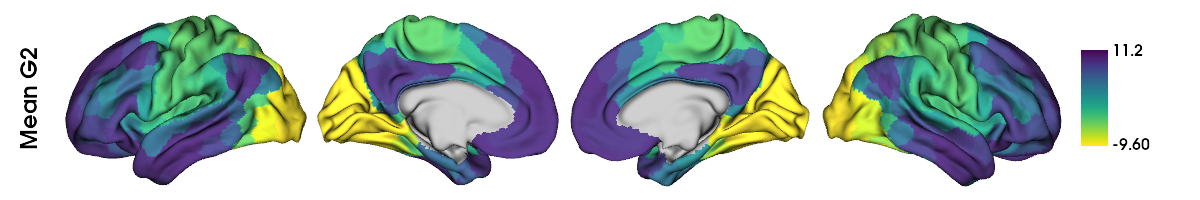

In [279]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = map_to_labels(- mean_fc_grad_fu4y.gradients_[:, 1], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        color_range = (min_loading_across_all_G2, max_loading_across_all_G2),
                        label_text=['Mean G2'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_fu4y_mean_G2.svg')

display(plot)

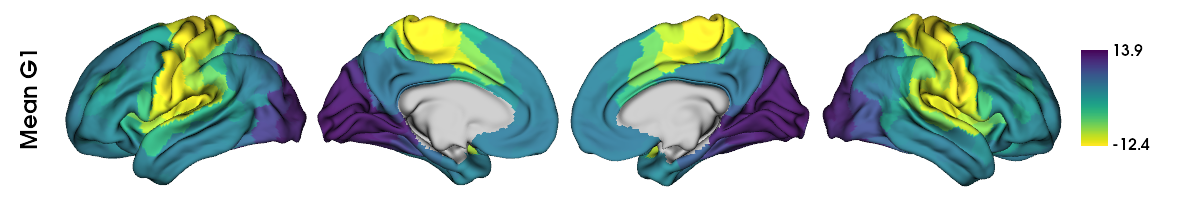

In [281]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = map_to_labels(mean_fc_grad_fu4y.gradients_[:, 0], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        color_range = (min_loading_across_all_G1, max_loading_across_all_G1),
                        label_text=['Mean G1'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_fu4y_mean_G1.svg')

display(plot)

## Correlations between mean gradients

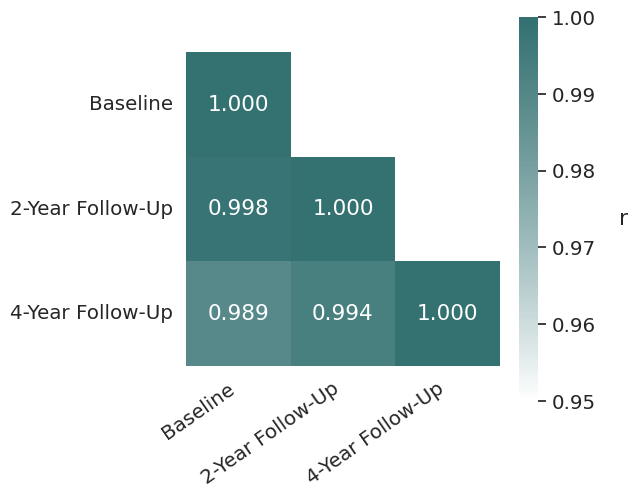

In [266]:
# --- Style setup ---
sns.set_theme(style="white", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Extract gradient vectors ---
g_baseline = mean_fc_grad.gradients_[:, 1]
g_fu2y = mean_fc_grad_fu2y.gradients_[:, 1]
g_fu4y = - mean_fc_grad_fu4y.gradients_[:, 1]

# --- Assemble into DataFrame ---
df_grad = pd.DataFrame({
    "Baseline": g_baseline,
    "2-Year Follow-Up": g_fu2y,
    "4-Year Follow-Up": g_fu4y
})

# --- Compute Spearman correlation matrix ---
corr_mat = df_grad.corr(method="spearman")

# --- Create single-hue colormap with alpha ---
base_color = mcolors.to_rgba("xkcd:dark teal", alpha=0.8)
cmap = mcolors.LinearSegmentedColormap.from_list(
    "indigo_alpha",
    [(1, 1, 1, 1), base_color]
)

# --- Plot heatmap ---
fig, ax = plt.subplots(figsize=(6.5, 5.5))

mask = np.triu(np.ones_like(corr_mat, dtype=bool), k=1)

# --- Apply mask by setting values to NaN ---
corr_plot = corr_mat.mask(mask)

hm = sns.heatmap(
    corr_plot,
    #mask=mask,
    ax=ax,
    cmap=cmap,
    vmin=0.95,
    vmax=1,
    square=True,
    annot=True,
    fmt=".3f",
    #linewidths=0.8,
    linewidths=0,          # <- no gridlines in masked area
    linecolor="black",
    cbar_kws={"label": "r"}
)


# Use mapped labels, only for observed categories
xtick_labels = df_grad.columns
ax.set_xticklabels(xtick_labels, rotation=35, ha="right")

# Rotate colorbar label
cbar = hm.collections[0].colorbar
cbar.set_label("r", rotation=0, labelpad=20)

# --- Improve aesthetics ---
ax.set_xlabel("")
ax.set_ylabel("")

plt.tight_layout()

plt.savefig(resdir_fig+"corr_G2_heatmap.svg", dpi=300, bbox_inches="tight")


In [267]:
# --- Extract gradient vectors ---
g_baseline = mean_fc_grad.gradients_[:, 1]
g_fu2y = mean_fc_grad_fu2y.gradients_[:, 1]
g_fu4y = mean_fc_grad_fu4y.gradients_[:, 1]

spin_test_p, spin_test_d = spin_test(  
        g_baseline, 
        g_fu2y,
        surface_name='fsa5', 
        parcellation_name='schaefer_400',
        type='spearman', 
        n_rot=1000, 
        null_dist=True
    )

print(f"Spin permutation test p-value (baseline-2y): {spin_test_p}")

spin_test_p, spin_test_d = spin_test(  
        g_baseline, 
        g_fu4y,
        surface_name='fsa5', 
        parcellation_name='schaefer_400',
        type='spearman', 
        n_rot=1000, 
        null_dist=True
    )

print(f"Spin permutation test p-value (baseline-4y): {spin_test_p}")

spin_test_p, spin_test_d = spin_test(  
        g_fu2y, 
        g_fu4y,
        surface_name='fsa5', 
        parcellation_name='schaefer_400',
        type='spearman', 
        n_rot=1000, 
        null_dist=True
    )

print(f"Spin permutation test p-value: {spin_test_p}")

print(f"Spin permutation test p-value (2y-4y): {spin_test_p}")

permutation 100 of 1000
permutation 200 of 1000
permutation 300 of 1000
permutation 400 of 1000
permutation 500 of 1000
permutation 600 of 1000
permutation 700 of 1000
permutation 800 of 1000
permutation 900 of 1000
permutation 1000 of 1000
Spin permutation test p-value (baseline-2y): 0.0
permutation 100 of 1000
permutation 200 of 1000
permutation 300 of 1000
permutation 400 of 1000
permutation 500 of 1000
permutation 600 of 1000
permutation 700 of 1000
permutation 800 of 1000
permutation 900 of 1000
permutation 1000 of 1000
Spin permutation test p-value (baseline-4y): 0.0
permutation 100 of 1000
permutation 200 of 1000
permutation 300 of 1000
permutation 400 of 1000
permutation 500 of 1000
permutation 600 of 1000
permutation 700 of 1000
permutation 800 of 1000
permutation 900 of 1000
permutation 1000 of 1000
Spin permutation test p-value: 0.0
Spin permutation test p-value (2y-4y): 0.0


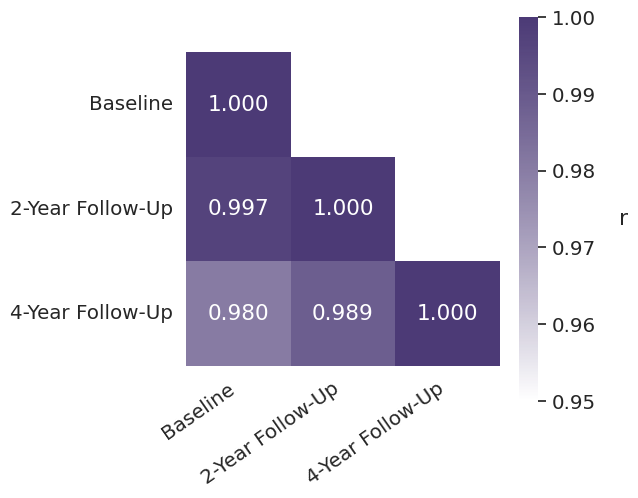

In [268]:
# --- Style setup ---
sns.set_theme(style="white", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Extract gradient vectors ---
g_baseline = mean_fc_grad.gradients_[:, 0]
g_fu2y = mean_fc_grad_fu2y.gradients_[:, 0]
g_fu4y = mean_fc_grad_fu4y.gradients_[:, 0]

# --- Assemble into DataFrame ---
df_grad = pd.DataFrame({
    "Baseline": g_baseline,
    "2-Year Follow-Up": g_fu2y,
    "4-Year Follow-Up": g_fu4y
})

# --- Compute Spearman correlation matrix ---
corr_mat = df_grad.corr(method="spearman")

# --- Create single-hue colormap with alpha ---
base_color = mcolors.to_rgba("xkcd:dark indigo", alpha=0.8)
cmap = mcolors.LinearSegmentedColormap.from_list(
    "indigo_alpha",
    [(1, 1, 1, 1), base_color]
)

# --- Plot heatmap ---
fig, ax = plt.subplots(figsize=(6.5, 5.5))

mask = np.triu(np.ones_like(corr_mat, dtype=bool), k=1)

# --- Apply mask by setting values to NaN ---
corr_plot = corr_mat.mask(mask)

hm = sns.heatmap(
    corr_plot,
    ax=ax,
    cmap=cmap,
    vmin=0.95,
    vmax=1,
    square=True,
    annot=True,
    fmt=".3f",
    #linewidths=0.8,
    linewidths=0,          # <- no gridlines in masked area
    linecolor="black",
    cbar_kws={"label": "r"}
)


# Use mapped labels, only for observed categories
xtick_labels = df_grad.columns
ax.set_xticklabels(xtick_labels, rotation=35, ha="right")

# Rotate colorbar label
cbar = hm.collections[0].colorbar
cbar.set_label("r", rotation=0, labelpad=20)

# --- Improve aesthetics ---
ax.set_xlabel("")
ax.set_ylabel("")

plt.tight_layout()

plt.savefig(resdir_fig+"corr_G1_heatmap.svg", dpi=300, bbox_inches="tight")


In [269]:
# --- Extract gradient vectors ---
g_baseline = mean_fc_grad.gradients_[:, 0]
g_fu2y = mean_fc_grad_fu2y.gradients_[:, 0]
g_fu4y = mean_fc_grad_fu4y.gradients_[:, 0]

spin_test_p, spin_test_d = spin_test(  
        g_baseline, 
        g_fu2y,
        surface_name='fsa5', 
        parcellation_name='schaefer_400',
        type='spearman', 
        n_rot=1000, 
        null_dist=True
    )

print(f"Spin permutation test p-value (baseline-2y): {spin_test_p}")

spin_test_p, spin_test_d = spin_test(  
        g_baseline, 
        g_fu4y,
        surface_name='fsa5', 
        parcellation_name='schaefer_400',
        type='spearman', 
        n_rot=1000, 
        null_dist=True
    )

print(f"Spin permutation test p-value (baseline-4y): {spin_test_p}")

spin_test_p, spin_test_d = spin_test(  
        g_fu2y, 
        g_fu4y,
        surface_name='fsa5', 
        parcellation_name='schaefer_400',
        type='spearman', 
        n_rot=1000, 
        null_dist=True
    )

print(f"Spin permutation test p-value (2y-4y): {spin_test_p}")

permutation 100 of 1000
permutation 200 of 1000
permutation 300 of 1000
permutation 400 of 1000
permutation 500 of 1000
permutation 600 of 1000
permutation 700 of 1000
permutation 800 of 1000
permutation 900 of 1000
permutation 1000 of 1000
Spin permutation test p-value (baseline-2y): 0.0
permutation 100 of 1000
permutation 200 of 1000
permutation 300 of 1000
permutation 400 of 1000
permutation 500 of 1000
permutation 600 of 1000
permutation 700 of 1000
permutation 800 of 1000
permutation 900 of 1000
permutation 1000 of 1000
Spin permutation test p-value (baseline-4y): 0.0
permutation 100 of 1000
permutation 200 of 1000
permutation 300 of 1000
permutation 400 of 1000
permutation 500 of 1000
permutation 600 of 1000
permutation 700 of 1000
permutation 800 of 1000
permutation 900 of 1000
permutation 1000 of 1000
Spin permutation test p-value (2y-4y): 0.0


## Scree plot

In [282]:
sum_lambdas_baseline = np.sum(mean_fc_grad.lambdas_)
sum_lambdas_fu2y = np.sum(mean_fc_grad_fu2y.lambdas_)
sum_lambdas_fu4y = np.sum(mean_fc_grad_fu4y.lambdas_)


scaled_var_explained_mean_grad_baseline = mean_fc_grad.lambdas_ / sum_lambdas_baseline * 100
scaled_var_explained_mean_grad_fu2y = mean_fc_grad_fu2y.lambdas_ / sum_lambdas_fu2y * 100
scaled_var_explained_mean_grad_fu4y = mean_fc_grad_fu4y.lambdas_ / sum_lambdas_fu4y * 100

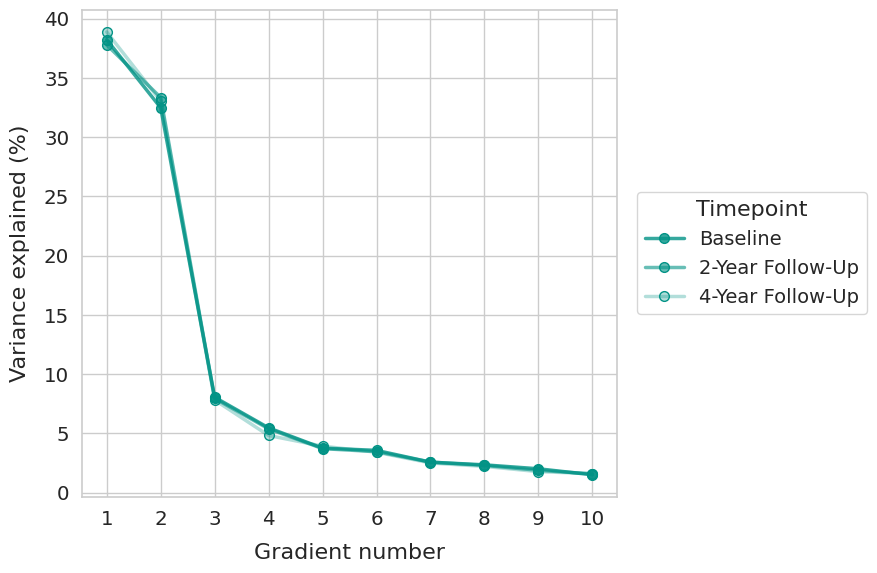

In [283]:
data = [
    scaled_var_explained_mean_grad_baseline,
    scaled_var_explained_mean_grad_fu2y,
    scaled_var_explained_mean_grad_fu4y
]

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]
#alpha_map = {"Baseline": 0.9, "2-Year Follow-Up": 0.5, "4-Year Follow-Up": 0.2} old - yellow

alpha_map = {"Baseline": 0.8, "2-Year Follow-Up": 0.6, "4-Year Follow-Up": 0.3}  # 0.8, 0.6, 0.3

# --- Style setup ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Prepare data ---
x = np.arange(1, 11)  # Gradient numbers 1–10
#color_base = 'xkcd:golden yellow'
color_base = 'xkcd:teal'

# --- Create figure ---
fig, ax = plt.subplots(figsize=(7, 6))

# --- Draw lines and points ---
for i, tp in enumerate(timepoints):
    y = data[i]
    rgba = mcolors.to_rgba(color_base, alpha=alpha_map[tp])
    
    ax.plot(
        x, y, 
        color=rgba, 
        linewidth=2.5, 
        marker='o', 
        markeredgecolor='xkcd:teal',  # prev xkcd:golden yellow
        markersize=7, 
        label=tp
    )

# --- Axis labels, ticks, and legend ---
ax.set_xticks(x)
ax.set_xticklabels(x)
ax.set_xlabel("Gradient number", fontsize=16, labelpad=10)
ax.set_ylabel("Variance explained (%)", fontsize=16, labelpad=10)

#ax.legend(
#    title="Timepoint", frameon=True, facecolor='white',
#    fontsize=14, title_fontsize=16, bbox_to_anchor=(0.95, 0.85)
#)

ax.legend(
    title="Timepoint",
    frameon=True,
    facecolor='white',
    fontsize=14,
    title_fontsize=16,
    loc='center left',
    bbox_to_anchor=(1.02, 0.5)  # (x, y) coordinates relative to the axes
)


plt.tight_layout()
plt.subplots_adjust(right=0.9)

# --- Save figure ---
plt.savefig(resdir_fig + "lineplot_var_explained_mean_grad.svg", format="svg", bbox_inches="tight", dpi=300)

plt.show()


In [284]:
scaled_var_explained_mean_grad_baseline[0:2]

array([38.21946767, 32.47461112])

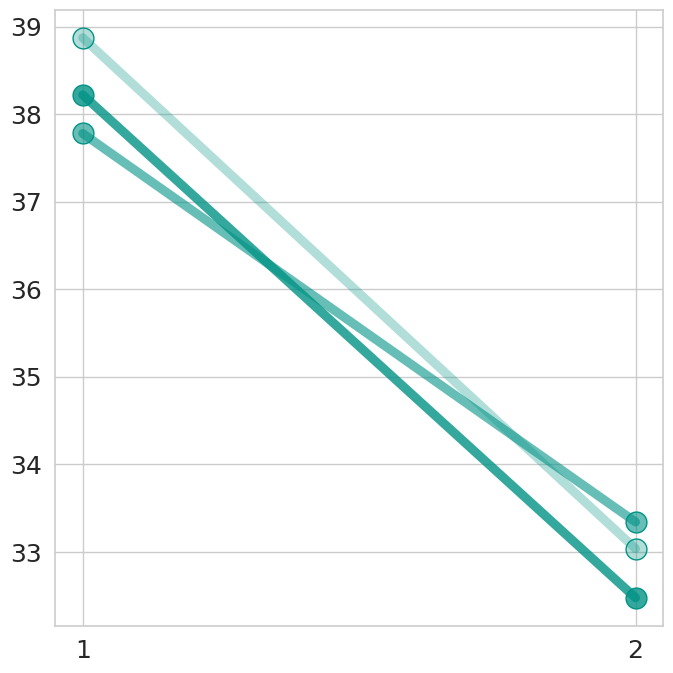

In [285]:
data = [
    scaled_var_explained_mean_grad_baseline[0:2],
    scaled_var_explained_mean_grad_fu2y[0:2],
    scaled_var_explained_mean_grad_fu4y[0:2]
]

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]
#alpha_map = {"Baseline": 0.9, "2-Year Follow-Up": 0.5, "4-Year Follow-Up": 0.2} old - yellow

alpha_map = {"Baseline": 0.8, "2-Year Follow-Up": 0.6, "4-Year Follow-Up": 0.3}  # 0.8, 0.6, 0.3

# --- Style setup ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Prepare data ---
x = np.arange(1, 3)  # Gradient numbers 1–2
#color_base = 'xkcd:golden yellow'
color_base = 'xkcd:teal'

# --- Create figure ---
fig, ax = plt.subplots(figsize=(7, 7))

# --- Draw lines and points ---
for i, tp in enumerate(timepoints):
    y = data[i]
    rgba = mcolors.to_rgba(color_base, alpha=alpha_map[tp])
    
    ax.plot(
        x, y, 
        color=rgba, 
        linewidth=6.5, 
        marker='o', 
        markeredgecolor='xkcd:teal',  # prev xkcd:golden yellow
        markersize=15, 
        label=tp
    )

# --- Axis labels, ticks, and legend --
ax.tick_params(axis='both', labelsize=18)
ax.set_xticks(x)
ax.set_xticklabels(x, fontsize=18)
#ax.set_xlabel("Gradient number", fontsize=16, labelpad=10)
#ax.set_ylabel("Variance explained (%)", fontsize=16, labelpad=10)

#ax.legend(
#    title="Timepoint", frameon=True, facecolor='white',
#    fontsize=14, title_fontsize=16, bbox_to_anchor=(0.95, 0.85)
#)

plt.tight_layout()

# --- Save figure ---
plt.savefig(resdir_fig + "lineplot_var_explained_mean_grad_G1G2_zoom.svg", format="svg", bbox_inches="tight", dpi=300)

plt.show()


## Individual level distance to flip
-> i.e., difference between variance explained by S-A axis vs other gradient

Measure quantifying "how far" from gradient flip (interpretation assuming it's a continuous progression)

Positive value: flip has occured

Negative value: flip has not yet occured

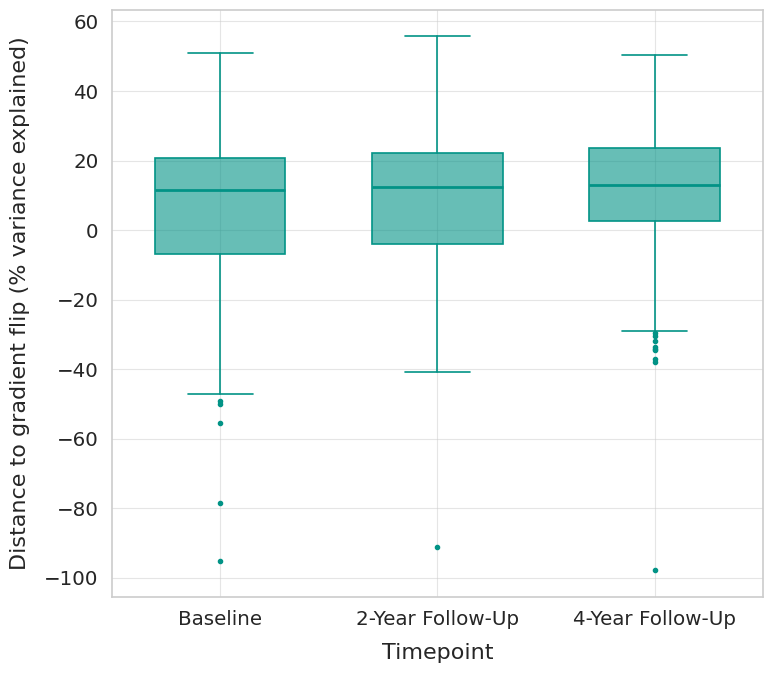

In [286]:
# --- Data setup ---
timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

data = [
    diff_scaled_var_exp_SA_axis_other1_baseline,
    diff_scaled_var_exp_SA_axis_other1_fu2y,
    diff_scaled_var_exp_SA_axis_other1_fu4y
]

#alpha_map = {"Baseline": 0.6, "2-Year Follow-Up": 0.6, "4-Year Follow-Up": 0.6}  # 0.8, 0.6, 0.3
#color_base = 'xkcd:golden yellow'

alpha_map = {"Baseline": 0.6, "2-Year Follow-Up": 0.6, "4-Year Follow-Up": 0.6}  # 0.8, 0.6, 0.3
color_base = 'xkcd:teal'



# --- Style setup (consistent with other figures) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axis ---
fig, ax = plt.subplots(figsize=(8, 7))

# --- Draw boxplots ---
for i, tp in enumerate(timepoints):
    rgba = mcolors.to_rgba(color_base, alpha=alpha_map[tp])
    ax.boxplot(
        data[i],
        positions=[i],
        widths=0.6,
        patch_artist=True,
        boxprops=dict(facecolor=rgba, color=color_base, linewidth=1.2),
        medianprops=dict(color=color_base, linewidth=2),
        whiskerprops=dict(color=color_base, linewidth=1.2),
        capprops=dict(color=color_base, linewidth=1.2),
        flierprops=dict(marker='o', markersize=3, alpha=1,
                        markerfacecolor=color_base, markeredgecolor='xkcd:teal')  # prev xkcd:golden yellow
    )


# --- Formatting ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("Distance to gradient flip (% variance explained)", fontsize=16, labelpad=10)
ax.grid(True, linestyle='-', linewidth=0.8, alpha=0.5)
ax.legend(loc='upper right', frameon=False)

#sns.despine()

plt.tight_layout()

# --- Save figure ---
plt.savefig(resdir_fig + "boxplot_dist_to_flip.svg", format="svg", bbox_inches="tight", dpi=300)
plt.show()


## S-A axis range

In [287]:
print(G1_mean_range)
print(G2_mean_range)

[24.39393469407146, 24.877369765255793, 25.097234944118945]
[17.969002089714355, 19.295737449896887, 20.598843689042205]


In [288]:
### Detecting outliers -> across timepoints

individual_range_all_timpoints = np.concatenate((SA_axis_baseline_individual_range, SA_axis_fu2y_individual_range, SA_axis_fu4y_individual_range), axis=0)

# Compute quartiles
Q1 = np.percentile(individual_range_all_timpoints, 25)
Q3 = np.percentile(individual_range_all_timpoints, 75)
IQR = Q3 - Q1

# Compute cutoff bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1 = {Q1:.2f}, Q3 = {Q3:.2f}, IQR = {IQR:.2f}")
print("\nLower and upper bounds are computed as Q1 - 1.5 * IQR and Q1 + 1.5 * IQR respectively")
print(f"Lower bound = {lower_bound:.2f}")
print(f"Upper bound = {upper_bound:.2f}")

# Identify outliers
outliers_baseline = SA_axis_baseline_individual_range[(SA_axis_baseline_individual_range < lower_bound) | (SA_axis_baseline_individual_range > upper_bound)]
outliers_fu2y = SA_axis_fu2y_individual_range[(SA_axis_fu2y_individual_range < lower_bound) | (SA_axis_fu2y_individual_range > upper_bound)]
outliers_fu4y = SA_axis_fu4y_individual_range[(SA_axis_fu4y_individual_range < lower_bound) | (SA_axis_fu4y_individual_range > upper_bound)]

print("")

print(f"Outliers baseline: {len(outliers_baseline)}:{outliers_baseline}")
print(f"Outliers fu2y: {len(outliers_fu2y)}: {outliers_fu2y}")
print(f"Outliers fu4y: {len(outliers_fu4y)}: {outliers_fu4y}")

print("")

print(f"Max outlier baseline: {np.round(max(SA_axis_baseline_individual_range), 2)}")
print(f"Max outlier fu2y: {np.round(max(SA_axis_fu2y_individual_range), 2)}")
print(f"Max outlier fu4y: {np.round(max(SA_axis_fu4y_individual_range), 2)}")


Q1 = 11.62, Q3 = 17.64, IQR = 6.03

Lower and upper bounds are computed as Q1 - 1.5 * IQR and Q1 + 1.5 * IQR respectively
Lower bound = 2.58
Upper bound = 26.68

Outliers baseline: 39:[ 32.5122698   28.77861266  28.28902642  27.38214255  26.74126284
  27.3751482   27.98697695  27.10852233  26.90547237  26.73654522
  29.50805498  28.87470609  27.25911118  50.12940988  27.14083296
  26.81363102  31.83049289  26.75961626  26.92163462  32.9878446
  27.68810996  29.55787315 385.44475413  27.15563366  27.77643731
  34.78741036  28.8533786   28.12336064  27.80782152  28.27411098
  28.50631286  27.43466737  28.1301927   28.56629402  33.21114849
  34.59658652  27.04153597  32.49738778  27.48965327]
Outliers fu2y: 11: [28.4190264  29.33927613 28.58704678 29.1721418  26.82741643 28.83946295
 28.12272938 26.81922268 27.07039053 38.24108704 30.86986716]
Outliers fu4y: 16: [27.14605347 34.92775474 27.28986419 27.38871998 33.871996   27.92047742
 29.50213628 27.39116048 29.71260862 29.26893353 28.695

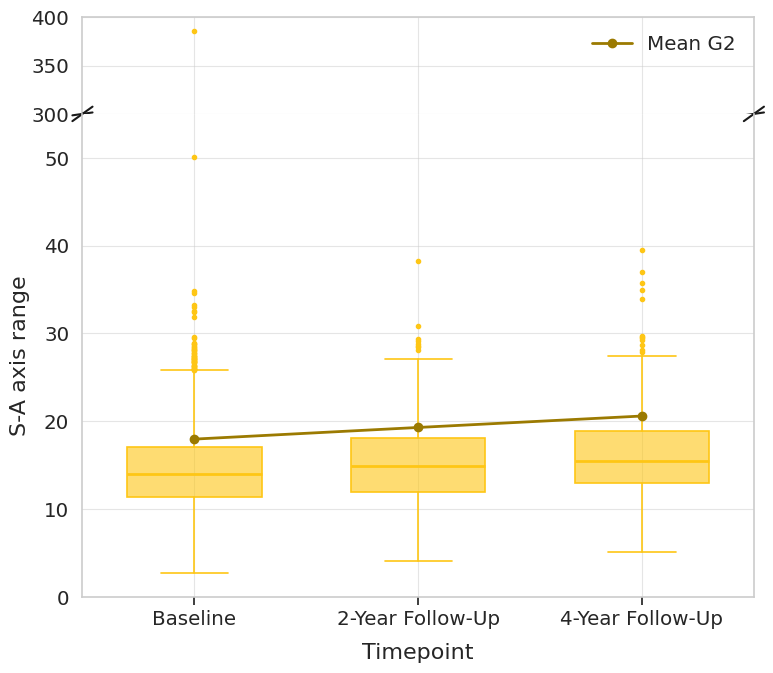

In [289]:
timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

data = [
    SA_axis_baseline_individual_range,
    SA_axis_fu2y_individual_range,
    SA_axis_fu4y_individual_range
]

alpha_map = {"Baseline": 0.6, "2-Year Follow-Up": 0.6, "4-Year Follow-Up": 0.6}  # 0.8, 0.6, 0.3
color_base = 'xkcd:golden yellow'

# --- Style setup (match your other figures) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure with broken axis ---
fig, (ax_top, ax_bottom) = plt.subplots(
    2, 1, sharex=True, figsize=(8, 7),
    gridspec_kw={'height_ratios': [1, 5], 'hspace': 0}
)

# --- Function to draw boxplots with color and alpha ---
def draw_boxplots(ax, data):
    for i, tp in enumerate(timepoints):
        rgba = mcolors.to_rgba(color_base, alpha=alpha_map[tp])
        bp = ax.boxplot(
            data[i],
            positions=[i],
            widths=0.6,
            patch_artist=True,
            boxprops=dict(facecolor=rgba, color=color_base, linewidth=1.2),
            medianprops=dict(color=color_base, linewidth=2),
            whiskerprops=dict(color=color_base, linewidth=1.2),
            capprops=dict(color=color_base, linewidth=1.2),
            flierprops=dict(marker='o', markersize=3, alpha=1, markerfacecolor=color_base, markeredgecolor='xkcd:golden yellow')
        )
    # Overlay mean line
    ax.plot(np.arange(len(timepoints)), G2_mean_range, marker='o', color='xkcd:yellowish brown', linewidth=2, label='Mean G2')
    ax.grid(True, linestyle='-', linewidth=0.8, alpha=0.5)

# --- Draw boxplots ---
draw_boxplots(ax_bottom, data)
draw_boxplots(ax_top, data)

# --- Set y-limits for broken axis ---
ax_bottom.set_ylim(0, 55)
ax_top.set_ylim(300, 400)

# --- Hide spines between axes ---
ax_top.spines.bottom.set_visible(False)
ax_bottom.spines.top.set_visible(False)
ax_top.tick_params(labeltop=False)
ax_bottom.xaxis.tick_bottom()

# --- Diagonal break marks ---
d = .015
kwargs = dict(transform=ax_top.transAxes, color='k', clip_on=False)
ax_top.plot((-d, +d), (-d, +d), **kwargs)
ax_top.plot((1 - d, 1 + d), (-d, +d), **kwargs)
kwargs.update(transform=ax_bottom.transAxes)
ax_bottom.plot((-d, +d), (1 - d, 1 + d), **kwargs)
ax_bottom.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

# --- Axis labels ---
ax_bottom.set_xticks(np.arange(len(timepoints)))
ax_bottom.set_xticklabels(timepoints)
ax_bottom.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax_bottom.set_ylabel("S-A axis range", fontsize=16, labelpad=10)
ax_top.legend(loc='upper right', frameon=False)

# --- Despine and layout ---
#sns.despine(trim=True)
plt.tight_layout(h_pad=0.05)

# --- Save figure ---
plt.savefig(resdir_fig+"boxplot_SA_axis_individual_range.svg", format="svg", bbox_inches="tight", dpi=300)

In [290]:
print("Baseline")
print(f"Min range: {np.min(SA_axis_baseline_individual_range):.2f}")
print(f"Max range: {np.max(SA_axis_baseline_individual_range):.2f}")
print(f"Mean range: {np.mean(SA_axis_baseline_individual_range):.2f}, sd: {np.std(SA_axis_baseline_individual_range):.2f}")
print(f"Median range: {np.median(SA_axis_baseline_individual_range):.2f}")

print("\n2y")
print(f"Min range: {np.min(SA_axis_fu2y_individual_range):.2f}")
print(f"Max range: {np.max(SA_axis_fu2y_individual_range):.2f}")
print(f"Mean range: {np.mean(SA_axis_fu2y_individual_range):.2f}, sd: {np.std(SA_axis_fu2y_individual_range):.2f}")
print(f"Median range: {np.median(SA_axis_fu2y_individual_range):.2f}")

print("\n4y")
print(f"Min range: {np.min(SA_axis_fu4y_individual_range):.2f}")
print(f"Max range: {np.max(SA_axis_fu4y_individual_range):.2f}")
print(f"Mean range: {np.mean(SA_axis_fu4y_individual_range):.2f}, sd: {np.std(SA_axis_fu4y_individual_range):.2f}")
print(f"Median range: {np.median(list_SA_axis_corr_to_ref_fu4y):.2f}")

Baseline
Min range: 2.77
Max range: 385.44
Mean range: 14.56, sd: 7.35
Median range: 13.97

2y
Min range: 4.06
Max range: 38.24
Mean range: 15.24, sd: 4.35
Median range: 14.85

4y
Min range: 5.14
Max range: 39.46
Mean range: 16.03, sd: 4.61
Median range: 0.79


## R coef

In [294]:
### Computing r coef for correlation of mean G2 to adult S-A axis

G2_mean_rcoef = []
G2_mean_rcoef.append(stats.spearmanr(mean_fc_grad.gradients_[:,1], Margulies_gradients_schaefer400[0])[0])
G2_mean_rcoef.append(stats.spearmanr(mean_fc_grad_fu2y.gradients_[:,1], Margulies_gradients_schaefer400[0])[0])
G2_mean_rcoef.append(stats.spearmanr(- mean_fc_grad_fu4y.gradients_[:,1], Margulies_gradients_schaefer400[0])[0])

In [295]:
G2_mean_rcoef

[0.8976042975268594, 0.8912412577578609, 0.8682044887780549]

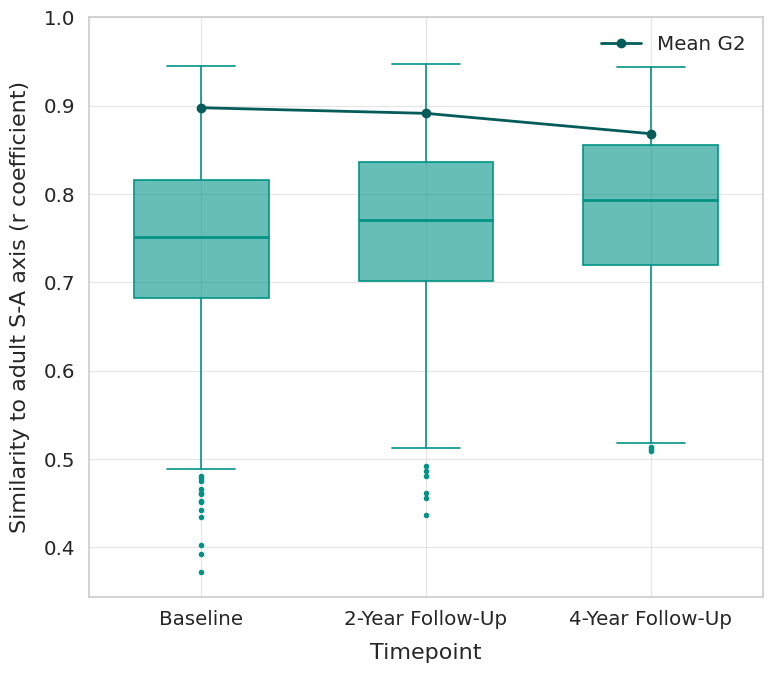

In [296]:
# --- Data setup ---
timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

data = [
    list_SA_axis_corr_to_ref_baseline,
    list_SA_axis_corr_to_ref_fu2y,
    list_SA_axis_corr_to_ref_fu4y
]

alpha_map = {"Baseline": 0.6, "2-Year Follow-Up": 0.6, "4-Year Follow-Up": 0.6}  # 0.8, 0.6, 0.3
color_base = 'xkcd:teal'

# --- Style setup (consistent with other figures) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axis ---
fig, ax = plt.subplots(figsize=(8, 7))

# --- Draw boxplots ---
for i, tp in enumerate(timepoints):
    rgba = mcolors.to_rgba(color_base, alpha=alpha_map[tp])
    ax.boxplot(
        data[i],
        positions=[i],
        widths=0.6,
        patch_artist=True,
        boxprops=dict(facecolor=rgba, color=color_base, linewidth=1.2),
        medianprops=dict(color=color_base, linewidth=2),
        whiskerprops=dict(color=color_base, linewidth=1.2),
        capprops=dict(color=color_base, linewidth=1.2),
        flierprops=dict(marker='o', markersize=3, alpha=1,
                        markerfacecolor=color_base, markeredgecolor='xkcd:teal')
    )

# --- (Optional) Overlay mean line across timepoints ---
ax.plot(np.arange(len(timepoints)), G2_mean_rcoef, marker='o', color='xkcd:dark turquoise', linewidth=2, label='Mean G2')

ax.set_ylim(top=1)

# --- Formatting ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("Similarity to adult S-A axis (r coefficient)", fontsize=16, labelpad=10)
ax.grid(True, linestyle='-', linewidth=0.8, alpha=0.5)
ax.legend(loc='upper right', frameon=False)

#sns.despine()

plt.tight_layout()

# --- Save figure ---
plt.savefig(resdir_fig + "boxplot_rcoef.svg", format="svg", bbox_inches="tight", dpi=300)
plt.show()


In [297]:
print("Baseline")
print(f"Min rcoef: {np.min(list_SA_axis_corr_to_ref_baseline):.2f}")
print(f"Max rcoef: {np.max(list_SA_axis_corr_to_ref_baseline):.2f}")
print(f"Mean rcoef: {np.mean(list_SA_axis_corr_to_ref_baseline):.2f}, sd: {np.std(list_SA_axis_corr_to_ref_baseline):.2f}")
print(f"Median rcoef: {np.median(list_SA_axis_corr_to_ref_baseline):.2f}")

print("\n2y")
print(f"Min rcoef: {np.min(list_SA_axis_corr_to_ref_fu2y):.2f}")
print(f"Max rcoef: {np.max(list_SA_axis_corr_to_ref_fu2y):.2f}")
print(f"Mean rcoef: {np.mean(list_SA_axis_corr_to_ref_fu2y):.2f}, sd: {np.std(list_SA_axis_corr_to_ref_fu2y):.2f}")
print(f"Median rcoef: {np.median(list_SA_axis_corr_to_ref_fu2y):.2f}")

print("\n4y")
print(f"Min rcoef: {np.min(list_SA_axis_corr_to_ref_fu4y):.2f}")
print(f"Max rcoef: {np.max(list_SA_axis_corr_to_ref_fu4y):.2f}")
print(f"Mean rcoef: {np.mean(list_SA_axis_corr_to_ref_fu4y):.2f}, sd: {np.std(list_SA_axis_corr_to_ref_fu4y):.2f}")
print(f"Median rcoef: {np.median(list_SA_axis_corr_to_ref_fu4y):.2f}")

Baseline
Min rcoef: 0.37
Max rcoef: 0.94
Mean rcoef: 0.75, sd: 0.09
Median rcoef: 0.75

2y
Min rcoef: 0.44
Max rcoef: 0.95
Mean rcoef: 0.76, sd: 0.09
Median rcoef: 0.77

4y
Min rcoef: 0.51
Max rcoef: 0.94
Mean rcoef: 0.78, sd: 0.09
Median rcoef: 0.79


## Gradient flip

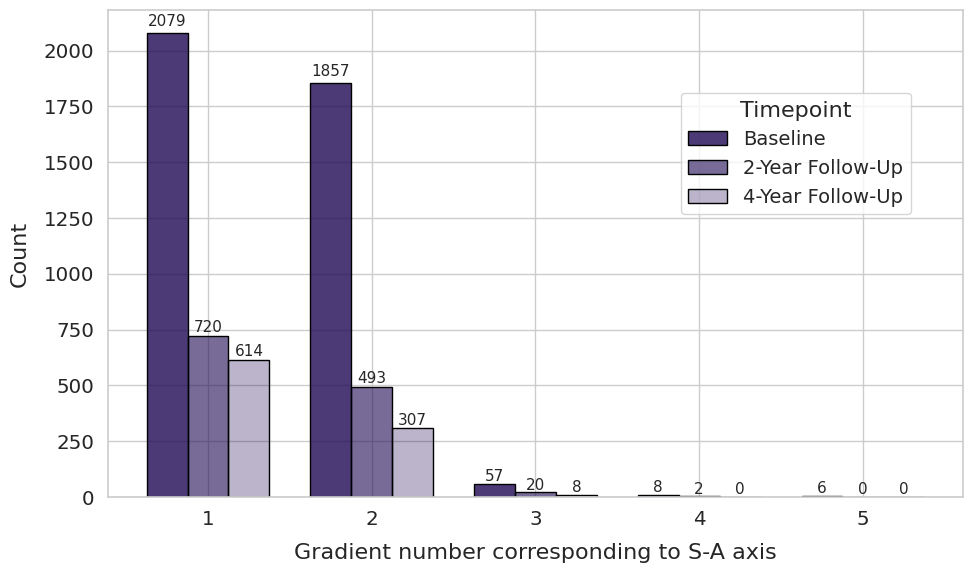

In [298]:
data_counts = [
    Counter(list_SA_axis_grad_num_baseline),
    Counter(list_SA_axis_grad_num_fu2y),
    Counter(list_SA_axis_grad_num_fu4y)
]


timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]
alpha_map = {"Baseline": 0.8, "2-Year Follow-Up": 0.6, "4-Year Follow-Up": 0.3}



# --- Style setup ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Prepare bar plot data ---
keys = sorted(set().union(*[c.keys() for c in data_counts]))
values_matrix = [[c.get(k, 0) for k in keys] for c in data_counts]
x = np.arange(len(keys))
width = 0.25

# --- Create single continuous axis figure ---
fig, ax = plt.subplots(figsize=(10, 6))

# --- Draw bars on single axis ---
for i, tp in enumerate(timepoints):
    values = values_matrix[i]
    rgba = mcolors.to_rgba('xkcd:dark indigo', alpha=alpha_map[tp])
    bar_positions = x + i * width - width

    bars = ax.bar(
        bar_positions, values, width=width,
        color=rgba, edgecolor='black', label=tp
    )

    # Annotate counts on bars
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, val*1.01, str(val),
                ha='center', va='bottom', fontsize=11)

# --- Axis labels and legend ---
ax.set_xticks(x)
ax.set_xticklabels(keys)
ax.set_xlabel("Gradient number corresponding to S-A axis", fontsize=16, labelpad=10)
ax.set_ylabel("Count", fontsize=16, labelpad=10)

ax.legend(title="Timepoint", frameon=True, facecolor='white', fontsize=14, title_fontsize=16, bbox_to_anchor=(0.95, 0.85))

plt.tight_layout()

# --- Save figure ---
plt.savefig(resdir_fig+"barplot_gradient_counts.svg", format="svg", bbox_inches="tight", dpi=300)

plt.show()


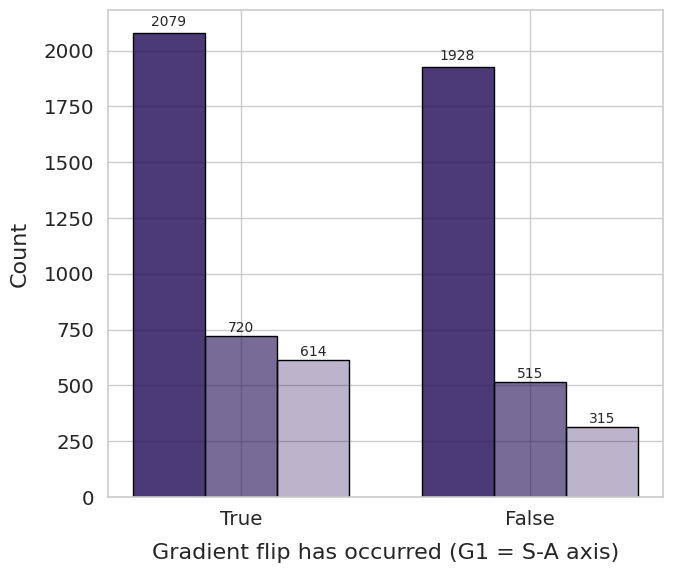

In [299]:
import matplotlib.colors as mcolors


# creating new lists of just 0s and 1s for if gradient flip has occurred or not: 1 True; 0 False
grad_flip_baseline = [True if x == 1 else False for x in list_SA_axis_grad_num_baseline]
grad_flip_fu2y = [True if x == 1 else False for x in list_SA_axis_grad_num_fu2y]
grad_flip_fu4y = [True if x == 1 else False for x in list_SA_axis_grad_num_fu4y]


# --- Count occurrences ---
data_counts = [
    Counter(grad_flip_baseline),
    Counter(grad_flip_fu2y),
    Counter(grad_flip_fu4y)
]

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]
alpha_map = {"Baseline": 0.8, "2-Year Follow-Up": 0.6, "4-Year Follow-Up": 0.3}

# --- Style setup ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Prepare bar plot data ---
keys = sorted(set().union(*[c.keys() for c in data_counts]), reverse=True)
values_matrix = [[c.get(k, 0) for k in keys] for c in data_counts]
x = np.arange(len(keys))
width = 0.25

# --- Create single figure/axis ---
fig, ax = plt.subplots(figsize=(7, 6))

# --- Draw bars ---
for i, tp in enumerate(timepoints):
    values = values_matrix[i]
    rgba = mcolors.to_rgba('xkcd:dark indigo', alpha=alpha_map[tp])
    bar_positions = x + i * width - width

    bars = ax.bar(
        bar_positions, values, width=width,
        color=rgba, edgecolor='black', label=tp
    )

    # Annotate counts
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, val * 1.01, str(val),
                ha='center', va='bottom', fontsize=10)

# --- Axis formatting ---
ax.set_xticks(x)
ax.set_xticklabels(keys)
ax.set_xlabel("Gradient flip has occurred (G1 = S-A axis)", fontsize=16, labelpad=10)
ax.set_ylabel("Count", fontsize=16, labelpad=10)
#ax.legend(title="Timepoint", frameon=True, facecolor='white',fontsize=14, title_fontsize=16, bbox_to_anchor=(1.5, 0.85))

#sns.despine()
plt.tight_layout()

# --- Save figure ---
plt.savefig(resdir_fig + "barplot_gradflip_counts.svg", format="svg", bbox_inches="tight", dpi=300)
plt.show()


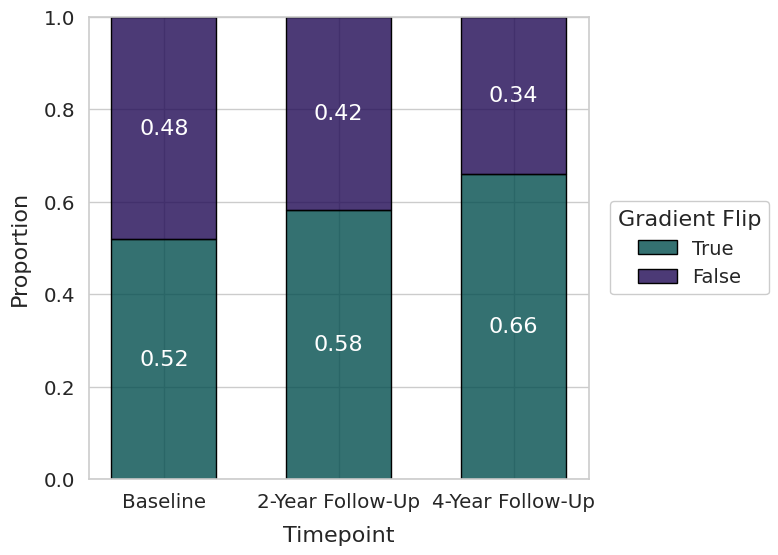

In [300]:
import matplotlib.colors as mcolors
from collections import Counter
from matplotlib.patches import Patch

# creating new lists of just True/False for if gradient flip has occurred or not
grad_flip_baseline = [True if x == 1 else False for x in list_SA_axis_grad_num_baseline]
grad_flip_fu2y = [True if x == 1 else False for x in list_SA_axis_grad_num_fu2y]
grad_flip_fu4y = [True if x == 1 else False for x in list_SA_axis_grad_num_fu4y]

# --- Count occurrences ---
data_counts = [
    Counter(grad_flip_baseline),
    Counter(grad_flip_fu2y),
    Counter(grad_flip_fu4y)
]

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]
alpha_map = {"Baseline": 0.8, "2-Year Follow-Up": 0.8, "4-Year Follow-Up": 0.8}  # 0.8, 0.6, 0.4

# --- Convert counts to proportions ---
data_props = []
for c in data_counts:
    total = sum(c.values())
    data_props.append({
        True: c.get(True, 0) / total,
        False: c.get(False, 0) / total
    })

# --- Style setup ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Create single figure/axis ---
fig, ax = plt.subplots(figsize=(8, 6))

x = np.arange(len(timepoints))
bar_width = 0.6

# --- Draw stacked bars ---
for i, tp in enumerate(timepoints):

    rgba_f = mcolors.to_rgba("xkcd:dark indigo", alpha=alpha_map[tp])  # False
    rgba_t = mcolors.to_rgba("xkcd:dark teal", alpha=alpha_map[tp])    # True

    false_prop = data_props[i][False]
    true_prop = data_props[i][True]

    # Bottom = True
    ax.bar(
        x[i],
        true_prop,
        width=bar_width,
        color=rgba_t,
        edgecolor="black"
    )

    # Top = False (stacked)
    ax.bar(
        x[i],
        false_prop,
        bottom=true_prop,
        width=bar_width,
        color=rgba_f,
        edgecolor="black"
    )

    # --- Proportion annotations (now correctly matched) ---
    ax.text(x[i], true_prop / 2, f"{true_prop:.2f}",
            ha="center", va="center", fontsize=16, color="white")

    ax.text(x[i], true_prop + false_prop / 2, f"{false_prop:.2f}",
            ha="center", va="center", fontsize=16, color="white")

# --- Axis formatting ---
ax.set_xticks(x)
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("Proportion", fontsize=16, labelpad=10)
ax.set_ylim(0, 1)

# --- Legend for True / False ---
legend_elements = [
    Patch(facecolor=mcolors.to_rgba("xkcd:dark teal", 0.8), edgecolor="black", label="True"),
    Patch(facecolor=mcolors.to_rgba("xkcd:dark indigo", 0.8), edgecolor="black", label="False"),
]
#ax.legend(handles=legend_elements, title="Gradient Flip", frameon=False, loc="upper right")


ax.legend(
    handles=legend_elements,
    title="Gradient Flip",
    bbox_to_anchor=(1.38, 0.5),
    loc="center right",
    frameon=True,  # enable the frame
    facecolor='white',       # background color
    #edgecolor='grey',       # border color
    framealpha=1,          # opacity of the frame (1.0 = opaque)
    fontsize=14,
    title_fontsize=16
)

plt.subplots_adjust(right=0.75)  # <-- makes room for legend outside
#plt.tight_layout()

# --- Save figure ---
plt.savefig(
    resdir_fig + "barplot_gradflip_proportions_stacked.svg",
    format="svg",
    bbox_inches="tight",
    dpi=300
)

plt.show()


In [301]:
# computing the flip occurence ratio (occured over not occured -> True / False) by timepoint
# True = 1; False = 0

flip_occurence_ratio_baseline = Counter(grad_flip_baseline)[1] / Counter(grad_flip_baseline)[0]
flip_occurence_ratio_fu2y = Counter(grad_flip_fu2y)[1] / Counter(grad_flip_fu2y)[0]
flip_occurence_ratio_fu4y = Counter(grad_flip_fu4y)[1] / Counter(grad_flip_fu4y)[0]

print(f"Flip occurence ratio:")
print(f"Baseline: {round(flip_occurence_ratio_baseline, 2)}")
print(f"Fu2y: {round(flip_occurence_ratio_fu2y, 2)}")
print(f"Fu4y: {round(flip_occurence_ratio_fu4y, 2)}")

Flip occurence ratio:
Baseline: 1.08
Fu2y: 1.4
Fu4y: 1.95


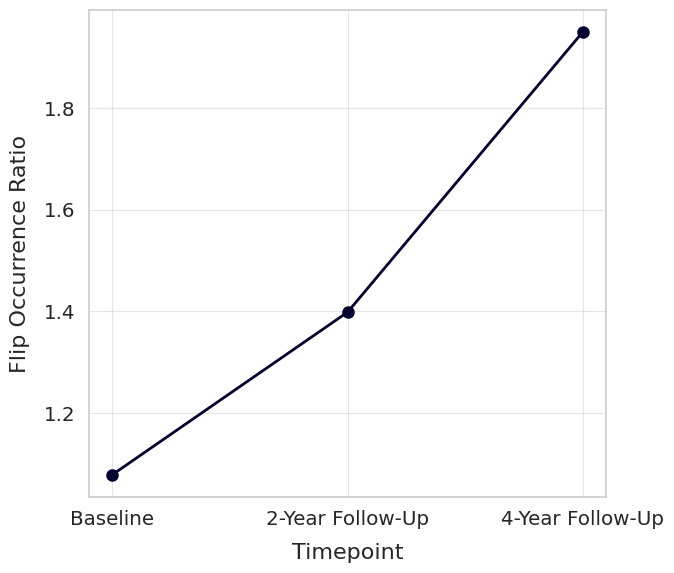

In [302]:

# --- Data setup ---
timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

data = [
    flip_occurence_ratio_baseline,
    flip_occurence_ratio_fu2y,
    flip_occurence_ratio_fu4y
]

# --- Style setup (match your other figures) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Create figure and axis ---
fig, ax = plt.subplots(figsize=(7, 6))

# --- Plot line ---
x = np.arange(len(timepoints))
ax.plot(
    x, data,
    marker='o',
    markersize=8,
    color='xkcd:midnight',
    linewidth=2
)

# --- Axis formatting ---
ax.set_xticks(x)
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("Flip Occurrence Ratio", fontsize=16, labelpad=10)
ax.grid(True, linestyle='-', linewidth=0.8, alpha=0.5)
#sns.despine()

plt.tight_layout()

# --- Save figure ---
plt.savefig(resdir_fig + "lineplot_flip_occurrence_ratio.svg", format="svg", bbox_inches="tight", dpi=300)
plt.show()


#
#
#
#
# FC strength

## Computing mean FC strength (of top 10%) by region

### Baseline

In [221]:
fc_matrices_baseline.shape

(4007, 400, 400)

In [222]:

### lists that will contain the fc strengths for 10% connections at the individual level
# for all subjects (N x 400 x 20)
fc_strengths_top10_baseline = []


# iterate over subjects
for i in range(len(fc_matrices_baseline)):
    print(f"----- subject = {i} ----")

    # temporary list for each subject's fc_strengths_top10_baseline matrix
    sub_fc_strengths_top10_baseline = []

    # iterate over each row of the subject's fc 400x400 matrix 
    for j in range(len(fc_matrices_baseline[0])):

        # identify the indices of the top 10% functional connections i.e., top 40 connections (10% of 400)
        # code explanation available at: https://www.educative.io/answers/how-to-get-indices-of-n-maximum-values-in-numpy-arrays
        # retrieving indices from subject i and row j of the fc matrix
            
        indices_top_fc = np.argsort(fc_matrices_baseline[i][j])[::-1][:40]
            
            
        # temporary list for row of subject's fc_strengths_top10_baseline matrix
        sub_row_fc_strengths_top10_baseline = []
        
        # iterate over each parcel of subject's 400-parcel-long row
        for k in range(len(fc_matrices_baseline[0][0])):
                
            # if parcel belongs to one of the top 10% connections, assign it's value to list for row of subject's fc_strengths_most_frequent_connections matrix 
            if k in indices_top_fc:
                sub_row_fc_strengths_top10_baseline.append(fc_matrices_baseline[i][j][k])
        

        # append temporary list for row of subject's binary_top_fc matrix to subject's temporary list
        sub_fc_strengths_top10_baseline.append(sub_row_fc_strengths_top10_baseline)

    # append current subject's list of binary_top_fc to list containing all subjects
    fc_strengths_top10_baseline.append(sub_fc_strengths_top10_baseline)
            
            
fc_strengths_top10_baseline = np.array(fc_strengths_top10_baseline)


----- subject = 0 ----
----- subject = 1 ----
----- subject = 2 ----
----- subject = 3 ----
----- subject = 4 ----
----- subject = 5 ----
----- subject = 6 ----
----- subject = 7 ----
----- subject = 8 ----
----- subject = 9 ----
----- subject = 10 ----
----- subject = 11 ----
----- subject = 12 ----
----- subject = 13 ----
----- subject = 14 ----
----- subject = 15 ----
----- subject = 16 ----
----- subject = 17 ----
----- subject = 18 ----
----- subject = 19 ----
----- subject = 20 ----
----- subject = 21 ----
----- subject = 22 ----
----- subject = 23 ----
----- subject = 24 ----
----- subject = 25 ----
----- subject = 26 ----
----- subject = 27 ----
----- subject = 28 ----
----- subject = 29 ----
----- subject = 30 ----
----- subject = 31 ----
----- subject = 32 ----
----- subject = 33 ----
----- subject = 34 ----
----- subject = 35 ----
----- subject = 36 ----
----- subject = 37 ----
----- subject = 38 ----
----- subject = 39 ----
----- subject = 40 ----
----- subject = 41 ----
--

In [223]:
fc_strengths_top10_baseline.shape

(4007, 400, 40)

In [224]:
# take the mean across the top 10% connections 
mean_fc_strengths_baseline = fc_strengths_top10_baseline.mean(axis=2) # shape (N, 400)

In [225]:
mean_fc_strengths_baseline.shape

(4007, 400)

### Fu2y

In [226]:
fc_matrices_fu2y.shape

(1235, 400, 400)

In [227]:
### lists that will contain the fc strengths for 10% connections at the individual level
# for all subjects (N x 400 x 20)
fc_strengths_top10_fu2y = []


# iterate over subjects
for i in range(len(fc_matrices_fu2y)):
    print(f"----- subject = {i} ----")

    # temporary list for each subject's fc_strengths_top10_fu2y matrix
    sub_fc_strengths_top10_fu2y = []

    # iterate over each row of the subject's fc 400x400 matrix 
    for j in range(len(fc_matrices_fu2y[0])):

        # identify the indices of the top 10% functional connections i.e., top 40 connections (10% of 400)
        # code explanation available at: https://www.educative.io/answers/how-to-get-indices-of-n-maximum-values-in-numpy-arrays
        # retrieving indices from subject i and row j of the fc matrix
            
        indices_top_fc = np.argsort(fc_matrices_fu2y[i][j])[::-1][:40]
            
            
        # temporary list for row of subject's fc_strengths_top10_fu2y matrix
        sub_row_fc_strengths_top10_fu2y = []
        
        # iterate over each parcel of subject's 400-parcel-long row
        for k in range(len(fc_matrices_fu2y[0][0])):
                
            # if parcel belongs to one of the top 10% connections, assign it's value to list for row of subject's fc_strengths_most_frequent_connections matrix 
            if k in indices_top_fc:
                sub_row_fc_strengths_top10_fu2y.append(fc_matrices_fu2y[i][j][k])
        

        # append temporary list for row of subject's binary_top_fc matrix to subject's temporary list
        sub_fc_strengths_top10_fu2y.append(sub_row_fc_strengths_top10_fu2y)

    # append current subject's list of binary_top_fc to list containing all subjects
    fc_strengths_top10_fu2y.append(sub_fc_strengths_top10_fu2y)
            
            
fc_strengths_top10_fu2y = np.array(fc_strengths_top10_fu2y)


----- subject = 0 ----
----- subject = 1 ----
----- subject = 2 ----
----- subject = 3 ----
----- subject = 4 ----
----- subject = 5 ----
----- subject = 6 ----
----- subject = 7 ----
----- subject = 8 ----
----- subject = 9 ----
----- subject = 10 ----
----- subject = 11 ----
----- subject = 12 ----
----- subject = 13 ----
----- subject = 14 ----
----- subject = 15 ----
----- subject = 16 ----
----- subject = 17 ----
----- subject = 18 ----
----- subject = 19 ----
----- subject = 20 ----
----- subject = 21 ----
----- subject = 22 ----
----- subject = 23 ----
----- subject = 24 ----
----- subject = 25 ----
----- subject = 26 ----
----- subject = 27 ----
----- subject = 28 ----
----- subject = 29 ----
----- subject = 30 ----
----- subject = 31 ----
----- subject = 32 ----
----- subject = 33 ----
----- subject = 34 ----
----- subject = 35 ----
----- subject = 36 ----
----- subject = 37 ----
----- subject = 38 ----
----- subject = 39 ----
----- subject = 40 ----
----- subject = 41 ----
--

In [228]:
fc_strengths_top10_fu2y.shape

(1235, 400, 40)

In [229]:
# take the mean across the top 10% connections 
mean_fc_strengths_fu2y = fc_strengths_top10_fu2y.mean(axis=2) # shape (N, 400)

In [230]:
mean_fc_strengths_fu2y.shape

(1235, 400)

### Fu4y

In [231]:
fc_matrices_fu4y.shape

(929, 400, 400)

In [232]:

### lists that will contain the fc strengths for 10% connections at the individual level
# for all subjects (N x 400 x 20)
fc_strengths_top10_fu4y = []


# iterate over subjects
for i in range(len(fc_matrices_fu4y)):
    print(f"----- subject = {i} ----")

    # temporary list for each subject's fc_strengths_top10_fu4y matrix
    sub_fc_strengths_top10_fu4y = []

    # iterate over each row of the subject's fc 400x400 matrix 
    for j in range(len(fc_matrices_fu4y[0])):

        # identify the indices of the top 10% functional connections i.e., top 40 connections (10% of 400)
        # code explanation available at: https://www.educative.io/answers/how-to-get-indices-of-n-maximum-values-in-numpy-arrays
        # retrieving indices from subject i and row j of the fc matrix
            
        indices_top_fc = np.argsort(fc_matrices_fu4y[i][j])[::-1][:40]
            
            
        # temporary list for row of subject's fc_strengths_top10_fu4y matrix
        sub_row_fc_strengths_top10_fu4y = []
        
        # iterate over each parcel of subject's 400-parcel-long row
        for k in range(len(fc_matrices_fu4y[0][0])):
                
            # if parcel belongs to one of the top 10% connections, assign it's value to list for row of subject's fc_strengths_most_frequent_connections matrix 
            if k in indices_top_fc:
                sub_row_fc_strengths_top10_fu4y.append(fc_matrices_fu4y[i][j][k])
        

        # append temporary list for row of subject's binary_top_fc matrix to subject's temporary list
        sub_fc_strengths_top10_fu4y.append(sub_row_fc_strengths_top10_fu4y)

    # append current subject's list of binary_top_fc to list containing all subjects
    fc_strengths_top10_fu4y.append(sub_fc_strengths_top10_fu4y)
            
            
fc_strengths_top10_fu4y = np.array(fc_strengths_top10_fu4y)


----- subject = 0 ----
----- subject = 1 ----
----- subject = 2 ----
----- subject = 3 ----
----- subject = 4 ----
----- subject = 5 ----
----- subject = 6 ----
----- subject = 7 ----
----- subject = 8 ----
----- subject = 9 ----
----- subject = 10 ----
----- subject = 11 ----
----- subject = 12 ----
----- subject = 13 ----
----- subject = 14 ----
----- subject = 15 ----
----- subject = 16 ----
----- subject = 17 ----
----- subject = 18 ----
----- subject = 19 ----
----- subject = 20 ----
----- subject = 21 ----
----- subject = 22 ----
----- subject = 23 ----
----- subject = 24 ----
----- subject = 25 ----
----- subject = 26 ----
----- subject = 27 ----
----- subject = 28 ----
----- subject = 29 ----
----- subject = 30 ----
----- subject = 31 ----
----- subject = 32 ----
----- subject = 33 ----
----- subject = 34 ----
----- subject = 35 ----
----- subject = 36 ----
----- subject = 37 ----
----- subject = 38 ----
----- subject = 39 ----
----- subject = 40 ----
----- subject = 41 ----
--

In [233]:
fc_strengths_top10_fu4y.shape

(929, 400, 40)

In [234]:
# take the mean across the top 10% connections 
mean_fc_strengths_fu4y = fc_strengths_top10_fu4y.mean(axis=2) # shape (N, 400)

In [235]:
mean_fc_strengths_fu4y.shape

(929, 400)

## Computing summary measure of mean FC strength

### Averaging mean FC strength across networks

#### Baseline

In [236]:
fc = mean_fc_strengths_baseline   # shape (N, 400)

fc_network_baseline = np.zeros((fc.shape[0], 7))

for n in range(7):
    network_indices = yeo7_networks_array == n+1
    fc_network_baseline[:, n] = fc[:, network_indices].mean(axis=1)

In [237]:
fc_network_baseline.shape

(4007, 7)

#### Fu2y

In [238]:
fc = mean_fc_strengths_fu2y   # shape (N, 400)

fc_network_fu2y = np.zeros((fc.shape[0], 7))

for n in range(7):
    network_indices = yeo7_networks_array == n+1
    fc_network_fu2y[:, n] = fc[:, network_indices].mean(axis=1)

In [239]:
fc_network_fu2y.shape

(1235, 7)

#### Fu4y

In [240]:
fc = mean_fc_strengths_fu4y   # shape (N, 400)

fc_network_fu4y = np.zeros((fc.shape[0], 7))

for n in range(7):
    network_indices = yeo7_networks_array == n+1
    fc_network_fu4y[:, n] = fc[:, network_indices].mean(axis=1)

In [241]:
fc_network_fu4y.shape

(929, 7)

### Averaging mean FC strength across bins

#### Creating index list (bin labels) for 10 bins based on S-A axis position (adult S-A axis)

In [242]:
grad = Margulies_gradients_schaefer400[0]   # shape (400,)

# Create bin edges (deciles)
bin_edges_adult = np.percentile(grad, np.linspace(0, 100, 11))

# Assign each region to a bin (0–9)
bin_labels_adult = np.digitize(grad, bin_edges_adult[1:-1])

#### Baseline

In [243]:
fc = mean_fc_strengths_baseline

fc_binned_baseline = np.zeros((fc.shape[0], 10))

for b in range(10):
    region_indices = bin_labels_adult == b
    fc_binned_baseline[:, b] = fc[:, region_indices].mean(axis=1)

In [244]:
fc_binned_baseline.shape

(4007, 10)

#### Fu2y

In [245]:
fc = mean_fc_strengths_fu2y

fc_binned_fu2y = np.zeros((fc.shape[0], 10))

for b in range(10):
    region_indices = bin_labels_adult == b
    fc_binned_fu2y[:, b] = fc[:, region_indices].mean(axis=1)

In [246]:
fc_binned_fu2y.shape

(1235, 10)

#### Fu4y

In [247]:
fc = mean_fc_strengths_fu4y

fc_binned_fu4y = np.zeros((fc.shape[0], 10))

for b in range(10):
    region_indices = bin_labels_adult == b
    fc_binned_fu4y[:, b] = fc[:, region_indices].mean(axis=1)

In [248]:
fc_binned_fu4y.shape

(929, 10)

## Exporting

In [249]:
# export as matfile
mdict = {'fc_network_baseline': fc_network_baseline, 'fc_binned_baseline': fc_binned_baseline, 'mean_fc_strengths_baseline': mean_fc_strengths_baseline, 'sub_ID_baseline': sub_ID_baseline, 
        }

scipy.io.savemat(datadir_local_pds_cleaned+'fc_strength_network_bin_baseline.mat', mdict)

In [250]:
# export as matfile
mdict = {'fc_network_fu2y': fc_network_fu2y, 'fc_binned_fu2y': fc_binned_fu2y, 'mean_fc_strengths_fu2y': mean_fc_strengths_fu2y, 'sub_ID_fu2y': sub_ID_fu2y, 
        }

scipy.io.savemat(datadir_local_pds_cleaned+'fc_strength_network_bin_fu2y.mat', mdict)

In [251]:
# export as matfile
mdict = {'fc_network_fu4y': fc_network_fu4y, 'fc_binned_fu4y': fc_binned_fu4y, 'mean_fc_strengths_fu4y': mean_fc_strengths_fu4y, 'sub_ID_fu4y': sub_ID_fu4y, 
        }

scipy.io.savemat(datadir_local_pds_cleaned+'fc_strength_network_bin_fu4y.mat', mdict)